## 0. Instalasi dan konfigurasi

In [1]:
!pip install -q xgboost shap gradio statsmodels

In [2]:
import os, warnings, joblib
from collections import defaultdict, deque
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, brier_score_loss, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42

# ===== KONFIGURASI (silakan ubah) =====
START_YEAR, END_YEAR = 2000, 2026        # rentang data dimuat (Elo dihangatkan sejak START_YEAR)
TRAIN_START_YEAR = 2010                  # data latih dimulai dari tahun ini
TEST_START_DATE = "2023-01-01"           # data uji = pertandingan sejak tanggal ini
MIN_PRIOR_MATCHES = 10                   # aturan cold-start: kedua pemain min. 10 laga sebelumnya
DROP_RETIRED = True                      # buang laga RET (mundur di tengah pertandingan)
N_TUNE = 12000                           # jumlah baris terbaru untuk tuning (agar SVM tidak terlalu lambat)
N_ITER = 60                              # maks. kombinasi hyperparameter per model (jika ruang lebih kecil, seluruh ruang dicoba)
DATA_URL = "https://huggingface.co/datasets/Aneeshers/tennis-sackmann-archive/resolve/main/atp"   # mirror arsip data Jeff Sackmann
SAVE_DIR = "/content/model_tenis"        # ganti ke '/content/drive/MyDrive/model_tenis' jika Drive di-mount
os.makedirs(SAVE_DIR, exist_ok=True)

## 1. Memuat dan membersihkan data

In [ ]:
frames = []
for y in range(START_YEAR, END_YEAR + 1):
    try:
        frames.append(pd.read_csv(f"{DATA_URL}/atp_matches_{y}.csv"))
    except Exception as e:
        print(f"Gagal memuat {y}: {type(e).__name__}: {str(e)[:100]}")

if not frames:
    raise RuntimeError("Data tidak bisa dimuat. Pastikan internet Colab aktif, lalu jalankan ulang sel ini.")
print("Tahun berhasil dimuat:", len(frames), "dari", END_YEAR - START_YEAR + 1)
raw = pd.concat(frames, ignore_index=True)
print("Total baris mentah:", len(raw))

df = raw.copy()
df["tourney_date"] = pd.to_datetime(df["tourney_date"].astype(int).astype(str), format="%Y%m%d")

# buang baris tanpa info penting
df = df.dropna(subset=["surface", "winner_id", "loser_id", "winner_rank", "loser_rank"])

# buang walkover / default (dan opsional retired)
score = df["score"].fillna("")
bad = score.str.contains("W/O|DEF")
if DROP_RETIRED:
    bad |= score.str.contains("RET")
df = df[~bad]

# urutkan kronologis (penting untuk feature engineering tanpa leakage)
ROUND_ORDER = {"R128": 1, "R64": 2, "R32": 3, "R16": 4, "RR": 4, "QF": 5, "SF": 6, "BR": 6, "F": 7}
df["round_order"] = df["round"].map(ROUND_ORDER).fillna(0)
df = df.sort_values(["tourney_date", "round_order", "match_num"]).reset_index(drop=True)
print("Baris setelah pembersihan:", len(df))
df[["tourney_date", "surface", "round", "winner_name", "loser_name", "winner_rank", "loser_rank"]].head()

Tahun berhasil dimuat: 27 dari 27
Total baris mentah: 79299
Baris setelah pembersihan: 74674


,tourney_date,surface,round,winner_name,loser_name,winner_rank,loser_rank
0,2000-01-03,Hard,R32,Thomas Enqvist,Arnaud Clement,4.0,56.0
1,2000-01-03,Hard,R32,Nicolas Kiefer,Jeff Tarango,6.0,55.0
2,2000-01-03,Hard,R32,Michal Tabara,Yevgeny Kafelnikov,123.0,2.0
3,2000-01-03,Hard,R32,Roger Federer,Jens Knippschild,64.0,91.0
4,2000-01-03,Hard,R32,Cristiano Caratti,Ivo Heuberger,213.0,221.0


## 2. Feature engineering (tanpa data leakage)

In [3]:
def _elo0(): return 1500.0
def _deque10(): return deque(maxlen=10)
def _deque60(): return deque(maxlen=60)
def _list(): return []

def expected(a, b):
    return 1.0 / (1.0 + 10 ** ((b - a) / 400.0))

class Tracker:
    """Menyimpan status setiap pemain (Elo, form, H2H, kelelahan, dll.) secara kronologis."""
    def __init__(self):
        self.elo = defaultdict(_elo0)          # Elo umum
        self.elo_s = defaultdict(_elo0)        # Elo per permukaan: key (pid, surface)
        self.n = defaultdict(int)              # jumlah laga
        self.n_s = defaultdict(int)            # jumlah laga per permukaan
        self.wins_s = defaultdict(int)         # kemenangan per permukaan
        self.form = defaultdict(_deque10)      # hasil 10 laga terakhir (1/0)
        self.load = defaultdict(_deque60)      # (tanggal, menit bermain)
        self.h2h = defaultdict(int)            # (a, b) -> jumlah kemenangan a atas b
        self.bio = {}                          # data terakhir pemain (untuk prediksi)
        self.elo_hist = defaultdict(_list)     # riwayat Elo untuk grafik

    def dynamic(self, pid, surface, date):
        """Fitur dinamis pemain SEBELUM pertandingan pada tanggal `date`."""
        ns = self.n_s[(pid, surface)]
        fatigue = sum(m for d, m in self.load[pid] if 0 <= (date - d).days <= 14)
        return dict(
            elo=self.elo[pid], elo_s=self.elo_s[(pid, surface)],
            form=float(np.mean(self.form[pid])) if self.form[pid] else 0.5,
            surf_wr=(self.wins_s[(pid, surface)] + 2.5) / (ns + 5),   # dihaluskan (prior 50%)
            fatigue=float(fatigue), exp=self.n[pid])

    def update(self, r):
        """Perbarui status SETELAH pertandingan selesai."""
        w, l, s, d = r.winner_id, r.loser_id, r.surface, r.tourney_date
        mins = r.minutes if pd.notna(r.minutes) else 100
        # Elo umum dan per permukaan (K menurun seiring jumlah laga; nilai ditetapkan penulis)
        for store, kw_n, kl_n, kw, kl in (
            (self.elo,   self.n[w],        self.n[l],        w,      l),
            (self.elo_s, self.n_s[(w, s)], self.n_s[(l, s)], (w, s), (l, s))):
            e_w = expected(store[kw], store[kl])
            store[kw] += 250 / ((kw_n + 5) ** 0.4) * (1 - e_w)
            store[kl] -= 250 / ((kl_n + 5) ** 0.4) * (1 - e_w)
        for pid, won in ((w, 1), (l, 0)):
            self.n[pid] += 1; self.n_s[(pid, s)] += 1; self.wins_s[(pid, s)] += won
            self.form[pid].append(won); self.load[pid].append((d, mins))
            self.elo_hist[pid].append((d, self.elo[pid]))
        self.h2h[(w, l)] += 1
        for pref, pid in (("winner", w), ("loser", l)):
            self.bio[pid] = dict(name=getattr(r, f"{pref}_name"), hand=getattr(r, f"{pref}_hand"),
                                 ht=getattr(r, f"{pref}_ht"), age=getattr(r, f"{pref}_age"),
                                 rank=getattr(r, f"{pref}_rank"), points=getattr(r, f"{pref}_rank_points"),
                                 last_date=d)

FEATURES = ["elo_diff", "elo_surface_diff", "rank_diff_log", "points_diff_log", "age_diff", "height_diff",
            "form_diff", "surface_wr_diff", "h2h_diff", "fatigue_diff", "experience_diff", "lefty_diff",
            "best_of_5", "is_slam", "surf_hard", "surf_clay", "surf_grass"]

def _diff(a, b):
    return 0.0 if (pd.isna(a) or pd.isna(b)) else float(a - b)

def build_features(p1, p2, surface, best_of, is_slam, h2h_diff):
    """Satu-satunya fungsi pembentuk fitur, dipakai saat pelatihan DAN saat prediksi (anti train/serve skew).
    Nilai positif = menguntungkan Pemain 1."""
    r1, r2 = p1.get("rank", np.nan), p2.get("rank", np.nan)
    rank_ok = pd.notna(r1) and pd.notna(r2) and r1 > 0 and r2 > 0
    pt1, pt2 = p1.get("points", np.nan), p2.get("points", np.nan)
    return dict(
        elo_diff=p1["elo"] - p2["elo"],
        elo_surface_diff=p1["elo_s"] - p2["elo_s"],
        rank_diff_log=float(np.log(r2 / r1)) if rank_ok else 0.0,
        points_diff_log=_diff(np.log1p(pt1), np.log1p(pt2)) if pd.notna(pt1) and pd.notna(pt2) else 0.0,
        age_diff=_diff(p1.get("age", np.nan), p2.get("age", np.nan)),
        height_diff=_diff(p1.get("ht", np.nan), p2.get("ht", np.nan)),
        form_diff=p1["form"] - p2["form"],
        surface_wr_diff=p1["surf_wr"] - p2["surf_wr"],
        h2h_diff=float(h2h_diff),
        fatigue_diff=(p1["fatigue"] - p2["fatigue"]) / 60.0,        # dalam jam
        experience_diff=float(np.log1p(p1["exp"]) - np.log1p(p2["exp"])),
        lefty_diff=p1.get("lefty", 0.0) - p2.get("lefty", 0.0),
        best_of_5=int(best_of == 5), is_slam=int(is_slam),
        surf_hard=int(surface == "Hard"), surf_clay=int(surface == "Clay"), surf_grass=int(surface == "Grass"))

In [ ]:
tr = Tracker()
rng = np.random.default_rng(SEED)
rows = []

for r in df.itertuples(index=False):
    s, d = r.surface, r.tourney_date
    w = dict(rank=r.winner_rank, points=r.winner_rank_points, age=r.winner_age, ht=r.winner_ht,
             lefty=float(r.winner_hand == "L"), **tr.dynamic(r.winner_id, s, d))
    l = dict(rank=r.loser_rank, points=r.loser_rank_points, age=r.loser_age, ht=r.loser_ht,
             lefty=float(r.loser_hand == "L"), **tr.dynamic(r.loser_id, s, d))
    h2h_w = tr.h2h[(r.winner_id, r.loser_id)] - tr.h2h[(r.loser_id, r.winner_id)]

    # acak posisi: p1 = pemenang (target 1) atau p1 = kalah (target 0)
    if rng.random() < 0.5:
        p1, p2, h2h, y = w, l, h2h_w, 1
    else:
        p1, p2, h2h, y = l, w, -h2h_w, 0

    feats = build_features(p1, p2, s, r.best_of, r.tourney_level == "G", h2h)
    feats.update(target=y, date=d, n1=p1["exp"], n2=p2["exp"])
    rows.append(feats)
    tr.update(r)                       # update SETELAH fitur dihitung -> tidak ada leakage

data = pd.DataFrame(rows)
data = data[(data.n1 >= MIN_PRIOR_MATCHES) & (data.n2 >= MIN_PRIOR_MATCHES)].reset_index(drop=True)
print("Dataset akhir:", data.shape, "| proporsi target=1:", round(data.target.mean(), 3))
data.head()

Dataset akhir: (63196, 21) | proporsi target=1: 0.497


,elo_diff,elo_surface_diff,rank_diff_log,points_diff_log,age_diff,height_diff,form_diff,surface_wr_diff,h2h_diff,fatigue_diff,...,lefty_diff,best_of_5,is_slam,surf_hard,surf_clay,surf_grass,target,date,n1,n2
0,-88.776080,-88.776080,0.435318,0.214725,4.8,8.0,-0.1,-0.066993,0.0,-1.000000,...,0.0,1,1,1,0,0,1,2000-01-17,12,13
1,-275.198027,-288.166534,-2.302585,-1.063173,-0.3,5.0,-0.3,-0.202381,0.0,2.666667,...,0.0,0,0,1,0,0,0,2000-02-14,11,16
2,-56.679284,-69.431236,-2.833213,-1.061654,-2.1,-5.0,-0.1,-0.022917,0.0,-2.883333,...,0.0,0,0,1,0,0,0,2000-02-14,11,12
3,194.140887,267.696165,2.302585,1.029204,-2.3,-7.0,0.2,0.239286,0.0,1.733333,...,0.0,0,0,1,0,0,1,2000-02-14,15,11
4,-131.333462,-87.661487,-2.282382,-1.043862,2.7,0.0,-0.1,-0.060870,0.0,4.966667,...,1.0,0,0,1,0,0,1,2000-02-14,11,18


## 3. Split berdasarkan waktu

In [ ]:
train = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < TEST_START_DATE)]
test = data[data.date >= TEST_START_DATE]

X_train, y_train = train[FEATURES], train["target"].values
X_test, y_test = test[FEATURES], test["target"].values
print(f"Latih: {len(train):,} laga ({train.date.min().date()} s/d {train.date.max().date()})")
print(f"Uji  : {len(test):,} laga ({test.date.min().date()} s/d {test.date.max().date()})")

Latih: 30,192 laga (2010-01-03 s/d 2022-11-27)
Uji  : 8,447 laga (2023-01-02 s/d 2026-05-25)


Reviewer 1 - nomor 7

In [ ]:
cols = ["elo_diff", "elo_surface_diff", "rank_diff_log", "points_diff_log"]
print(X_test[cols].corr(method="spearman").round(2))

                  elo_diff  elo_surface_diff  rank_diff_log  points_diff_log
elo_diff              1.00              0.84           0.79             0.78
elo_surface_diff      0.84              1.00           0.66             0.65
rank_diff_log         0.79              0.66           1.00             0.99
points_diff_log       0.78              0.65           0.99             1.00


## 3b. Catatan data dan konfigurasi (untuk bagian Metode naskah)


In [ ]:
import platform, json
import importlib.metadata as md

OUT_DIR = f"{SAVE_DIR}/hasil_naskah"
os.makedirs(OUT_DIR, exist_ok=True)

FIG_LANG = "en"      # "id" = label gambar bahasa Indonesia, "en" = bahasa Inggris
L = {"id": dict(roc="Kurva ROC", calib="Kurva Kalibrasi", perfect="Sempurna", xlab="Probabilitas prediksi",
                ylab="Proporsi menang aktual", shap="Kepentingan Fitur (SHAP, XGBoost)"),
     "en": dict(roc="ROC Curve", calib="Calibration Curve", perfect="Perfect", xlab="Predicted probability",
                ylab="Observed win proportion", shap="Feature Importance (SHAP, XGBoost)")}[FIG_LANG]

def _ver(p):
    try: return md.version(p)
    except Exception: return "-"

info = {
    "Tahun data dimuat": f"{START_YEAR}-{END_YEAR} ({len(frames)} file)",
    "Baris mentah": len(raw),
    "Baris setelah pembersihan": len(df),
    f"Baris setelah aturan cold-start (>= {MIN_PRIOR_MATCHES} laga)": len(data),
    "Jumlah fitur": len(FEATURES),
    "Data latih": f"{len(train):,} laga ({train.date.min().date()} s/d {train.date.max().date()})",
    "Data uji": f"{len(test):,} laga ({test.date.min().date()} s/d {test.date.max().date()})",
    "Proporsi target=1 (latih)": round(float(train.target.mean()), 4),
    "Proporsi target=1 (uji)": round(float(test.target.mean()), 4),
    "Seed": SEED,
    "Python": platform.python_version(),
    **{p: _ver(p) for p in ["scikit-learn", "xgboost", "shap", "pandas", "numpy", "statsmodels", "gradio"]},
}
for k, v in info.items(): print(f"{k:55s}: {v}")

Tahun data dimuat                                      : 2000-2026 (27 file)
Baris mentah                                           : 79299
Baris setelah pembersihan                              : 74674
Baris setelah aturan cold-start (>= 10 laga)           : 63196
Jumlah fitur                                           : 17
Data latih                                             : 30,192 laga (2010-01-03 s/d 2022-11-27)
Data uji                                               : 8,447 laga (2023-01-02 s/d 2026-05-25)
Proporsi target=1 (latih)                              : 0.4977
Proporsi target=1 (uji)                                : 0.4954
Seed                                                   : 42
Python                                                 : 3.13.18
scikit-learn                                           : 1.6.1
xgboost                                                : 3.4.1
shap                                                   : 0.54.1
pandas                                

## 4. Tuning dan pelatihan tiga model

Revisi Reviewer 2 - No 1

In [ ]:
import json, time
from sklearn.model_selection import ParameterGrid

CAL_END = "2023-01-01"            # data >= tanggal ini TIDAK disentuh di sel ini
MAX_ROUNDS = 2
GEO = {"clf__C", "clf__gamma", "clf__learning_rate", "clf__n_estimators"}
LIMIT = {"clf__subsample": (0.1, 1.0), "clf__colsample_bytree": (0.1, 1.0),
         "clf__min_child_weight": (1, None), "clf__max_depth": (1, None), "clf__min_samples_leaf": (1, None)}

BASE = {
    "Random Forest": (Pipeline([("clf", RandomForestClassifier(random_state=SEED))]),
        {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 4, 5, 6, 8],
         "clf__min_samples_leaf": [10, 20, 40, 80], "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "XGBoost": (Pipeline([("clf", XGBClassifier(eval_metric="logloss", random_state=SEED))]),
        {"clf__n_estimators": [200, 400, 800], "clf__max_depth": [2, 3, 4],
         "clf__learning_rate": [0.005, 0.01, 0.02, 0.05], "clf__subsample": [0.5, 0.7, 0.9],
         "clf__colsample_bytree": [0.5, 0.7, 0.9], "clf__min_child_weight": [1, 5, 10, 20]}),
    "SVM": (Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", random_state=SEED))]),
        {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1], "clf__gamma": [0.001, 0.003, 0.01, 0.03, "scale"]}),
}

def extend_space(grid, best):
    new, edges = {k: list(v) for k, v in grid.items()}, []
    for k, vals in grid.items():
        nums = sorted(v for v in vals if isinstance(v, (int, float)))
        if len(nums) < 3 or best[k] not in (nums[0], nums[-1]):
            continue
        low = best[k] == nums[0]
        if k in GEO:
            step = (nums[1] / nums[0]) if low else (nums[-1] / nums[-2])
            cand = nums[0] / step if low else nums[-1] * step
        else:
            step = (nums[1] - nums[0]) if low else (nums[-1] - nums[-2])
            cand = nums[0] - step if low else nums[-1] + step
        lo, hi = LIMIT.get(k, (None, None))
        if (lo is not None and cand < lo) or (hi is not None and cand > hi):
            continue
        cand = int(round(cand)) if all(isinstance(v, int) for v in nums) else round(float(cand), 6)
        if cand not in new[k]:
            new[k].append(cand); edges.append(k.replace("clf__", ""))
    return new, edges

def tune(pipe, grid, X, y):
    n_iter = min(N_ITER, len(ParameterGrid(grid)))
    s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc",
                           n_jobs=-1, random_state=SEED, refit=False)
    s.fit(X, y)
    return s.best_params_, s.best_score_, n_iter

dev = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < CAL_END)]
assert dev.date.max() < pd.Timestamp(CAL_END)
X_dev, y_dev = dev[FEATURES].tail(N_TUNE), dev["target"].values[-N_TUNE:]

FROZEN, cal_log = {}, []
for name, (pipe, grid) in BASE.items():
    g = grid
    for rnd in range(MAX_ROUNDS + 1):
        bp, sc, n_iter = tune(pipe, g, X_dev, y_dev)
        g2, edges = extend_space(g, bp)
        cal_log.append({"Model": name, "Putaran": rnd, "Ukuran ruang": len(ParameterGrid(g)),
                        "ROC-AUC CV": round(sc, 4), "Parameter di tepi": ", ".join(edges) or "-"})
        print(f"{name:14s} putaran {rnd} | ruang {len(ParameterGrid(g)):5d} | AUC {sc:.4f} | di tepi: {edges or '-'}")
        if not edges or rnd == MAX_ROUNDS:
            break
        g = g2
    FROZEN[name] = (pipe, g)

pd.DataFrame(cal_log).to_csv(f"{OUT_DIR}/tabel_kalibrasi_ruang.csv", index=False)
with open(f"{OUT_DIR}/protokol_dibekukan.json", "w") as f:
    json.dump({"kalibrasi_data_sampai": CAL_END, "N_TUNE": N_TUNE, "N_ITER": N_ITER, "MAX_ROUNDS": MAX_ROUNDS,
               "ruang": {k: {pk: [str(x) for x in pv] for pk, pv in g.items()} for k, (_, g) in FROZEN.items()}}, f, indent=2)
print("\nRUANG DIBEKUKAN. Jangan ubah FROZEN lagi.")

Random Forest  putaran 0 | ruang   120 | AUC 0.7244 | di tepi: -
XGBoost        putaran 0 | ruang  1296 | AUC 0.7253 | di tepi: ['n_estimators', 'learning_rate', 'subsample', 'colsample_bytree']
XGBoost        putaran 1 | ruang  3840 | AUC 0.7249 | di tepi: ['n_estimators']
XGBoost        putaran 2 | ruang  4800 | AUC 0.7256 | di tepi: ['max_depth']
SVM            putaran 0 | ruang    30 | AUC 0.7269 | di tepi: ['C']
SVM            putaran 1 | ruang    35 | AUC 0.7269 | di tepi: -

RUANG DIBEKUKAN. Jangan ubah FROZEN lagi.


Final Latih Model - Revisi reviewer 2 - No 1

In [ ]:
OUTER_YEARS = [2023, 2024, 2025, 2026]
test = data[data.date >= TEST_START_DATE].reset_index(drop=True)
X_test, y_test = test[FEATURES], test["target"].values

probas = {n: np.full(len(test), np.nan) for n in FROZEN}
fold_rows, fold_params, models_fold1 = [], [], None
for Y in OUTER_YEARS:
    tr_f = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")]
    te_mask = (test.date.dt.year == Y).values
    if te_mask.sum() == 0:
        continue
    Xtr, ytr = tr_f[FEATURES], tr_f["target"].values
    assert tr_f.date.max() < test.date[te_mask].min()
    Xtu, ytu = Xtr.tail(N_TUNE), ytr[-N_TUNE:]
    fitted = {}
    for name, (pipe, grid) in FROZEN.items():
        t0 = time.perf_counter()
        bp, sc, _ = tune(pipe, grid, Xtu, ytu)
        m = clone(pipe).set_params(**bp)
        m.set_params(clf__probability=True) if name == "SVM" else m.set_params(clf__n_jobs=-1)
        m.fit(Xtr, ytr)
        probas[name][te_mask] = m.predict_proba(X_test[te_mask])[:, 1]
        fitted[name] = m
        acc = ((probas[name][te_mask] >= 0.5).astype(int) == y_test[te_mask]).mean()
        fold_params.append({"Tahun uji": Y, "Model": name, "CV AUC": round(sc, 4), "Parameter": str(bp),
                            "Waktu (s)": round(time.perf_counter() - t0, 1)})
        fold_rows.append({"Tahun uji": Y, "n": int(te_mask.sum()), "Model": name, "Akurasi": round(acc, 4)})
        print(f"{Y} | {name:13s} | akurasi {acc:.4f} | {time.perf_counter()-t0:.0f}s")
    if models_fold1 is None:
        models_fold1 = fitted

assert not any(np.isnan(p).any() for p in probas.values())
preds = {n: (p >= 0.5).astype(int) for n, p in probas.items()}
final_models = models_fold1
fold_table = pd.DataFrame(fold_rows).pivot(index=["Tahun uji", "n"], columns="Model", values="Akurasi")
fold_table["Elo"] = [((X_test.elo_diff[(test.date.dt.year == y).values] > 0).astype(int).values ==
                      y_test[(test.date.dt.year == y).values]).mean().round(4) for y, _ in fold_table.index]
from IPython.display import display
display(fold_table)
fold_table.to_csv(f"{OUT_DIR}/tabel_akurasi_per_tahun.csv")
pd.DataFrame(fold_params).to_csv(f"{OUT_DIR}/tabel_parameter_per_lipatan.csv", index=False)

2023 | Random Forest | akurasi 0.6399 | 511s
2023 | XGBoost       | akurasi 0.6382 | 98s
2023 | SVM           | akurasi 0.6466 | 692s
2024 | Random Forest | akurasi 0.6489 | 570s
2024 | XGBoost       | akurasi 0.6485 | 129s
2024 | SVM           | akurasi 0.6501 | 878s
2025 | Random Forest | akurasi 0.6483 | 504s
2025 | XGBoost       | akurasi 0.6483 | 102s
2025 | SVM           | akurasi 0.6583 | 876s
2026 | Random Forest | akurasi 0.6622 | 550s
2026 | XGBoost       | akurasi 0.6596 | 98s
2026 | SVM           | akurasi 0.6740 | 1002s


,Model,Random Forest,SVM,XGBoost,Elo
Tahun uji,n,,,,
2023,2388,0.6399,0.6466,0.6382,0.6365
2024,2575,0.6489,0.6501,0.6485,0.6427
2025,2300,0.6483,0.6583,0.6483,0.6357
2026,1184,0.6622,0.6740,0.6596,0.6546


In [15]:
# CHECKPOINT: simpan semua hasil mahal ke Google Drive
import joblib, os
import shutil
from google.colab import drive
drive.mount('/content/drive')
CK = "/content/drive/MyDrive/model_tenis/checkpoint_sel_B.joblib"
shutil.copytree(OUT_DIR, "/content/drive/MyDrive/model_tenis/hasil_naskah", dirs_exist_ok=True)
os.makedirs(os.path.dirname(CK), exist_ok=True)
nama = ["raw", "df", "data", "tr", "FROZEN", "fold_params", "probas", "preds", "test", "y_test", "X_test",
        "train", "X_train", "y_train", "final_models", "models_fold1", "fold_table", "cal_log",
        "OUT_DIR", "info", "L", "FIG_LANG"]
joblib.dump({k: globals()[k] for k in nama if k in globals()}, CK, compress=3)
print("Tersimpan:", [k for k in nama if k in globals()], "|", round(os.path.getsize(CK) / 1e6), "MB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tersimpan: ['raw', 'df', 'data', 'tr', 'FROZEN', 'fold_params', 'probas', 'preds', 'test', 'y_test', 'X_test', 'train', 'X_train', 'y_train', 'final_models', 'models_fold1', 'fold_table', 'cal_log', 'OUT_DIR', 'info', 'L', 'FIG_LANG'] | 21 MB


In [4]:
# PULIHKAN (hanya untuk sesi baru). Jika hasil Sel B sudah ada di memori, sel ini tidak melakukan apa-apa.
import joblib, os
import shutil
if "final_models" in globals() and "probas" in globals():
    print("Hasil Sel B sudah ada di memori: tidak perlu memulihkan.")
else:
    from google.colab import drive
    drive.mount('/content/drive')
    CK = "/content/drive/MyDrive/model_tenis/checkpoint_sel_B.joblib"
    globals().update(joblib.load(CK))
    os.makedirs(OUT_DIR, exist_ok=True)
    shutil.copytree("/content/drive/MyDrive/model_tenis/hasil_naskah", OUT_DIR, dirs_exist_ok=True)
    print("Dipulihkan:", len(data), "laga | model:", list(final_models))

Mounted at /content/drive
Dipulihkan: 63196 laga | model: ['Random Forest', 'XGBoost', 'SVM']


In [ ]:
from google.colab import files
up = files.upload()

Saving checkpoint_sel_B.joblib to checkpoint_sel_B.joblib


In [ ]:
import joblib
d = joblib.load(list(up)[0])
print("OK:", list(d)[:10])
globals().update(d)

In [ ]:
exec(open("/content/find_dataset_revision.py").read())
sha = find_revision(raw)               # mengecek 40 commit terakhir, dapat memakan beberapa menit
export_snapshot(raw, "/content/data_snapshot")

Checking 9 commits for a snapshot with 79,299 rows and hash 13306809098880340777 ...
  8ac86f7c62  2026-06-25  rows=79,299  MATCH
Snapshot written to /content/data_snapshot: 27 files, 79,299 rows; reproduces raw exactly: True


True

In [ ]:
import hashlib, os, shutil
print("SHA lengkap:", sha)

# daftar checksum untuk setiap file
d = "/content/data_snapshot"
with open(f"{d}/SHA256SUMS.txt", "w") as f:
    for n in sorted(os.listdir(d)):
        if n != "SHA256SUMS.txt":
            f.write(hashlib.sha256(open(f"{d}/{n}", "rb").read()).hexdigest() + "  " + n + "\n")

shutil.make_archive("/content/data_snapshot", "zip", d)
print(os.path.getsize("/content/data_snapshot.zip") / 1e6, "MB")

SHA lengkap: 8ac86f7c62889b5d5c4cfec4c6403edcb8c5d993
4.260875 MB


In [ ]:
import joblib
d = joblib.load("/content/checkpoint_sel_B.joblib")   # nama sesuai file yang diunggah
print("OK:", list(d)[:10])
globals().update(d)
print(len(data), "laga | model:", list(final_models))

OK: ['raw', 'df', 'data', 'tr', 'FROZEN', 'fold_params', 'probas', 'preds', 'test', 'y_test']
63196 laga | model: ['Random Forest', 'XGBoost', 'SVM']


In [ ]:
import zipfile, os
os.makedirs(OUT_DIR, exist_ok=True)
with zipfile.ZipFile("/content/hasil_naskah.zip") as z:
    z.extractall("/content/_tmp_hasil")
print(os.listdir("/content/_tmp_hasil"))

['hasil_naskah']


In [ ]:
import shutil
src = "/content/_tmp_hasil/hasil_naskah"      # sesuaikan dengan hasil cetakan di atas
shutil.copytree(src, OUT_DIR, dirs_exist_ok=True)
print(len(os.listdir(OUT_DIR)), "berkas di", OUT_DIR)

70 berkas di /content/model_tenis/hasil_naskah


Reviewer 1 - No 10

In [ ]:
import time
from sklearn.base import clone
rows = []
for name, m in final_models.items():
    mm = clone(m)                      # parameter sama, belum terlatih
    t0 = time.perf_counter(); mm.fit(X_train, y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); mm.predict_proba(X_test); pred_s = time.perf_counter() - t0
    rows.append((name, round(fit_s, 1), round(pred_s, 2)))
pd.DataFrame(rows, columns=["Model", "Fit 30,192 (s)", "Predict 8,447 (s)"])

## 5. Evaluasi

In [5]:
def metrics(name, y, pred, proba=None, score=None):
    return {"Model": name,
            "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred),
            "Recall": recall_score(y, pred), "F1": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba if proba is not None else score),
            "LogLoss": log_loss(y, proba) if proba is not None else np.nan,
            "Brier": brier_score_loss(y, proba) if proba is not None else np.nan}

rows = [metrics("Baseline: ranking lebih baik menang", y_test, (X_test.rank_diff_log > 0).astype(int), score=X_test.rank_diff_log),
        metrics("Baseline: Elo lebih tinggi menang", y_test, (X_test.elo_diff > 0).astype(int), score=X_test.elo_diff)]
rows += [metrics(n, y_test, preds[n], proba=probas[n]) for n in final_models]
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,LogLoss,Brier
Model,,,,,,,
Baseline: ranking lebih baik menang,0.6357,0.6320,0.6339,0.6329,0.6913,NaN,NaN
Baseline: Elo lebih tinggi menang,0.6407,0.6360,0.6425,0.6392,0.7025,NaN,NaN
Random Forest,0.6480,0.6463,0.6397,0.6430,0.7136,0.6166,0.2146
XGBoost,0.6471,0.6452,0.6392,0.6422,0.6997,0.6318,0.2211
SVM,0.6547,0.6506,0.6545,0.6525,0.7176,0.6157,0.2142


### Interval kepercayaan 95% (bootstrap) dan selisih akurasi antar-model

In [6]:
from IPython.display import display
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

B, B_AUC = 2000, 500
blocks = test.date.dt.to_period("M").astype(str).values
ub = np.unique(blocks); idx = {b: np.where(blocks == b)[0] for b in ub}
def block_sample(rng):
    return np.concatenate([idx[b] for b in rng.choice(ub, size=len(ub), replace=True)])

rng_b = np.random.default_rng(SEED)
preds_all = {"Baseline: ranking lebih baik menang": (X_test.rank_diff_log > 0).astype(int).values,
             "Baseline: Elo lebih tinggi menang": (X_test.elo_diff > 0).astype(int).values, **preds}
acc_boot = {n: np.empty(B) for n in preds_all}
for k in range(B):
    ii = block_sample(rng_b)
    for n, p in preds_all.items():
        acc_boot[n][k] = (p[ii] == y_test[ii]).mean()
auc_boot = {n: np.empty(B_AUC) for n in probas}
for k in range(B_AUC):
    ii = block_sample(rng_b)
    for n, p in probas.items():
        auc_boot[n][k] = roc_auc_score(y_test[ii], p[ii])

def ci(x): return np.percentile(x, [2.5, 97.5])
ci_rows = []
for n in preds_all:
    lo, hi = ci(acc_boot[n])
    row = {"Model": n, "Accuracy": round(float((preds_all[n] == y_test).mean()), 4),
           "Acc CI95 bawah": round(lo, 4), "Acc CI95 atas": round(hi, 4)}
    if n in auc_boot:
        a_lo, a_hi = ci(auc_boot[n])
        row.update({"ROC-AUC": round(float(roc_auc_score(y_test, probas[n])), 4),
                    "AUC CI95 bawah": round(a_lo, 4), "AUC CI95 atas": round(a_hi, 4)})
    ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows).set_index("Model")

pairs = list(combinations(list(preds), 2)) + [(m, "Baseline: Elo lebih tinggi menang") for m in preds]
diff_rows = []
for a, b in pairs:
    d = (acc_boot[a] - acc_boot[b]) * 100; lo, hi = ci(d)
    diff_rows.append({"Pasangan (A - B)": f"{a} - {b}",
                      "Selisih akurasi (poin %)": round(float((preds_all[a] == y_test).mean() - (preds_all[b] == y_test).mean()) * 100, 3),
                      "CI95 bawah": round(lo, 3), "CI95 atas": round(hi, 3), "Mencakup 0": bool(lo <= 0 <= hi)})
diff_table = pd.DataFrame(diff_rows)

correct = {n: preds[n] == y_test for n in preds}
out = []
for a, b in combinations(preds, 2):
    ca, cb = correct[a], correct[b]
    res = mcnemar([[(ca & cb).sum(), (ca & ~cb).sum()], [(~ca & cb).sum(), (~ca & ~cb).sum()]], exact=False, correction=True)
    out.append({"Pasangan": f"{a} vs {b}", "A benar, B salah": int((ca & ~cb).sum()), "A salah, B benar": int((~ca & cb).sum()),
                "Statistik": round(res.statistic, 4), "p-value": res.pvalue})
mcnemar_df = pd.DataFrame(out)
mcnemar_df["p Holm"] = multipletests(mcnemar_df["p-value"], method="holm")[1]
mcnemar_df["Signifikan (0.05, Holm)"] = mcnemar_df["p Holm"] < 0.05
mcnemar_df[["p-value", "p Holm"]] = mcnemar_df[["p-value", "p Holm"]].round(4)
results_full = results.join(ci_table.drop(columns=["Accuracy", "ROC-AUC"], errors="ignore"))
display(ci_table); display(diff_table); display(mcnemar_df)

,Accuracy,Acc CI95 bawah,Acc CI95 atas,ROC-AUC,AUC CI95 bawah,AUC CI95 atas
Model,,,,,,
Baseline: ranking lebih baik menang,0.6357,0.6265,0.6449,NaN,NaN,NaN
Baseline: Elo lebih tinggi menang,0.6407,0.6302,0.6515,NaN,NaN,NaN
Random Forest,0.6480,0.6381,0.6584,0.7136,0.7023,0.7243
XGBoost,0.6471,0.6366,0.6571,0.6997,0.6897,0.7113
SVM,0.6547,0.6450,0.6648,0.7176,0.7054,0.7285


,Pasangan (A - B),Selisih akurasi (poin %),CI95 bawah,CI95 atas,Mencakup 0
0,Random Forest - XGBoost,0.095,-0.166,0.340,True
1,Random Forest - SVM,-0.663,-1.155,-0.181,False
2,XGBoost - SVM,-0.758,-1.238,-0.264,False
3,Random Forest - Baseline: Elo lebih tinggi menang,0.734,0.000,1.486,True
4,XGBoost - Baseline: Elo lebih tinggi menang,0.639,-0.063,1.365,True
5,SVM - Baseline: Elo lebih tinggi menang,1.397,0.674,2.156,False


,Pasangan,"A benar, B salah","A salah, B benar",Statistik,p-value,p Holm,"Signifikan (0.05, Holm)"
0,Random Forest vs XGBoost,95,87,0.2692,0.6038,0.6038,False
1,Random Forest vs SVM,238,294,5.6861,0.0171,0.0342,True
2,XGBoost vs SVM,221,285,7.8439,0.0051,0.0153,True


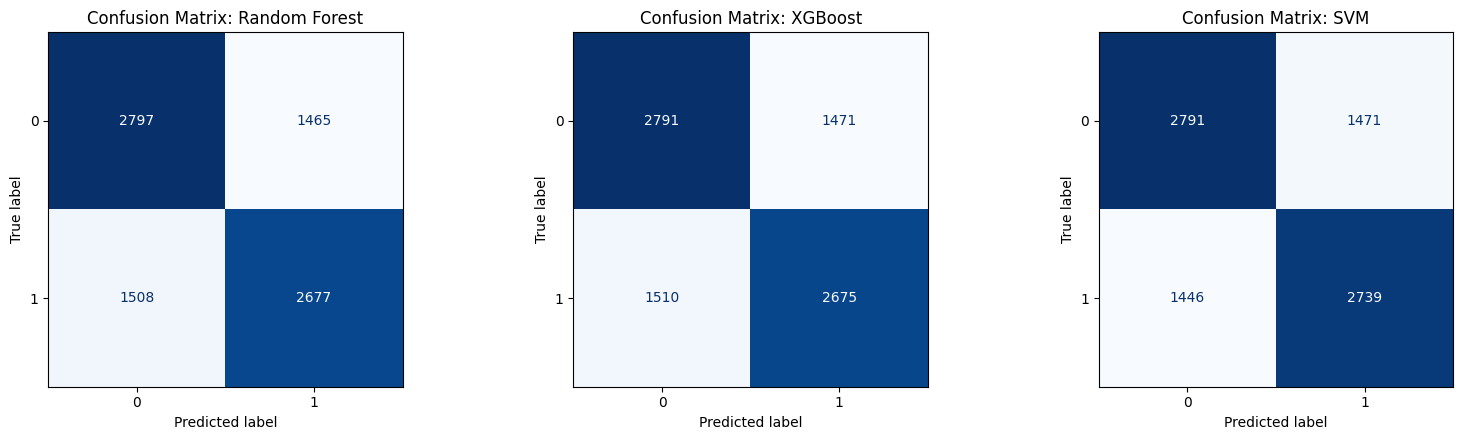

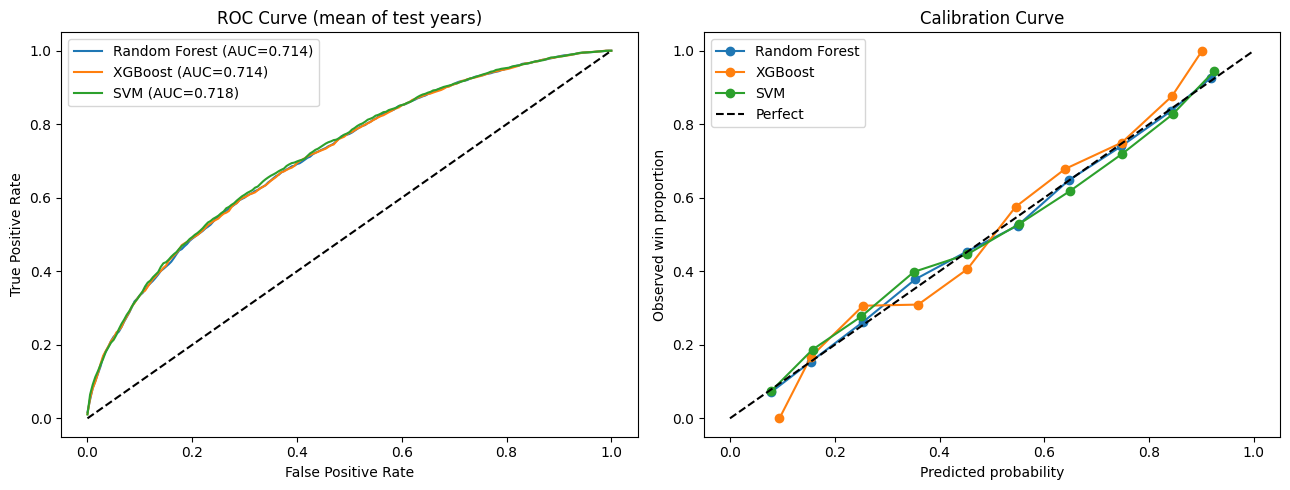

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, n in zip(axes, final_models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[n], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion Matrix: {n}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_confusion_matrix_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fgrid = np.linspace(0, 1, 201); fyr = test.date.dt.year.values; fys = sorted(np.unique(fyr))
for n, p in probas.items():
    tprs, ws, aucs = [], [], []
    for y in fys:
        m = fyr == y; fpr, tpr, _ = roc_curve(y_test[m], p[m])
        tprs.append(np.interp(fgrid, fpr, tpr)); ws.append(int(m.sum())); aucs.append(roc_auc_score(y_test[m], p[m]))
    axes[0].plot(fgrid, np.average(tprs, axis=0, weights=ws), label=f"{n} (AUC={np.average(aucs, weights=ws):.3f})")
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10)
    axes[1].plot(mean_pred, frac_pos, marker="o", label=n)
sub = " (mean of test years)" if FIG_LANG == "en" else " (rata-rata tahun uji)"
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title=L["roc"] + sub, xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].plot([0, 1], [0, 1], "k--", label=L["perfect"]); axes[1].set(title=L["calib"], xlabel=L["xlab"], ylabel=L["ylab"])
axes[0].legend(); axes[1].legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig2_roc_kalibrasi_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

R2-7

In [ ]:
# ===== SEL Y0: FREKUENSI DATA HILANG DAN KEANDALAN FITUR (R2-7). Jalankan setelah sel evaluasi (butuh df, train, test) =====
from collections import defaultdict, deque
from IPython.display import display

_d = df.reset_index(drop=True).copy()
_d["tahun"] = _d.tourney_date.dt.year

# ---------- laga yang dipertahankan: aturan awal-dingin (>= MIN_PRIOR_MATCHES laga sebelumnya untuk kedua pemain) dan tahun >= TRAIN_START_YEAR ----------
_c = defaultdict(int); _n1 = np.empty(len(_d), int); _n2 = np.empty(len(_d), int)
for _i, (_a, _b) in enumerate(zip(_d.winner_id.values, _d.loser_id.values)):
    _n1[_i], _n2[_i] = _c[_a], _c[_b]; _c[_a] += 1; _c[_b] += 1
_ret = (_n1 >= MIN_PRIOR_MATCHES) & (_n2 >= MIN_PRIOR_MATCHES) & (_d.tahun.values >= TRAIN_START_YEAR)
print(f"Laga dipertahankan: {int(_ret.sum())} | train + test pada notebook: {len(train) + len(test)}",
      "(cocok)" if int(_ret.sum()) == len(train) + len(test) else "(TIDAK cocok: periksa sebelum melanjutkan)")

# ---------- penanda data hilang per laga ----------
_f = pd.DataFrame({
    "Age (either player)":                  (_d.winner_age.isna() | _d.loser_age.isna()).values,
    "Height (either player)":               (_d.winner_ht.isna() | _d.loser_ht.isna()).values,
    "Match duration (this match)":          _d.minutes.isna().values,
    "Ranking points (either player)":       (_d.winner_rank_points.isna() | _d.loser_rank_points.isna()).values,
    "Handedness unknown (either player)":   (~_d.winner_hand.isin(["R", "L"]) | ~_d.loser_hand.isin(["R", "L"])).values})

# ---------- beban 14 hari: berapa laga yang jendela kelelahannya memuat durasi hasil imputasi (replika logika Tracker.load) ----------
_ld = defaultdict(lambda: deque(maxlen=60))
_any = np.zeros(len(_d), bool); _sh = np.full(len(_d), np.nan); _imp_min = _d.minutes.isna().values
_dates = _d.tourney_date.values; _mins = _d.minutes.values
for _i, (_a, _b) in enumerate(zip(_d.winner_id.values, _d.loser_id.values)):
    _dt = pd.Timestamp(_dates[_i]); _tot = 0.0; _im = 0.0; _ni = 0
    for _p in (_a, _b):
        for _dd, _m, _fl in _ld[_p]:
            if 0 <= (_dt - _dd).days <= 14:
                _tot += _m; _im += _m if _fl else 0.0; _ni += int(_fl)
    _any[_i] = _ni > 0; _sh[_i] = _im / _tot if _tot > 0 else np.nan
    _m_i = 100.0 if _imp_min[_i] else float(_mins[_i])
    for _p in (_a, _b): _ld[_p].append((_dt, _m_i, bool(_imp_min[_i])))
_f["14-day load includes an imputed duration (either player)"] = _any

# ---------- T1: frekuensi menurut himpunan data ----------
_sets = {"All cleaned matches": np.ones(len(_d), bool), "Retained (cold-start rule, 2010+)": _ret,
         "Retained, training period": _ret & (_d.tourney_date < pd.Timestamp(TEST_START_DATE)).values,
         "Retained, test period": _ret & (_d.tourney_date >= pd.Timestamp(TEST_START_DATE)).values}
t1 = pd.DataFrame({k: [f"{int(_f[c].values[m].sum())} ({100 * _f[c].values[m].mean():.1f}%)" for c in _f.columns]
                   for k, m in _sets.items()}, index=_f.columns)
t1.loc["Number of matches"] = [int(m.sum()) for m in _sets.values()]
display(t1)
share_in_window = float(np.nanmean(_sh[_ret & _any]))
print(f"Pada laga dipertahankan yang jendela 14 harinya memuat durasi imputasi ({int((_ret & _any).sum())} laga), "
      f"rata-rata {100 * share_in_window:.1f}% menit jendela berasal dari imputasi")

# ---------- T2: per pemain (bukan per laga) untuk usia dan tinggi, laga dipertahankan ----------
_r = _d[_ret]
slot = pd.DataFrame({"Variable": ["Age", "Height"],
    "Missing player-values": [int(_r.winner_age.isna().sum() + _r.loser_age.isna().sum()), int(_r.winner_ht.isna().sum() + _r.loser_ht.isna().sum())],
    "Of": [2 * len(_r)] * 2})
slot["%"] = (100 * slot["Missing player-values"] / slot["Of"]).round(2)
display(slot)

# ---------- T3: seberapa sering selisih 0 itu hasil imputasi, bukan nilai yang benar-benar sama ----------
def _nol(a, b):
    miss = (a.isna() | b.isna()).values; eq = (~miss) & (a.values == b.values)
    return int(miss.sum()), int(eq.sum())
rows3 = []
for lab, a, b in (("age_diff", _r.winner_age, _r.loser_age), ("height_diff", _r.winner_ht, _r.loser_ht)):
    mi, eq = _nol(a, b)
    rows3.append({"Feature": lab, "Zero because missing (imputed)": mi, "Zero because values are equal": eq,
                  "Share of zeros that are imputed (%)": round(100 * mi / max(mi + eq, 1), 1), "Matches": len(_r)})
t3 = pd.DataFrame(rows3); display(t3)

# ---------- T4: per tahun, per level dan per permukaan (laga dipertahankan) ----------
_r2 = _d[_ret].reset_index(drop=True); _fr = _f[_ret].reset_index(drop=True)
def _by(col):
    return (100 * _fr.groupby(_r2[col].values).mean()).round(1).assign(n=_r2.groupby(col).size())
t4y, t4l, t4s = _by("tahun"), _by("tourney_level"), _by("surface")
display(t4y); display(t4l); display(t4s)

# ---------- T5: durasi teramati dibanding nilai tetap 100 menit ----------
_o = _r2[_r2.minutes.notna()].copy(); _o["best_of5"] = (_o.best_of == 5)
t5 = _o.groupby("best_of5").minutes.agg(n="size", mean="mean", median="median",
        p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), below_100=lambda s: 100 * (s < 100).mean()).round(1)
t5.index = ["best-of-3" if not k else "best-of-5" for k in t5.index]
display(t5)

t1.to_csv(f"{OUT_DIR}/tabel_missing_frekuensi.csv"); slot.to_csv(f"{OUT_DIR}/tabel_missing_per_pemain.csv", index=False)
t3.to_csv(f"{OUT_DIR}/tabel_missing_selisih_nol.csv", index=False)
t4y.to_csv(f"{OUT_DIR}/tabel_missing_per_tahun.csv"); t4l.to_csv(f"{OUT_DIR}/tabel_missing_per_level.csv")
t4s.to_csv(f"{OUT_DIR}/tabel_missing_per_permukaan.csv"); t5.to_csv(f"{OUT_DIR}/tabel_menit_teramati.csv")


Laga dipertahankan: 38639 | train + test pada notebook: 38639 (cocok)


,All cleaned matches,"Retained (cold-start rule, 2010+)","Retained, training period","Retained, test period"
Age (either player),4 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Height (either player),2052 (2.7%),88 (0.2%),56 (0.2%),32 (0.4%)
Match duration (this match),6709 (9.0%),2650 (6.9%),2179 (7.2%),471 (5.6%)
Ranking points (either player),0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
Handedness unknown (either player),461 (0.6%),36 (0.1%),5 (0.0%),31 (0.4%)
14-day load includes an imputed duration (either player),8425 (11.3%),3633 (9.4%),2880 (9.5%),753 (8.9%)
Number of matches,74674,38639,30192,8447


Pada laga dipertahankan yang jendela 14 harinya memuat durasi imputasi (3633 laga), rata-rata 68.2% menit jendela berasal dari imputasi


,Variable,Missing player-values,Of,%
0,Age,0,77278,0.00
1,Height,93,77278,0.12


,Feature,Zero because missing (imputed),Zero because values are equal,Share of zeros that are imputed (%),Matches
0,age_diff,0,307,0.0,38639
1,height_diff,88,3991,2.2,38639


,Age (either player),Height (either player),Match duration (this match),Ranking points (either player),Handedness unknown (either player),14-day load includes an imputed duration (either player),n
2010,0.0,0.3,4.6,0.0,0.0,6.9,2432
2011,0.0,0.3,4.6,0.0,0.0,7.9,2480
2012,0.0,0.3,4.9,0.0,0.0,9.2,2586
2013,0.0,0.2,4.7,0.0,0.0,8.8,2393
2014,0.0,0.4,4.9,0.0,0.0,9.1,2293
2015,0.0,0.2,51.1,0.0,0.0,46.5,2440
2016,0.0,0.1,0.3,0.0,0.0,1.4,2428
2017,0.0,0.2,1.8,0.0,0.1,7.1,2389
2018,0.0,0.2,0.8,0.0,0.0,4.0,2490
2019,0.0,0.0,1.4,0.0,0.0,4.0,2359


,Age (either player),Height (either player),Match duration (this match),Ranking points (either player),Handedness unknown (either player),14-day load includes an imputed duration (either player),n
A,0.0,0.1,3.8,0.0,0.0,10.0,20918
D,0.0,3.4,65.5,0.0,0.3,27.8,1524
F,0.0,1.0,8.1,0.0,1.0,11.2,295
G,0.0,0.1,7.5,0.0,0.1,5.9,7095
M,0.0,0.2,2.7,0.0,0.1,7.2,8748
O,0.0,0.0,100.0,0.0,0.0,52.5,59


,Age (either player),Height (either player),Match duration (this match),Ranking points (either player),Handedness unknown (either player),14-day load includes an imputed duration (either player),n
Carpet,0.0,31.2,75.0,0.0,0.0,31.2,16
Clay,0.0,0.4,7.0,0.0,0.2,7.4,11807
Grass,0.0,0.0,7.3,0.0,0.0,9.3,4153
Hard,0.0,0.1,6.7,0.0,0.0,10.5,22663


,n,mean,median,p25,p75,below_100
best-of-3,29203,103.0,97.0,78.0,124.0,52.9
best-of-5,6786,157.2,149.0,119.0,189.0,8.9


In [ ]:
# ===== SEL Y1: SENSITIVITAS TERHADAP STRATEGI IMPUTASI (R2-7). Jalankan setelah Sel Y0 (butuh df, data, FROZEN, fold_params, probas) =====
# Parameter model TIDAK dicari ulang: tiap lipatan memakai parameter yang dipilih Sel B; hanya fitur yang berubah.
import time, ast
from collections import defaultdict, deque
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, log_loss
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]         # tahun uji luar (didefinisikan ulang agar sel ini mandiri setelah pemulihan checkpoint)
YB = 1000                                       # resampel bootstrap (blok bulan kalender)
Y_SVM = ["S0", "S1", "S3", "S6"]                # skenario yang dijalankan untuk SVM (paling lama); isi semua skenario bila waktu cukup
SKENARIO = {
    "S0": "Current rule (missing age/height difference = 0; missing duration = 100 min)",
    "S1": "S0 + missingness indicators (age, height, imputed duration in 14-day window)",
    "S2": "Training-derived: age/height = median of the training years; duration = running mean of earlier matches by best-of",
    "S3": "S2 + missingness indicators",
    "S4": "Missing duration = 60 min (age/height as S0)",
    "S5": "Missing duration = 150 min (age/height as S0)",
    "S6": "Age, height and fatigue differences removed (no imputation needed)"}

# ---------- replay fitur dengan aturan imputasi durasi yang dapat diubah ----------
class _TrackerY(Tracker):
    """Tracker dengan aturan imputasi durasi: angka tetap, atau 'run' = rata-rata berjalan durasi teramati sebelumnya per best-of."""
    def __init__(self, rule):
        super().__init__(); self.rule = rule
        self.imp = defaultdict(lambda: deque(maxlen=60))            # (tanggal, 1 bila durasi diimputasi), sejajar dengan self.load
        self.os, self.on = defaultdict(float), defaultdict(int)
    def dynamic(self, pid, surface, date):
        d = super().dynamic(pid, surface, date)
        d["n_imp14"] = sum(f for dd, f in self.imp[pid] if 0 <= (date - dd).days <= 14)
        return d
    def update(self, r):
        bo = 5 if r.best_of == 5 else 3
        miss = bool(pd.isna(r.minutes))
        if miss:
            m = float(self.rule) if isinstance(self.rule, (int, float)) else (self.os[bo] / self.on[bo] if self.on[bo] else 100.0)
        else:
            m = float(r.minutes); self.os[bo] += m; self.on[bo] += 1
        super().update(r._replace(minutes=m))
        for pid in (r.winner_id, r.loser_id): self.imp[pid].append((r.tourney_date, int(miss)))

def _yreplay(d, orient, rule):
    t = _TrackerY(rule); rows = []
    for i, r in enumerate(d.itertuples(index=False)):
        s, dt = r.surface, r.tourney_date
        w = dict(rank=r.winner_rank, points=r.winner_rank_points, age=r.winner_age, ht=r.winner_ht,
                 lefty=float(r.winner_hand == "L"), **t.dynamic(r.winner_id, s, dt))
        l = dict(rank=r.loser_rank, points=r.loser_rank_points, age=r.loser_age, ht=r.loser_ht,
                 lefty=float(r.loser_hand == "L"), **t.dynamic(r.loser_id, s, dt))
        h2h_w = t.h2h[(r.winner_id, r.loser_id)] - t.h2h[(r.loser_id, r.winner_id)]
        y_ = bool(orient[i])
        p1, p2, h2h = (w, l, h2h_w) if y_ else (l, w, -h2h_w)
        f = build_features(p1, p2, s, r.best_of, r.tourney_level == "G", h2h)
        f.update(target=int(y_), date=dt, n1=p1["exp"], n2=p2["exp"], age1=p1["age"], age2=p2["age"],
                 ht1=p1["ht"], ht2=p2["ht"], imp1=p1["n_imp14"], imp2=p2["n_imp14"])
        rows.append(f); t.update(r)
    return pd.DataFrame(rows)

_dy = df.reset_index(drop=True)
_ori = np.random.default_rng(SEED).random(len(_dy)) < 0.5            # urutan acak yang sama dengan sel pembentuk fitur
_reps = {}
for _nm, _rule in (("c100", 100), ("c60", 60), ("c150", 150), ("run", "run")):
    _t0 = time.perf_counter(); _rep = _yreplay(_dy, _ori, _rule)
    _k = ((_rep.n1 >= MIN_PRIOR_MATCHES) & (_rep.n2 >= MIN_PRIOR_MATCHES)).values
    _rep = _rep[_k].reset_index(drop=True)
    assert len(_rep) == len(data) and (_rep.target.values == data.target.values).all() and (_rep.date.values == data.date.values).all(), \
        "Replay tidak sejajar dengan `data`: hentikan dan periksa dahulu"
    _reps[_nm] = _rep; print(f"Replay '{_nm}' selesai ({time.perf_counter() - _t0:.0f} s)")
assert np.allclose(_reps["c100"][FEATURES].values, data[FEATURES].values), "Replay aturan saat ini tidak identik dengan `data`"
print("Replay aturan saat ini identik dengan `data` (semua fitur sama persis).")

def _yflags(rep):
    return pd.DataFrame({"age_missing": (rep.age1.isna() | rep.age2.isna()).astype(int).values,
                         "height_missing": (rep.ht1.isna() | rep.ht2.isna()).astype(int).values,
                         "minutes_imputed": ((rep.imp1 > 0) | (rep.imp2 > 0)).astype(int).values}, index=rep.index)

def _xs(scn, Y):
    """Matriks fitur skenario `scn` untuk lipatan Y; median usia/tinggi hanya dari tahun latih (< Y)."""
    rep = _reps["c60"] if scn == "S4" else _reps["c150"] if scn == "S5" else _reps["run"] if scn in ("S2", "S3") else _reps["c100"]
    X = rep[FEATURES].copy()
    if scn in ("S2", "S3"):
        trm = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")).values
        for a, b, col in (("age1", "age2", "age_diff"), ("ht1", "ht2", "height_diff")):
            med = np.nanmedian(np.concatenate([rep.loc[trm, a].values, rep.loc[trm, b].values]))
            X[col] = rep[a].fillna(med).values - rep[b].fillna(med).values
    if scn in ("S1", "S3"):
        X = pd.concat([X, _yflags(rep)], axis=1)
    if scn == "S6":
        X = X.drop(columns=["age_diff", "height_diff", "fatigue_diff"])
    return X

_fp = pd.DataFrame(fold_params)
def _yparams(name, Y):
    s = _fp[(_fp.Model == name) & (_fp["Tahun uji"] == Y)]["Parameter"].iloc[0]
    try: return ast.literal_eval(s)
    except Exception: return eval(s, {"np": np, "nan": np.nan, "inf": np.inf})

# ---------- latih ulang per lipatan dan skenario ----------
_te = (data.date >= TEST_START_DATE).values; _yrs_all = data.date.dt.year.values; _yt = data.target.values
_yv = _yt[_te]; _yr = _yrs_all[_te]; _fy = [y for y in OUTER_YEARS if (_yr == y).any()]
_res, _tm = {}, {}
for scn in SKENARIO:
    for name in FROZEN:
        if name == "SVM" and scn not in Y_SVM: continue
        _res[(scn, name)] = np.full(int(_te.sum()), np.nan); _tm[(scn, name)] = 0.0
    for Y in _fy:
        trm = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")).values
        tem = (_yrs_all == Y) & _te; pos = (_yr == Y)
        X = _xs(scn, Y)
        for name in FROZEN:
            if (scn, name) not in _res: continue
            _tf = time.perf_counter()
            m = clone(FROZEN[name][0]).set_params(**_yparams(name, Y))
            if name != "SVM": m.set_params(clf__n_jobs=-1)
            m.fit(X[trm], _yt[trm])
            _res[(scn, name)][pos] = m.decision_function(X[tem]) if name == "SVM" else m.predict_proba(X[tem])[:, 1]
            _tm[(scn, name)] += time.perf_counter() - _tf
    print(f"{scn} selesai | " + " | ".join(f"{n} {_tm[(scn, n)]:.0f} s" for n in FROZEN if (scn, n) in _res))

# ---------- sanity: S0 harus mereproduksi hasil Sel B (RF, XGBoost) ----------
for name in FROZEN:
    if name != "SVM":
        print(f"S0 vs Sel B, {name}: maks |selisih probabilitas| = {np.abs(_res[('S0', name)] - probas[name]).max():.2e}")
    else:
        _tanda = (_res[("S0", name)] >= 0).astype(int); print(f"S0 vs Sel B, SVM: akurasi tanda keputusan {np.mean(_tanda == _yv):.4f} vs akurasi probabilitas {np.mean(preds[name] == _yv):.4f}")

# ---------- metrik ----------
def _wauc(s, y, yr):
    a, w = [], []
    for yy in _fy:
        k = yr == yy
        if k.sum() and len(np.unique(y[k])) == 2: a.append(roc_auc_score(y[k], s[k])); w.append(int(k.sum()))
    return float(np.average(a, weights=w))
_thr = lambda n: 0.0 if n == "SVM" else 0.5
_cor = {k: ((s >= _thr(k[1])).astype(int) == _yv) for k, s in _res.items()}

_mo = pd.PeriodIndex(data.date[_te].values, freq="M"); _codes = pd.factorize(_mo)[0]; _K = _codes.max() + 1
_mi = [np.where(_codes == c)[0] for c in range(_K)]; _rb = np.random.default_rng(SEED)
_idx = [np.concatenate([_mi[c] for c in _rb.integers(0, _K, _K)]) for _ in range(YB)]

_yr_rows = []
for name in FROZEN:
    s0 = _res[("S0", name)]; a0 = np.array([_wauc(s0[ix], _yv[ix], _yr[ix]) for ix in _idx])
    for scn in SKENARIO:
        if (scn, name) not in _res: continue
        s = _res[(scn, name)]
        da = np.array([_cor[(scn, name)][ix].mean() - _cor[("S0", name)][ix].mean() for ix in _idx]) * 100
        du = np.array([_wauc(s[ix], _yv[ix], _yr[ix]) for ix in _idx]) - a0 if scn != "S0" else np.zeros(YB)
        ll = round(float(log_loss(_yv, s)), 4) if name != "SVM" else np.nan
        _yr_rows.append({"Model": name, "Scenario": scn, "Accuracy": round(float(_cor[(scn, name)].mean()), 4),
                     "ROC-AUC (yearly mean)": round(_wauc(s, _yv, _yr), 4), "Log loss": ll,
                     "dAccuracy vs S0 (pts)": round(float(_cor[(scn, name)].mean() - _cor[("S0", name)].mean()) * 100, 2),
                     "dAcc 95% CI": "" if scn == "S0" else f"{np.percentile(da, 2.5):.2f} to {np.percentile(da, 97.5):.2f}",
                     "dAUC vs S0": round(_wauc(s, _yv, _yr) - _wauc(s0, _yv, _yr), 4),
                     "dAUC 95% CI": "" if scn == "S0" else f"{np.percentile(du, 2.5):.4f} to {np.percentile(du, 97.5):.4f}",
                     "Features": int(_xs(scn, _fy[-1]).shape[1])})
t_imp = pd.DataFrame(_yr_rows)
display(pd.DataFrame({"Description": SKENARIO}))
display(t_imp)
print("Catatan: untuk SVM, akurasi memakai tanda fungsi keputusan dan AUC memakai fungsi keputusan (tanpa kalibrasi Platt); bandingkan hanya antar skenario.")

# ---------- performa model pada laga dengan data lengkap vs laga yang memuat imputasi (tanpa latih ulang; model Sel B) ----------
_fl = _yflags(_reps["c100"])[_te].reset_index(drop=True)
_lengkap = ((_fl.age_missing == 0) & (_fl.height_missing == 0) & (_fl.minutes_imputed == 0)).values
_elo = data.elo_diff.values[_te]
_yr_rows2 = []
for lab, mk in (("All observed", _lengkap), ("At least one imputed value", ~_lengkap)):
    for n in list(probas) + ["Elo baseline"]:
        sc = probas[n] if n in probas else _elo
        acc = float((((sc >= .5) if n in probas else (sc > 0)).astype(int)[mk] == _yv[mk]).mean())
        _yr_rows2.append({"Subset": lab, "Model": n, "Matches": int(mk.sum()), "Accuracy": round(acc, 4),
                      "ROC-AUC (yearly mean)": round(_wauc(sc[mk], _yv[mk], _yr[mk]), 4)})
t_sub = pd.DataFrame(_yr_rows2).pivot(index="Model", columns="Subset", values=["Matches", "Accuracy", "ROC-AUC (yearly mean)"])
display(t_sub)
t_imp.to_csv(f"{OUT_DIR}/tabel_imputasi_sensitivitas.csv", index=False)
pd.DataFrame({"Description": SKENARIO}).to_csv(f"{OUT_DIR}/tabel_imputasi_skenario.csv")
pd.DataFrame(_yr_rows2).to_csv(f"{OUT_DIR}/tabel_imputasi_subset.csv", index=False)

Replay 'c100' selesai (78 s)
Replay 'c60' selesai (70 s)
Replay 'c150' selesai (68 s)
Replay 'run' selesai (68 s)
Replay aturan saat ini identik dengan `data` (semua fitur sama persis).
S0 selesai | Random Forest 59 s | XGBoost 8 s | SVM 254 s
S1 selesai | Random Forest 47 s | XGBoost 9 s | SVM 270 s
S2 selesai | Random Forest 56 s | XGBoost 10 s
S3 selesai | Random Forest 48 s | XGBoost 10 s | SVM 268 s
S4 selesai | Random Forest 56 s | XGBoost 10 s
S5 selesai | Random Forest 56 s | XGBoost 10 s
S6 selesai | Random Forest 44 s | XGBoost 8 s | SVM 274 s
S0 vs Sel B, Random Forest: maks |selisih probabilitas| = 3.33e-16
S0 vs Sel B, XGBoost: maks |selisih probabilitas| = 0.00e+00
S0 vs Sel B, SVM: akurasi tanda keputusan 0.6555 vs akurasi probabilitas 0.6547


,Description
S0,Current rule (missing age/height difference = ...
S1,"S0 + missingness indicators (age, height, impu..."
S2,Training-derived: age/height = median of the t...
S3,S2 + missingness indicators
S4,Missing duration = 60 min (age/height as S0)
S5,Missing duration = 150 min (age/height as S0)
S6,"Age, height and fatigue differences removed (n..."


,Model,Scenario,Accuracy,ROC-AUC (yearly mean),Log loss,dAccuracy vs S0 (pts),dAcc 95% CI,dAUC vs S0,dAUC 95% CI,Features
0,Random Forest,S0,0.6480,0.7137,0.6166,0.00,,0.0000,,17
1,Random Forest,S1,0.6473,0.7138,0.6166,-0.07,-0.22 to 0.09,0.0001,-0.0004 to 0.0006,20
2,Random Forest,S2,0.6473,0.7138,0.6166,-0.07,-0.20 to 0.04,0.0001,-0.0000 to 0.0002,17
3,Random Forest,S3,0.6473,0.7139,0.6165,-0.07,-0.23 to 0.08,0.0002,-0.0004 to 0.0007,20
4,Random Forest,S4,0.6473,0.7139,0.6166,-0.07,-0.21 to 0.04,0.0001,-0.0000 to 0.0003,17
5,Random Forest,S5,0.6474,0.7138,0.6166,-0.06,-0.16 to 0.03,0.0001,-0.0001 to 0.0002,17
6,Random Forest,S6,0.6469,0.7116,0.6179,-0.12,-0.50 to 0.23,-0.0021,-0.0034 to -0.0011,14
7,XGBoost,S0,0.6471,0.7139,0.6318,0.00,,0.0000,,17
8,XGBoost,S1,0.6471,0.7136,0.6318,0.00,-0.23 to 0.19,-0.0003,-0.0008 to 0.0001,20
9,XGBoost,S2,0.6476,0.7139,0.6318,0.05,-0.03 to 0.13,0.0000,-0.0001 to 0.0001,17


Catatan: untuk SVM, akurasi memakai tanda fungsi keputusan dan AUC memakai fungsi keputusan (tanpa kalibrasi Platt); bandingkan hanya antar skenario.


Matches                                Accuracy  \
Subset        All observed At least one imputed value All observed   
Model                                                                
Elo baseline        7662.0                      785.0       0.6378   
Random Forest       7662.0                      785.0       0.6464   
SVM                 7662.0                      785.0       0.6532   
XGBoost             7662.0                      785.0       0.6451   

                                         ROC-AUC (yearly mean)  \
Subset        At least one imputed value          All observed   
Model                                                            
Elo baseline                      0.6688                0.6991   
Random Forest                     0.6637                0.7115   
SVM                               0.6688                0.7155   
XGBoost                           0.6662                0.7116   

                                          
Subset        At least one imputed value  
Model                                     
Elo baseline                      0.7372  
Random Forest                     0.7370  
SVM                               0.7421  
XGBoost                           0.7388

SEL T - R2-2

In [ ]:
import time
from IPython.display import display

dA = df.copy().reset_index(drop=True)
dA["round_order"] = dA["round"].map(ROUND_ORDER).fillna(0)
dA["uid"] = np.arange(len(dA))                                   # kunci unik per baris (mengikuti urutan `df`)
dA["periode"] = np.where(dA.tourney_date >= TEST_START_DATE, "uji", "sebelum uji")

def _long(d):
    a = d[["uid", "tourney_id", "tourney_date", "round_order", "winner_id", "loser_id"]]
    return pd.concat([a.assign(pid=a.winner_id, lost=0), a.assign(pid=a.loser_id, lost=1)], ignore_index=True)

# ---------- A. Audit urutan: laga mana yang urutannya hanya ditentukan oleh match_num? ----------
# Status pemain hanya berubah oleh laga miliknya sendiri, sehingga urutan dua laga hanya berpengaruh bila keduanya
# melibatkan pemain yang sama DAN memiliki (tanggal turnamen, babak) yang sama.
L = _long(dA)
cnt = L.groupby(["tourney_date", "round_order", "pid"])["uid"].transform("size")
dA["ambigu"] = dA.uid.isin(set(L.loc[cnt > 1, "uid"]))
audit = dA.groupby(["periode", "round"]).agg(laga=("uid", "size"), laga_ambigu=("ambigu", "sum")).query("laga_ambigu > 0")
_k = dA.tourney_date.values.astype("datetime64[D]").astype("int64") * 10 + dA.round_order.values.astype("int64")
print("Baris `df` menaik menurut (tanggal turnamen, babak):", bool((np.diff(_k) >= 0).all()))
print(f"Laga dengan urutan ambigu: {int(dA.ambigu.sum())} dari {len(dA)} ({100*dA.ambigu.mean():.2f}%)")
display(audit)

# kekonsistenan sistem gugur: pemain yang sudah kalah tidak boleh bermain lagi di turnamen gugur yang sama
rounds_t = dA.groupby("tourney_id")["round"].agg(lambda s: set(s))
knock = {t for t, rs in rounds_t.items() if rs <= {"R128", "R64", "R32", "R16", "QF", "SF", "F"}}
Lk = _long(dA); Lk = Lk[Lk.tourney_id.isin(knock)].sort_values("uid")
Lk["kalah_sebelumnya"] = Lk.groupby(["tourney_id", "pid"])["lost"].cumsum() - Lk["lost"]
pelanggaran = int((Lk.kalah_sebelumnya > 0).sum())
print(f"Pelanggaran sistem gugur (kalah lalu main lagi): {pelanggaran} dari {len(Lk)} catatan pemain ({len(knock)} turnamen)")

# ---------- fungsi replay: bangun ulang fitur dari nol, dengan urutan atau data yang diubah ----------
def replay(d, orient=None, seed=SEED):
    tr_ = Tracker(); rng_ = np.random.default_rng(seed); rows = []
    for r in d.itertuples(index=False):
        s, dt = r.surface, r.tourney_date
        w = dict(rank=r.winner_rank, points=r.winner_rank_points, age=r.winner_age, ht=r.winner_ht,
                 lefty=float(r.winner_hand == "L"), **tr_.dynamic(r.winner_id, s, dt))
        l = dict(rank=r.loser_rank, points=r.loser_rank_points, age=r.loser_age, ht=r.loser_ht,
                 lefty=float(r.loser_hand == "L"), **tr_.dynamic(r.loser_id, s, dt))
        h2h_w = tr_.h2h[(r.winner_id, r.loser_id)] - tr_.h2h[(r.loser_id, r.winner_id)]
        y_ = (rng_.random() < 0.5) if orient is None else bool(orient[r.uid])      # True: Pemain 1 = pemenang
        p1, p2, h2h = (w, l, h2h_w) if y_ else (l, w, -h2h_w)
        f = build_features(p1, p2, s, r.best_of, r.tourney_level == "G", h2h)
        f.update(target=int(y_), date=dt, n1=p1["exp"], n2=p2["exp"], uid=r.uid)
        rows.append(f); tr_.update(r)
    return pd.DataFrame(rows).set_index("uid").sort_index()

t0 = time.perf_counter()
base = replay(dA)
ORI = base["target"].to_dict()
print(f"Replay dasar selesai ({time.perf_counter()-t0:.0f} s)")
keep = ((base.n1 >= MIN_PRIOR_MATCHES) & (base.n2 >= MIN_PRIOR_MATCHES)).values
b = base[keep]
assert len(b) == len(data) and np.allclose(b[FEATURES].values, data[FEATURES].values) and (b.target.values == data.target.values).all(), \
    "Replay tidak identik dengan `data`: hentikan dan periksa dahulu"
print("Replay identik dengan `data` (semua fitur dan label sama persis).")
b = b.assign(ambigu=dA.set_index("uid").loc[b.index, "ambigu"].values)

# ---------- B. Uji 'masa depan diracuni' ----------
def poison(d, cutoff):
    """Setelah tanggal batas: tukar seluruh kolom winner_* dan loser_*, dan setel menit bermain = 999."""
    d = d.copy(); m = (d.tourney_date >= pd.Timestamp(cutoff)).values
    for col in [x for x in d.columns if x.startswith("winner_")]:
        other = "loser_" + col[len("winner_"):]
        if other in d.columns:
            a_, o_ = d.loc[m, col].values.copy(), d.loc[m, other].values.copy()
            d.loc[m, col], d.loc[m, other] = o_, a_
    d.loc[m, "minutes"] = 999.0
    return d

rows_B = []
for cutoff in ["2023-01-01", "2025-01-01"]:
    pb = replay(poison(dA, cutoff), orient=ORI)
    pre = (base.date < pd.Timestamp(cutoff)).values
    diff = float(np.abs(pb.loc[pre, FEATURES].values - base.loc[pre, FEATURES].values).max())
    rows_B.append({"Batas": cutoff, "Laga sebelum batas": int(pre.sum()), "Selisih fitur maks.": diff, "Lulus": diff == 0})
test_B = pd.DataFrame(rows_B)

# B2. Uji pembalikan hasil laga sendiri: balik pemenang/pecundang HANYA pada laga target (dan menit = 999),
# ulangi dari awal sampai laga itu. Fitur laga target harus tidak berubah sama sekali.
rg_ = np.random.default_rng(0)
cand = b.index[(b.date >= pd.Timestamp(TEST_START_DATE)).values]
cand_amb = [u for u in cand if b.loc[u, "ambigu"]]
samp = list(rg_.choice(cand, 8, replace=False)) + (list(rg_.choice(cand_amb, min(4, len(cand_amb)), replace=False)) if cand_amb else [])
worst = 0.0
for u in samp:
    pref = dA.iloc[: u + 1].copy()                                            # prefiks sampai laga u; hanya baris u yang dibalik
    for col in [x for x in pref.columns if x.startswith("winner_")]:
        oc = "loser_" + col[len("winner_"):]
        if oc in pref.columns:
            a_, o_ = pref.iloc[-1][col], pref.iloc[-1][oc]
            pref.iloc[-1, pref.columns.get_loc(col)], pref.iloc[-1, pref.columns.get_loc(oc)] = o_, a_
    pref.iloc[-1, pref.columns.get_loc("minutes")] = 999.0
    ori2 = dict(ORI); ori2[u] = 1 - ORI[u]                                    # pertahankan identitas Pemain 1
    fl = replay(pref, orient=ori2).loc[u, FEATURES].values.astype(float)
    worst = max(worst, float(np.abs(fl - base.loc[u, FEATURES].values.astype(float)).max()))
test_B2 = pd.DataFrame([{"Laga diuji": len(samp), "Selisih fitur maks.": worst, "Lulus": worst == 0}])
display(test_B); display(test_B2)

# ---------- C. Sensitivitas terhadap urutan ikatan (acak di dalam tanggal turnamen + babak yang sama) ----------
def order_random(d, seed):
    d = d.copy(); d["_r"] = np.random.default_rng(seed).random(len(d))
    return d.sort_values(["tourney_date", "round_order", "_r"]).drop(columns=["_r"])

is_test = (b.date >= pd.Timestamp(TEST_START_DATE)).values
y_b = b.target.values
rows_C = []
for sd in (1, 2, 3):
    pr_all = replay(order_random(dA, sd), orient=ORI)
    cold_diff = int((((pr_all.n1 >= MIN_PRIOR_MATCHES) & (pr_all.n2 >= MIN_PRIOR_MATCHES)).values != keep).sum())
    pr = pr_all.loc[b.index]                                              # sejajarkan menurut uid
    assert (pr.target.values == y_b).all()
    d_elo = np.abs(pr["elo_diff"].values - b["elo_diff"].values)
    non_elo = ["form_diff", "surface_wr_diff", "h2h_diff", "fatigue_diff", "experience_diff"]
    d_non = (np.abs(pr[non_elo].values - b[non_elo].values).max(axis=1) > 1e-9)
    row = {"Acakan": sd,
           "Laga uji dengan |Δ elo_diff| > 1 poin": int((d_elo[is_test] > 1).sum()),
           "Rata-rata |Δ elo_diff| (uji, poin Elo)": round(float(d_elo[is_test].mean()), 3),
           "Maks. |Δ elo_diff| (uji, poin Elo)": round(float(d_elo[is_test].max()), 2),
           "Laga uji dengan fitur non-Elo berubah": int((d_non & is_test).sum()),
           "Status cold-start berbeda": cold_diff}
    Xp, Xb = pr.loc[is_test, FEATURES], b.loc[is_test, FEATURES]
    for n, m in final_models.items():
        pp, pb_ = m.predict(Xp), m.predict(Xb)
        row[f"Prediksi {n} berubah"] = int((pp != pb_).sum())
        row[f"Δ akurasi {n} (poin %)"] = round(100 * ((pp == y_b[is_test]).mean() - (pb_ == y_b[is_test]).mean()), 3)
    rows_C.append(row)
test_C = pd.DataFrame(rows_C).set_index("Acakan"); display(test_C.T)

# ---------- D. Akurasi tanpa laga ambigu (memakai prediksi gabungan hasil sel B) ----------
amb_test = b.ambigu.values[is_test]
assert len(amb_test) == len(y_test) and (b.target.values[is_test] == y_test).all(), "Laga uji tidak sejajar dengan sel B: periksa dahulu"
tbl = {"n": [int(len(y_test)), int((~amb_test).sum()), int(amb_test.sum())]}
for n in preds:
    tbl[n] = [round((preds[n] == y_test).mean(), 4), round((preds[n][~amb_test] == y_test[~amb_test]).mean(), 4),
              round((preds[n][amb_test] == y_test[amb_test]).mean(), 4) if amb_test.sum() else np.nan]
test_D = pd.DataFrame(tbl, index=["Semua laga uji", "Tanpa laga ambigu", "Hanya laga ambigu"]); display(test_D)

for name, tb in (("audit_urutan", audit), ("racun_masa_depan", test_B), ("balik_hasil_sendiri", test_B2), ("sensitivitas_ikatan", test_C), ("akurasi_tanpa_ambigu", test_D)):
    tb.to_csv(f"{OUT_DIR}/tabel_integritas_{name}.csv")

Baris `df` menaik menurut (tanggal turnamen, babak): True
Laga dengan urutan ambigu: 5299 dari 74674 (7.10%)


laga  laga_ambigu
periode     round                   
sebelum uji BR        7            7
            RR     5846         4748
            SF     2896           14
uji         BR        1            1
            RR      833          527
            SF      434            2

Pelanggaran sistem gugur (kalah lalu main lagi): 0 dari 134634 catatan pemain (1672 turnamen)
Replay dasar selesai (42 s)
Replay identik dengan `data` (semua fitur dan label sama persis).


,Batas,Laga sebelum batas,Selisih fitur maks.,Lulus
0,2023-01-01,64816,0.0,True
1,2025-01-01,70629,0.0,True


,Laga diuji,Selisih fitur maks.,Lulus
0,12,0.0,True


Acakan,1,2,3
Laga uji dengan |Δ elo_diff| > 1 poin,1480.000,1429.000,1417.000
"Rata-rata |Δ elo_diff| (uji, poin Elo)",1.108,1.098,1.044
"Maks. |Δ elo_diff| (uji, poin Elo)",133.170,135.810,121.900
Laga uji dengan fitur non-Elo berubah,296.000,272.000,264.000
Status cold-start berbeda,35.000,34.000,34.000
Prediksi Random Forest berubah,11.000,20.000,16.000
Δ akurasi Random Forest (poin %),-0.036,0.024,0.000
Prediksi XGBoost berubah,9.000,21.000,19.000
Δ akurasi XGBoost (poin %),-0.012,-0.059,-0.083
Prediksi SVM berubah,19.000,21.000,15.000


,n,Random Forest,XGBoost,SVM
Semua laga uji,8447,0.6480,0.6471,0.6547
Tanpa laga ambigu,8170,0.6488,0.6483,0.6563
Hanya laga ambigu,277,0.6245,0.6101,0.6065


SEL U: ALUR SELEKSI DATA DAN EKSKLUSI (R2-3).

In [ ]:
from IPython.display import display

# ---------- 1. Alasan eksklusi tahap pembersihan (urutan sama dengan sel 5; satu alasan per laga, alasan pertama yang berlaku) ----------
R = raw.copy()
R["tourney_date"] = pd.to_datetime(R["tourney_date"].astype(int).astype(str), format="%Y%m%d")
sc = R["score"].fillna("")
alasan = pd.Series("dipertahankan", index=R.index, dtype=object)
def tandai(mask, label):
    alasan.loc[mask & (alasan == "dipertahankan")] = label
tandai(R["surface"].isna(), "1. Permukaan kosong")
tandai(R["winner_id"].isna() | R["loser_id"].isna(), "2. ID pemain kosong")
tandai(R["winner_rank"].isna() | R["loser_rank"].isna(), "3. Peringkat salah satu pemain kosong")
tandai(sc.str.contains("W/O|DEF"), "4. Walkover atau default")
if DROP_RETIRED:
    tandai(sc.str.contains("RET"), "5. Mundur di tengah laga (RET)")
assert (alasan == "dipertahankan").sum() == len(df), "Jumlah laga bersih tidak sama dengan `df`: hentikan dan periksa dahulu"

# ---------- 2. Aturan cold-start: jumlah laga sebelumnya tiap pemain, dihitung ulang dari urutan `df` ----------
D = df.reset_index(drop=True).copy()
pos = np.arange(len(D))
lg = pd.concat([pd.DataFrame({"pos": pos, "pid": D.winner_id.values, "sisi": "w"}),
                pd.DataFrame({"pos": pos, "pid": D.loser_id.values, "sisi": "l"})]).sort_values("pos", kind="stable")
lg["n_sebelum"] = lg.groupby("pid").cumcount()
nw = lg[lg.sisi == "w"].set_index("pos")["n_sebelum"].reindex(pos).values
nl = lg[lg.sisi == "l"].set_index("pos")["n_sebelum"].reindex(pos).values
D["n_min"] = np.minimum(nw, nl)
cold = D.n_min < MIN_PRIOR_MATCHES
assert (~cold).sum() == len(data), "Cold-start tidak sama dengan `data`: hentikan dan periksa dahulu"
st = np.select([cold & (nw < MIN_PRIOR_MATCHES) & (nl < MIN_PRIOR_MATCHES), cold],
               ["6b. Cold-start: kedua pemain < 10 laga", "6a. Cold-start: satu pemain < 10 laga"], default="dipertahankan")
st = pd.Series(st, index=D.index, dtype=object)
st[(st == "dipertahankan") & (D.tourney_date.dt.year < TRAIN_START_YEAR)] = f"7. Sebelum {TRAIN_START_YEAR} (hanya pemanasan Elo)"
D["alasan"] = st
n_final = int((data.date >= f"{TRAIN_START_YEAR}-01-01").sum())
assert (D.alasan == "dipertahankan").sum() == n_final, "Jumlah akhir tidak sama dengan data latih + uji"

# ---------- 3. Tabel gabungan semua laga mentah ----------
def _ctx(x):
    return pd.DataFrame({"tahun": x.tourney_date.dt.year.values, "permukaan": x.surface.fillna("(kosong)").values,
                         "level": x.tourney_level.fillna("(kosong)").values})
U = pd.concat([_ctx(R[alasan != "dipertahankan"]).assign(alasan=alasan[alasan != "dipertahankan"].values),
               _ctx(D).assign(alasan=D.alasan.values)], ignore_index=True)
URUTAN = ["1. Permukaan kosong", "2. ID pemain kosong", "3. Peringkat salah satu pemain kosong", "4. Walkover atau default",
          "5. Mundur di tengah laga (RET)", "6a. Cold-start: satu pemain < 10 laga", "6b. Cold-start: kedua pemain < 10 laga",
          f"7. Sebelum {TRAIN_START_YEAR} (hanya pemanasan Elo)", "dipertahankan"]
assert len(U) == len(raw) and set(U.alasan) <= set(URUTAN)

def alur(u):
    c = u.alasan.value_counts().reindex(URUTAN, fill_value=0)
    t = pd.DataFrame({"Dikeluarkan": c.drop("dipertahankan")})
    t["Sisa"] = len(u) - t.Dikeluarkan.cumsum()
    t["% dari awal"] = (100 * t.Sisa / len(u)).round(2)
    t.loc["Awal"] = [0, len(u), 100.0]
    return t.loc[["Awal"] + URUTAN[:-1]]

alur_semua, alur_jendela = alur(U), alur(U[U.tahun >= TRAIN_START_YEAR])
print("ALUR SELEKSI, seluruh berkas (2000-2026)"); display(alur_semua)
print(f"ALUR SELEKSI, jendela studi (sejak {TRAIN_START_YEAR})"); display(alur_jendela)

# ---------- 4. Eksklusi menurut periode ----------
W = U[U.tahun >= TRAIN_START_YEAR].copy()
W["tahap"] = np.where(W.alasan == "dipertahankan", "akhir", np.where(W.alasan.str[0].isin(list("12345")), "pembersihan", "cold-start"))
W["periode"] = np.where(W.tahun < int(TEST_START_DATE[:4]), f"{TRAIN_START_YEAR}-{int(TEST_START_DATE[:4])-1} (latih)", f"{TEST_START_DATE[:4]}-2026 (uji)")
def per(kolom):
    a = W.pivot_table(index=kolom, columns="tahap", values="alasan", aggfunc="size", fill_value=0)
    for k in ("pembersihan", "cold-start", "akhir"):
        if k not in a: a[k] = 0
    a = a[["pembersihan", "cold-start", "akhir"]]; a.insert(0, "mentah", a.sum(axis=1))
    a["% dipertahankan"] = (100 * a.akhir / a.mentah).round(1)
    a["% cold-start dari bersih"] = (100 * a["cold-start"] / (a["cold-start"] + a.akhir)).round(1)
    return a
t_periode, t_tahun = per("periode"), per("tahun")
print("MENURUT PERIODE"); display(t_periode)
print("MENURUT TAHUN"); display(t_tahun)

# ---------- 5. Menurut permukaan dan level turnamen: apakah komposisi sampel akhir bergeser? ----------
def komposisi(kolom):
    a = per(kolom)
    a["% dari mentah"] = (100 * a.mentah / a.mentah.sum()).round(1)
    a["% dari akhir"] = (100 * a.akhir / a.akhir.sum()).round(1)
    return a
t_perm, t_level = komposisi("permukaan"), komposisi("level")
print("MENURUT PERMUKAAN"); display(t_perm)
print("MENURUT LEVEL TURNAMEN (G=Grand Slam, M=Masters, A=ATP lain, F=Tour Finals, D=Davis Cup, O=Olimpiade)"); display(t_level)

# ---------- 6. Menurut pengalaman pemain (jumlah laga sebelumnya pemain yang lebih sedikit pengalamannya) dan peringkat ----------
Dw = D[D.tourney_date.dt.year >= TRAIN_START_YEAR].copy()
Dw["pengalaman"] = pd.cut(Dw.n_min, [-1, MIN_PRIOR_MATCHES - 1, 49, 199, 10**6], labels=[f"0-{MIN_PRIOR_MATCHES-1}", f"{MIN_PRIOR_MATCHES}-49", "50-199", "200+"])
Dw["status"] = np.where(Dw.alasan == "dipertahankan", "dipertahankan", "dikeluarkan cold-start")
Dw["periode"] = np.where(Dw.tourney_date.dt.year < int(TEST_START_DATE[:4]), "latih", "uji")
t_exp = Dw.pivot_table(index="pengalaman", columns="status", values="alasan", aggfunc="size", fill_value=0, observed=False)
t_exp["% dari bersih"] = (100 * t_exp.sum(axis=1) / t_exp.sum().sum()).round(1)
print("PENGALAMAN (min. laga sebelumnya di antara dua pemain; laga bersih sejak jendela studi)"); display(t_exp)
Dw["peringkat_terburuk"] = np.maximum(Dw.winner_rank, Dw.loser_rank); Dw["peringkat_terbaik"] = np.minimum(Dw.winner_rank, Dw.loser_rank)
t_rank = Dw.groupby("status").agg(laga=("alasan", "size"), median_peringkat_terbaik=("peringkat_terbaik", "median"),
                                 median_peringkat_terburuk=("peringkat_terburuk", "median"),
                                 pct_kedua_top100=("peringkat_terburuk", lambda s: round(100 * (s <= 100).mean(), 1)))
print("PERINGKAT: dikeluarkan cold-start vs dipertahankan"); display(t_rank)
fin = Dw[Dw.status == "dipertahankan"]
t_exp_per = pd.crosstab(fin.periode, fin.pengalaman, normalize="index").mul(100).round(1)
print("SAMPEL AKHIR: sebaran pengalaman latih vs uji (%)"); display(t_exp_per)

for nama, tb in (("alur_semua", alur_semua), ("alur_jendela", alur_jendela), ("periode", t_periode), ("tahun", t_tahun),
                 ("permukaan", t_perm), ("level", t_level), ("pengalaman", t_exp), ("peringkat", t_rank), ("pengalaman_latih_uji", t_exp_per)):
    tb.to_csv(f"{OUT_DIR}/tabel_seleksi_{nama}.csv")

ALUR SELEKSI, seluruh berkas (2000-2026)


,Dikeluarkan,Sisa,% dari awal
alasan,,,
Awal,0.0,79299.0,100.00
1. Permukaan kosong,53.0,79246.0,99.93
2. ID pemain kosong,0.0,79246.0,99.93
3. Peringkat salah satu pemain kosong,1847.0,77399.0,97.60
4. Walkover atau default,423.0,76976.0,97.07
5. Mundur di tengah laga (RET),2302.0,74674.0,94.17
6a. Cold-start: satu pemain < 10 laga,9259.0,65415.0,82.49
6b. Cold-start: kedua pemain < 10 laga,2219.0,63196.0,79.69
7. Sebelum 2010 (hanya pemanasan Elo),24557.0,38639.0,48.73


ALUR SELEKSI, jendela studi (sejak 2010)


,Dikeluarkan,Sisa,% dari awal
alasan,,,
Awal,0.0,46964.0,100.00
1. Permukaan kosong,53.0,46911.0,99.89
2. ID pemain kosong,0.0,46911.0,99.89
3. Peringkat salah satu pemain kosong,902.0,46009.0,97.97
4. Walkover atau default,294.0,45715.0,97.34
5. Mundur di tengah laga (RET),1358.0,44357.0,94.45
6a. Cold-start: satu pemain < 10 laga,4962.0,39395.0,83.88
6b. Cold-start: kedua pemain < 10 laga,756.0,38639.0,82.27
7. Sebelum 2010 (hanya pemanasan Elo),0.0,38639.0,82.27


MENURUT PERIODE


tahap,mentah,pembersihan,cold-start,akhir,% dipertahankan,% cold-start dari bersih
periode,,,,,,
2010-2022 (latih),36509,2010,4307,30192,82.7,12.5
2023-2026 (uji),10455,597,1411,8447,80.8,14.3


... (8 outputs left out)

PERINGKAT: dikeluarkan cold-start vs dipertahankan


,laga,median_peringkat_terbaik,median_peringkat_terburuk,pct_kedua_top100
status,,,,
dikeluarkan cold-start,5718,80.0,254.0,2.2
dipertahankan,38639,28.0,74.0,70.7


SAMPEL AKHIR: sebaran pengalaman latih vs uji (%)


pengalaman,10-49,50-199,200+
periode,,,
latih,26.4,45.8,27.8
uji,31.9,47.7,20.4


R2-4

In [ ]:
# ===== SEL V0: ANGGARAN PENCARIAN HIPERPARAMETER (R2-4). Instan: tidak melatih apa pun =====
import os
from IPython.display import display

fp = pd.DataFrame(fold_params)
ts_sizes = [len(a) for a, _ in TimeSeriesSplit(n_splits=3).split(np.arange(N_TUNE))]
rows = []
for name, (pipe, grid) in FROZEN.items():
    size = len(ParameterGrid(grid)); n_it = min(N_ITER, size); f = fp[fp.Model == name]
    rows.append({"Model": name, "Ukuran ruang": size, "Konfigurasi dievaluasi": n_it, "% ruang dicoba": round(100 * n_it / size, 2),
                 "Fit CV per lipatan luar": 3 * n_it, "Fit CV total": 3 * n_it * len(f), "Fit akhir (data latih penuh)": len(f),
                 "Waktu rata-rata per lipatan (s)": round(f["Waktu (s)"].mean(), 1), "Waktu total (menit)": round(f["Waktu (s)"].sum() / 60, 1)})
t_budget = pd.DataFrame(rows).set_index("Model")
print(f"Inti CPU: {os.cpu_count()} | baris tuning per lipatan luar: {N_TUNE:,} | baris latih tiap fit CV dalam: {ts_sizes} | baris validasi: {N_TUNE // 4:,}")
display(t_budget)

rows = []
for Y in OUTER_YEARS:
    tr_f = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")]
    w = tr_f.tail(N_TUNE)
    rows.append({"Tahun uji": Y, "Baris latih": len(tr_f), "Baris tuning": len(w), "% latih dipakai tuning": round(100 * len(w) / len(tr_f), 1),
                 "Jendela tuning dari": str(w.date.min().date()), "sampai": str(w.date.max().date())})
t_window = pd.DataFrame(rows).set_index("Tahun uji"); display(t_window)
t_budget.to_csv(f"{OUT_DIR}/tabel_anggaran_pencarian.csv"); t_window.to_csv(f"{OUT_DIR}/tabel_jendela_tuning.csv")

Inti CPU: 2 | baris tuning per lipatan luar: 12,000 | baris latih tiap fit CV dalam: [3000, 6000, 9000] | baris validasi: 3,000


,Ukuran ruang,Konfigurasi dievaluasi,% ruang dicoba,Fit CV per lipatan luar,Fit CV total,Fit akhir (data latih penuh),Waktu rata-rata per lipatan (s),Waktu total (menit)
Model,,,,,,,,
Random Forest,120,60,50.00,180,720,4,533.8,35.6
XGBoost,4800,60,1.25,180,720,4,106.9,7.1
SVM,35,35,100.00,105,420,4,862.1,57.5


,Baris latih,Baris tuning,% latih dipakai tuning,Jendela tuning dari,sampai
Tahun uji,,,,,
2023,30192,12000,39.7,2017-05-29,2022-11-27
2024,32580,12000,36.8,2018-05-28,2023-11-27
2025,35155,12000,34.1,2019-06-17,2024-12-30
2026,37455,12000,32.0,2020-11-09,2025-12-17


In [ ]:
# ===== SEL V1: STABILITAS TERHADAP SEED PENCARIAN DAN ANGGARAN PENCARIAN (R2-4) =====
# Random Forest: seluruh 120 konfigurasi dievaluasi sekali; "seed" berbeda = subhimpunan acak 60 konfigurasi (setara RandomizedSearchCV).
# XGBoost: 4 gugus terpisah masing-masing 60 konfigurasi acak (= 4 pencarian independen); anggaran 60, 120 (2 gugus), dan 240 (4 gugus).
# SVM tidak disertakan: ruangnya (35) sudah dicoba seluruhnya, sehingga hasil pencarian tidak bergantung pada seed.
from joblib import Parallel, delayed
from sklearn.model_selection import cross_val_score
from IPython.display import display

E1_FOLDS = [2023, 2026]                              # tambahkan 2024, 2025 bila waktu cukup
N_BATCH = {"Random Forest": 5, "XGBoost": 4}
BUDGET = N_ITER
TS = TimeSeriesSplit(n_splits=3)

def _cv(pipe, p, X, y):
    m = clone(pipe).set_params(**p)
    if "clf__n_jobs" in m.get_params(): m.set_params(clf__n_jobs=1)
    return float(cross_val_score(m, X, y, cv=TS, scoring="roc_auc").mean())

def _refit(name, pipe, p, Xtr, ytr):
    m = clone(pipe).set_params(**p); m.set_params(clf__n_jobs=-1); return m.fit(Xtr, ytr)

def _pool(name, grid, seed):
    allp = list(ParameterGrid(grid))
    if name == "Random Forest": return allp
    idx = np.random.default_rng(seed).choice(len(allp), size=N_BATCH[name] * BUDGET, replace=False)
    return [allp[i] for i in idx]

def _batches(name, n_pool, seed):
    if name == "Random Forest":
        r = np.random.default_rng(seed); return [r.choice(n_pool, min(BUDGET, n_pool), replace=False) for _ in range(N_BATCH[name])]
    return [np.arange(i * BUDGET, (i + 1) * BUDGET) for i in range(N_BATCH[name])]

base_t = pd.DataFrame(fold_params)
proj = sum(len(_pool(n, FROZEN[n][1], 0)) / BUDGET * base_t[(base_t.Model == n) & (base_t["Tahun uji"] == Y)]["Waktu (s)"].sum()
           for Y in E1_FOLDS for n in N_BATCH) / 60
print(f"Perkiraan waktu (batas atas, dari waktu Sel B): {proj:.0f} menit untuk lipatan {E1_FOLDS}")

pool_rows, win_rows, sum_rows, cache = [], [], [], {}
for Y in E1_FOLDS:
    tr_f = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")]
    Xtr, ytr = tr_f[FEATURES], tr_f["target"].values
    Xtu, ytu = Xtr.tail(N_TUNE), ytr[-N_TUNE:]
    te = test[test.date.dt.year == Y]; Xte, yte = te[FEATURES], te["target"].values
    for name in N_BATCH:
        pipe, grid = FROZEN[name]; t0 = time.perf_counter()
        pool = _pool(name, grid, SEED + Y)
        sc = np.array(Parallel(n_jobs=-1)(delayed(_cv)(pipe, p, Xtu, ytu) for p in pool))
        for p, s in zip(pool, sc): pool_rows.append({"Tahun uji": Y, "Model": name, "Parameter": str(p), "CV AUC": round(float(s), 5)})
        bt = _batches(name, len(pool), SEED + 7 * Y)
        runs = [(f"seed {i+1} ({BUDGET})", b) for i, b in enumerate(bt)]
        if name == "XGBoost": runs += [("anggaran 120", np.concatenate(bt[:2])), (f"anggaran {len(pool)}", np.arange(len(pool)))]
        else: runs += [(f"seluruh ruang ({len(pool)})", np.arange(len(pool)))]
        base_str = base_t[(base_t.Model == name) & (base_t["Tahun uji"] == Y)]["Parameter"].iloc[0]
        for lab, b in runs:
            w = int(b[np.argmax(sc[b])]); key = (Y, name, str(pool[w]))
            if key not in cache:
                m = _refit(name, pipe, pool[w], Xtr, ytr); p_ = m.predict_proba(Xte)[:, 1]
                cache[key] = dict(AUC=roc_auc_score(yte, p_), Akurasi=((p_ >= .5) == yte).mean(), LogLoss=log_loss(yte, p_))
            win_rows.append({"Tahun uji": Y, "Model": name, "Pencarian": lab, "CV AUC": round(float(sc[w]), 5), "Sama dgn Sel B": str(pool[w]) == base_str,
                             "Parameter": str(pool[w]), **{k: round(float(v), 5) for k, v in cache[key].items()}})
        W = pd.DataFrame([r for r in win_rows if r["Tahun uji"] == Y and r["Model"] == name])
        s60 = W[W.Pencarian.str.startswith("seed")]; big = W[~W.Pencarian.str.startswith("seed")]
        s_ = np.sort(sc)[::-1]
        sum_rows.append({"Tahun uji": Y, "Model": name, "Konfigurasi di kolam": len(pool), "Pemenang berbeda antar-seed": s60.Parameter.nunique(), "dari": len(s60),
                         "CV AUC pemenang seed: min": s60["CV AUC"].min(), "CV AUC pemenang seed: maks": s60["CV AUC"].max(),
                         "CV AUC anggaran terbesar": big["CV AUC"].max(), "Selisih CV AUC 1 vs 10": round(float(s_[0] - s_[min(9, len(s_) - 1)]), 5),
                         "AUC uji seed: min": s60.AUC.min(), "AUC uji seed: maks": s60.AUC.max(), "AUC uji anggaran terbesar": big.AUC.max(),
                         "Akurasi uji seed: min": s60.Akurasi.min(), "Akurasi uji seed: maks": s60.Akurasi.max(), "Akurasi uji anggaran terbesar": big.Akurasi.max()})
        print(f"{Y} | {name:13s} | {len(pool)} konfigurasi | {(time.perf_counter()-t0)/60:.1f} menit")
    pd.DataFrame(pool_rows).to_csv(f"{OUT_DIR}/tabel_stabilitas_kolam.csv", index=False)
    pd.DataFrame(win_rows).to_csv(f"{OUT_DIR}/tabel_stabilitas_pemenang.csv", index=False)
    pd.DataFrame(sum_rows).to_csv(f"{OUT_DIR}/tabel_stabilitas_ringkas.csv", index=False)

t_sum = pd.DataFrame(sum_rows).set_index(["Tahun uji", "Model"]); display(t_sum.T)
display(pd.DataFrame(win_rows).drop(columns="Parameter"))

Perkiraan waktu (batas atas, dari waktu Sel B): 48 menit untuk lipatan [2023, 2026]
2023 | Random Forest | 120 konfigurasi | 17.6 menit
2023 | XGBoost       | 240 konfigurasi | 6.8 menit
2026 | Random Forest | 120 konfigurasi | 17.9 menit
2026 | XGBoost       | 240 konfigurasi | 6.6 menit


Tahun uji                              2023                     2026  \
Model                         Random Forest    XGBoost Random Forest   
Konfigurasi di kolam              120.00000  240.00000     120.00000   
Pemenang berbeda antar-seed         2.00000    4.00000       2.00000   
dari                                5.00000    4.00000       5.00000   
CV AUC pemenang seed: min           0.72440    0.72532       0.71392   
CV AUC pemenang seed: maks          0.72443    0.72561       0.71399   
CV AUC anggaran terbesar            0.72443    0.72561       0.71399   
Selisih CV AUC 1 vs 10              0.00052    0.00063       0.00031   
AUC uji seed: min                   0.70238    0.70086       0.72838   
AUC uji seed: maks                  0.70251    0.70214       0.72904   
AUC uji anggaran terbesar           0.70238    0.70214       0.72838   
Akurasi uji seed: min               0.63861    0.63693       0.66216   
Akurasi uji seed: maks              0.63987    0.64196       0.66554   
Akurasi uji anggaran terbesar       0.63987    0.63819       0.66554   

Tahun uji                                 
Model                            XGBoost  
Konfigurasi di kolam           240.00000  
Pemenang berbeda antar-seed      4.00000  
dari                             4.00000  
CV AUC pemenang seed: min        0.71494  
CV AUC pemenang seed: maks       0.71507  
CV AUC anggaran terbesar         0.71507  
Selisih CV AUC 1 vs 10           0.00035  
AUC uji seed: min                0.72764  
AUC uji seed: maks               0.72909  
AUC uji anggaran terbesar        0.72872  
Akurasi uji seed: min            0.65878  
Akurasi uji seed: maks           0.66554  
Akurasi uji anggaran terbesar    0.66554

,Tahun uji,Model,Pencarian,CV AUC,Sama dgn Sel B,AUC,Akurasi,LogLoss
0,2023,Random Forest,seed 1 (60),0.72443,False,0.70238,0.63987,0.62597
1,2023,Random Forest,seed 2 (60),0.72443,False,0.70238,0.63987,0.62597
2,2023,Random Forest,seed 3 (60),0.72440,False,0.70251,0.63861,0.62587
3,2023,Random Forest,seed 4 (60),0.72440,False,0.70251,0.63861,0.62587
4,2023,Random Forest,seed 5 (60),0.72443,False,0.70238,0.63987,0.62597
5,2023,Random Forest,seluruh ruang (120),0.72443,False,0.70238,0.63987,0.62597
6,2023,XGBoost,seed 1 (60),0.72532,False,0.70214,0.63693,0.62699
7,2023,XGBoost,seed 2 (60),0.72532,False,0.70086,0.64196,0.62786
8,2023,XGBoost,seed 3 (60),0.72561,False,0.70096,0.63819,0.62777
9,2023,XGBoost,seed 4 (60),0.72534,False,0.70100,0.63819,0.62774


In [ ]:
# ===== SEL V2: PANJANG JENDELA TUNING (R2-4): apakah parameter dari 12.000 laga terbaru cocok untuk data latih penuh? =====
from IPython.display import display

E2_FOLDS = [2023]                                    # lipatan terbesar/terlama; tambahkan 2026 bila waktu cukup
E2_WINDOWS = {"6.000 terbaru": 6000, "12.000 terbaru (acuan)": N_TUNE, "seluruh data latih": None}
RUN_SVM_FULL = True                                  # False = lewati SVM pada jendela 'seluruh data latih' (paling lama)

base_t = pd.DataFrame(fold_params); e2 = []
for Y in E2_FOLDS:
    tr_f = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")]
    Xtr, ytr = tr_f[FEATURES], tr_f["target"].values
    te = test[test.date.dt.year == Y]; Xte, yte = te[FEATURES], te["target"].values
    for name, (pipe, grid) in FROZEN.items():
        for lab, n in E2_WINDOWS.items():
            if name == "SVM" and n is None and not RUN_SVM_FULL: continue
            Xw, yw = (Xtr.tail(n), ytr[-n:]) if n else (Xtr, ytr)
            t0 = time.perf_counter(); bp, sc, _ = tune(pipe, grid, Xw, yw); t_tune = time.perf_counter() - t0
            m = clone(pipe).set_params(**bp)
            m.set_params(clf__probability=True) if name == "SVM" else m.set_params(clf__n_jobs=-1)
            m.fit(Xtr, ytr); p_ = m.predict_proba(Xte)[:, 1]
            base_str = base_t[(base_t.Model == name) & (base_t["Tahun uji"] == Y)]["Parameter"].iloc[0]
            e2.append({"Tahun uji": Y, "Model": name, "Jendela tuning": lab, "Baris tuning": len(Xw),
                       "Dari": str(tr_f.date.iloc[-len(Xw):].min().date()), "CV AUC": round(float(sc), 4),
                       "Waktu tuning (menit)": round(t_tune / 60, 1), "Sama dgn Sel B": str(bp) == base_str,
                       "AUC uji": round(roc_auc_score(yte, p_), 4), "Akurasi uji": round(((p_ >= .5) == yte).mean(), 4),
                       "LogLoss uji": round(log_loss(yte, p_), 4), "Parameter": str(bp)})
            print(f"{Y} | {name:13s} | {lab:24s} | CV {sc:.4f} | uji AUC {e2[-1]['AUC uji']:.4f} acc {e2[-1]['Akurasi uji']:.4f} | {t_tune/60:.1f} menit")
            pd.DataFrame(e2).to_csv(f"{OUT_DIR}/tabel_jendela_tuning_sensitivitas.csv", index=False)
t_e2 = pd.DataFrame(e2)
ref = t_e2[t_e2["Jendela tuning"].str.contains("acuan")].set_index(["Tahun uji", "Model"])
for k in ("AUC uji", "Akurasi uji", "LogLoss uji"):
    t_e2[f"Δ {k} vs acuan"] = [round(r[k] - ref.loc[(r["Tahun uji"], r["Model"]), k], 4) for _, r in t_e2.iterrows()]
display(t_e2.drop(columns="Parameter")); display(t_e2[["Model", "Jendela tuning", "Parameter"]])
t_e2.to_csv(f"{OUT_DIR}/tabel_jendela_tuning_sensitivitas.csv", index=False)

2023 | Random Forest | 6.000 terbaru            | CV 0.7234 | uji AUC 0.7017 acc 0.6432 | 4.8 menit
2023 | Random Forest | 12.000 terbaru (acuan)   | CV 0.7244 | uji AUC 0.7024 acc 0.6399 | 8.3 menit
2023 | Random Forest | seluruh data latih       | CV 0.7399 | uji AUC 0.7018 acc 0.6382 | 19.9 menit
2023 | XGBoost       | 6.000 terbaru            | CV 0.7245 | uji AUC 0.7004 acc 0.6365 | 1.1 menit
2023 | XGBoost       | 12.000 terbaru (acuan)   | CV 0.7256 | uji AUC 0.7010 acc 0.6382 | 1.7 menit
2023 | XGBoost       | seluruh data latih       | CV 0.7419 | uji AUC 0.7010 acc 0.6357 | 3.0 menit
2023 | SVM           | 6.000 terbaru            | CV 0.7276 | uji AUC 0.7037 acc 0.6436 | 1.2 menit
2023 | SVM           | 12.000 terbaru (acuan)   | CV 0.7269 | uji AUC 0.7039 acc 0.6466 | 5.2 menit
2023 | SVM           | seluruh data latih       | CV 0.7422 | uji AUC 0.7036 acc 0.6445 | 31.0 menit


,Tahun uji,Model,Jendela tuning,Baris tuning,Dari,CV AUC,Waktu tuning (menit),Sama dgn Sel B,AUC uji,Akurasi uji,LogLoss uji,Δ AUC uji vs acuan,Δ Akurasi uji vs acuan,Δ LogLoss uji vs acuan
0,2023,Random Forest,6.000 terbaru,6000,2019-10-28,0.7234,4.8,False,0.7017,0.6432,0.6262,-0.0007,0.0033,0.0002
1,2023,Random Forest,12.000 terbaru (acuan),12000,2017-05-29,0.7244,8.3,True,0.7024,0.6399,0.6260,0.0000,0.0000,0.0000
2,2023,Random Forest,seluruh data latih,30192,2010-01-03,0.7399,19.9,False,0.7018,0.6382,0.6274,-0.0006,-0.0017,0.0014
3,2023,XGBoost,6.000 terbaru,6000,2019-10-28,0.7245,1.1,False,0.7004,0.6365,0.6279,-0.0006,-0.0017,0.0001
4,2023,XGBoost,12.000 terbaru (acuan),12000,2017-05-29,0.7256,1.7,True,0.7010,0.6382,0.6278,0.0000,0.0000,0.0000
5,2023,XGBoost,seluruh data latih,30192,2010-01-03,0.7419,3.0,False,0.7010,0.6357,0.6297,0.0000,-0.0025,0.0019
6,2023,SVM,6.000 terbaru,6000,2019-10-28,0.7276,1.2,False,0.7037,0.6436,0.6293,-0.0002,-0.0030,0.0002
7,2023,SVM,12.000 terbaru (acuan),12000,2017-05-29,0.7269,5.2,True,0.7039,0.6466,0.6291,0.0000,0.0000,0.0000
8,2023,SVM,seluruh data latih,30192,2010-01-03,0.7422,31.0,False,0.7036,0.6445,0.6290,-0.0003,-0.0021,-0.0001


,Model,Jendela tuning,Parameter
0,Random Forest,6.000 terbaru,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
1,Random Forest,12.000 terbaru (acuan),"{'clf__n_estimators': 200, 'clf__min_samples_l..."
2,Random Forest,seluruh data latih,"{'clf__n_estimators': 200, 'clf__min_samples_l..."
3,XGBoost,6.000 terbaru,"{'clf__subsample': 0.5, 'clf__n_estimators': 8..."
4,XGBoost,12.000 terbaru (acuan),"{'clf__subsample': 0.3, 'clf__n_estimators': 8..."
5,XGBoost,seluruh data latih,"{'clf__subsample': 0.9, 'clf__n_estimators': 1..."
6,SVM,6.000 terbaru,"{'clf__gamma': 0.003, 'clf__C': 0.3}"
7,SVM,12.000 terbaru (acuan),"{'clf__gamma': 0.003, 'clf__C': 1}"
8,SVM,seluruh data latih,"{'clf__gamma': 0.001, 'clf__C': 3.333333}"


R2-5

In [ ]:
# ===== SEL W: PIPELINE PRAPEMROSESAN DAN KALIBRASI PROBABILITAS YANG SADAR WAKTU (R2-5) =====
import ast
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from IPython.display import display

fp = pd.DataFrame(fold_params)
def _params(name, Y):
    return ast.literal_eval(fp[(fp.Model == name) & (fp["Tahun uji"] == Y)]["Parameter"].iloc[0])

# ---------- W0. Bukti: scaler hanya dilatih pada data latih tiap lipatan ----------
Y0 = OUTER_YEARS[0]
tr0 = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y0}-01-01")]
Xtu0, ytu0 = tr0[FEATURES].tail(N_TUNE), tr0["target"].values[-N_TUNE:]
pipe_svm, _ = FROZEN["SVM"]; bp0 = _params("SVM", Y0)
print("Langkah pipeline SVM:", [n for n, _ in pipe_svm.steps], "| RF dan XGBoost:", [n for n, _ in FROZEN["XGBoost"][0].steps], "(tanpa penskalaan)")
rows, man = [], []
for k, (a, v) in enumerate(TimeSeriesSplit(n_splits=3).split(Xtu0)):
    m = clone(pipe_svm).set_params(**bp0).fit(Xtu0.iloc[a], ytu0[a])
    mu = m.named_steps["scaler"].mean_
    man.append(roc_auc_score(ytu0[v], m.decision_function(Xtu0.iloc[v])))
    rows.append({"Lipatan CV": k + 1, "n latih": len(a), "n validasi": len(v),
                 "scaler = rata-rata data latih": bool(np.allclose(mu, Xtu0.iloc[a].mean().values)),
                 "scaler = rata-rata latih+validasi": bool(np.allclose(mu, Xtu0.iloc[np.r_[a, v]].mean().values))})
display(pd.DataFrame(rows))
cvs = cross_val_score(clone(pipe_svm).set_params(**bp0), Xtu0, ytu0, cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc")
print(f"AUC CV manual (scaler dilatih per lipatan) = {np.mean(man):.6f} | cross_val_score = {cvs.mean():.6f} | sama: {np.isclose(np.mean(man), cvs.mean())}")
sc_final = final_models["SVM"].named_steps["scaler"]
te0 = test[test.date.dt.year == Y0]
print("Scaler model akhir (lipatan pertama) = rata-rata data latih penuh:", bool(np.allclose(sc_final.mean_, tr0[FEATURES].mean().values)),
      "| = rata-rata data uji:", bool(np.allclose(sc_final.mean_, te0[FEATURES].mean().values)))

# ---------- W1. Kalibrasi kronologis: latih 80% terawal, kalibrasi pada 20% terbaru, uji pada tahun uji ----------
CAL_FRAC = 0.20
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def ece(y, p, k=10):
    b = np.minimum((p * k).astype(int), k - 1); return float(sum((b == i).mean() * abs(y[b == i].mean() - p[b == i].mean()) for i in range(k) if (b == i).any()))
def metrics(y, p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return {"Akurasi": round(float(((p >= .5) == y).mean()), 4), "ROC-AUC": round(float(roc_auc_score(y, p)), 4),
            "Log loss": round(float(log_loss(y, p)), 4), "Brier": round(float(brier_score_loss(y, p)), 4), "ECE": round(ece(y, p), 4)}

METODE = ["A. Sel B: latih penuh, probabilitas asli", "B. Latih 80%, probabilitas asli", "C. Latih 80% + Platt kronologis", "D. Latih 80% + isotonik kronologis"]
P = {n: {m: np.full(len(test), np.nan) for m in METODE} for n in FROZEN}
sign_acc = []
for Y in OUTER_YEARS:
    te_mask = (test.date.dt.year == Y).values
    if te_mask.sum() == 0: continue
    tr_f = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")]
    cut = int(len(tr_f) * (1 - CAL_FRAC)); A, B = tr_f.iloc[:cut], tr_f.iloc[cut:]
    assert A.date.max() <= B.date.min() and B.date.max() < test.date[te_mask].min()     # A < B < uji
    for name, (pipe, grid) in FROZEN.items():
        t0 = time.perf_counter()
        m = clone(pipe).set_params(**_params(name, Y))
        m.set_params(clf__probability=True) if name == "SVM" else m.set_params(clf__n_jobs=-1)
        m.fit(A[FEATURES], A["target"].values)
        def skor(X):
            return m.decision_function(X) if name == "SVM" else logit(m.predict_proba(X)[:, 1])
        sB, sT, yB = skor(B[FEATURES]), skor(X_test[te_mask]), B["target"].values
        P[name][METODE[0]][te_mask] = probas[name][te_mask]
        P[name][METODE[1]][te_mask] = m.predict_proba(X_test[te_mask])[:, 1]
        pl = LogisticRegression(C=1e6, max_iter=1000).fit(sB.reshape(-1, 1), yB)
        P[name][METODE[2]][te_mask] = pl.predict_proba(sT.reshape(-1, 1))[:, 1]
        P[name][METODE[3]][te_mask] = IsotonicRegression(out_of_bounds="clip").fit(sB, yB).predict(sT)
        if name == "SVM":
            sign_acc.append({"Tahun uji": Y, "Akurasi tanda fungsi keputusan": round(float((m.predict(X_test[te_mask]) == y_test[te_mask]).mean()), 4),
                             "Akurasi probabilitas >= 0,5": round(float(((m.predict_proba(X_test[te_mask])[:, 1] >= .5) == y_test[te_mask]).mean()), 4)})
        print(f"{Y} | {name:13s} | latih {len(A):,} | kalibrasi {len(B):,} ({B.date.min().date()} s/d {B.date.max().date()}) | {time.perf_counter()-t0:.0f}s")

rows = []
for name in FROZEN:
    for mt in METODE:
        assert not np.isnan(P[name][mt]).any()
        rows.append({"Model": name, "Metode": mt, **metrics(y_test, P[name][mt])})
t_cal = pd.DataFrame(rows); display(t_cal.set_index(["Model", "Metode"]))
print("SVM: akurasi dari tanda fungsi keputusan vs dari probabilitas Platt (model latih 80%)"); display(pd.DataFrame(sign_acc))

# selisih log loss per laga terhadap metode A, dengan bootstrap blok bulanan (negatif = lebih baik dari Sel B)
bulan = test.date.dt.to_period("M").astype(str).values; ub = np.unique(bulan); rg = np.random.default_rng(SEED); rows = []
def ll(y, p): p = np.clip(p, 1e-4, 1 - 1e-4); return -(y * np.log(p) + (1 - y) * np.log(1 - p))
for name in FROZEN:
    base_l = ll(y_test, P[name][METODE[0]])
    for mt in METODE[1:]:
        d = ll(y_test, P[name][mt]) - base_l
        s = np.array([d[bulan == b_].sum() for b_ in ub]); c = np.array([(bulan == b_).sum() for b_ in ub])
        bs = []
        for _ in range(2000):
            ix = rg.integers(0, len(ub), len(ub)); bs.append(s[ix].sum() / c[ix].sum())
        rows.append({"Model": name, "Metode": mt, "Δ log loss vs A": round(float(d.mean()), 4),
                     "CI95 bawah": round(float(np.percentile(bs, 2.5)), 4), "CI95 atas": round(float(np.percentile(bs, 97.5)), 4)})
t_dll = pd.DataFrame(rows); display(t_dll.set_index(["Model", "Metode"]))
t_cal.to_csv(f"{OUT_DIR}/tabel_kalibrasi_kronologis.csv", index=False); t_dll.to_csv(f"{OUT_DIR}/tabel_kalibrasi_selisih_logloss.csv", index=False)
pd.DataFrame(sign_acc).to_csv(f"{OUT_DIR}/tabel_svm_tanda_vs_probabilitas.csv", index=False)

Langkah pipeline SVM: ['scaler', 'clf'] | RF dan XGBoost: ['clf'] (tanpa penskalaan)


,Lipatan CV,n latih,n validasi,scaler = rata-rata data latih,scaler = rata-rata latih+validasi
0,1,3000,3000,True,False
1,2,6000,3000,True,False
2,3,9000,3000,True,False


AUC CV manual (scaler dilatih per lipatan) = 0.726853 | cross_val_score = 0.726853 | sama: True
Scaler model akhir (lipatan pertama) = rata-rata data latih penuh: True | = rata-rata data uji: False
2023 | Random Forest | latih 24,153 | kalibrasi 6,039 (2019-10-21 s/d 2022-11-27) | 7s
2023 | XGBoost       | latih 24,153 | kalibrasi 6,039 (2019-10-21 s/d 2022-11-27) | 2s
2023 | SVM           | latih 24,153 | kalibrasi 6,039 (2019-10-21 s/d 2022-11-27) | 257s
2024 | Random Forest | latih 26,064 | kalibrasi 6,516 (2021-04-05 s/d 2023-11-27) | 12s
2024 | XGBoost       | latih 26,064 | kalibrasi 6,516 (2021-04-05 s/d 2023-11-27) | 2s
2024 | SVM           | latih 26,064 | kalibrasi 6,516 (2021-04-05 s/d 2023-11-27) | 244s
2025 | Random Forest | latih 28,124 | kalibrasi 7,031 (2022-02-07 s/d 2024-12-30) | 7s
2025 | XGBoost       | latih 28,124 | kalibrasi 7,031 (2022-02-07 s/d 2024-12-30) | 1s
2025 | SVM           | latih 28,124 | kalibrasi 7,031 (2022-02-07 s/d 2024-12-30) | 363s
2026 | Rando

Akurasi  ROC-AUC  \
Model         Metode                                                       
Random Forest A. Sel B: latih penuh, probabilitas asli   0.6480   0.7136   
              B. Latih 80%, probabilitas asli            0.6476   0.7135   
              C. Latih 80% + Platt kronologis            0.6473   0.7133   
              D. Latih 80% + isotonik kronologis         0.6490   0.7125   
XGBoost       A. Sel B: latih penuh, probabilitas asli   0.6471   0.6997   
              B. Latih 80%, probabilitas asli            0.6501   0.6991   
              C. Latih 80% + Platt kronologis            0.6486   0.7134   
              D. Latih 80% + isotonik kronologis         0.6473   0.7123   
SVM           A. Sel B: latih penuh, probabilitas asli   0.6547   0.7176   
              B. Latih 80%, probabilitas asli            0.6540   0.7172   
              C. Latih 80% + Platt kronologis            0.6538   0.7168   
              D. Latih 80% + isotonik kronologis         0.6548   0.7150   

                                                        Log loss   Brier  \
Model         Metode                                                       
Random Forest A. Sel B: latih penuh, probabilitas asli    0.6166  0.2146   
              B. Latih 80%, probabilitas asli             0.6168  0.2147   
              C. Latih 80% + Platt kronologis             0.6171  0.2149   
              D. Latih 80% + isotonik kronologis          0.6212  0.2151   
XGBoost       A. Sel B: latih penuh, probabilitas asli    0.6318  0.2211   
              B. Latih 80%, probabilitas asli             0.6319  0.2211   
              C. Latih 80% + Platt kronologis             0.6180  0.2151   
              D. Latih 80% + isotonik kronologis          0.6238  0.2152   
SVM           A. Sel B: latih penuh, probabilitas asli    0.6157  0.2142   
              B. Latih 80%, probabilitas asli             0.6163  0.2144   
              C. Latih 80% + Platt kronologis             0.6154  0.2140   
              D. Latih 80% + isotonik kronologis          0.6207  0.2145   

                                                           ECE  
Model         Metode                                            
Random Forest A. Sel B: latih penuh, probabilitas asli  0.0109  
              B. Latih 80%, probabilitas asli           0.0145  
              C. Latih 80% + Platt kronologis           0.0154  
              D. Latih 80% + isotonik kronologis        0.0108  
XGBoost       A. Sel B: latih penuh, probabilitas asli  0.0378  
              B. Latih 80%, probabilitas asli           0.0396  
              C. Latih 80% + Platt kronologis           0.0199  
              D. Latih 80% + isotonik kronologis        0.0119  
SVM           A. Sel B: latih penuh, probabilitas asli  0.0261  
              B. Latih 80%, probabilitas asli           0.0282  
              C. Latih 80% + Platt kronologis           0.0176  
              D. Latih 80% + isotonik kronologis        0.0192

SVM: akurasi dari tanda fungsi keputusan vs dari probabilitas Platt (model latih 80%)


,Tahun uji,Akurasi tanda fungsi keputusan,"Akurasi probabilitas >= 0,5"
0,2023,0.6445,0.6445
1,2024,0.6493,0.6482
2,2025,0.6604,0.6604
3,2026,0.6748,0.6731


Δ log loss vs A  CI95 bawah  \
Model         Metode                                                            
Random Forest B. Latih 80%, probabilitas asli              0.0002     -0.0004   
              C. Latih 80% + Platt kronologis              0.0005     -0.0002   
              D. Latih 80% + isotonik kronologis           0.0046      0.0012   
XGBoost       B. Latih 80%, probabilitas asli              0.0000     -0.0004   
              C. Latih 80% + Platt kronologis             -0.0139     -0.0213   
              D. Latih 80% + isotonik kronologis          -0.0080     -0.0175   
SVM           B. Latih 80%, probabilitas asli              0.0007      0.0003   
              C. Latih 80% + Platt kronologis             -0.0002     -0.0010   
              D. Latih 80% + isotonik kronologis           0.0051      0.0018   

                                                  CI95 atas  
Model         Metode                                         
Random Forest B. Latih 80%, probabilitas asli        0.0008  
              C. Latih 80% + Platt kronologis        0.0011  
              D. Latih 80% + isotonik kronologis     0.0084  
XGBoost       B. Latih 80%, probabilitas asli        0.0004  
              C. Latih 80% + Platt kronologis       -0.0075  
              D. Latih 80% + isotonik kronologis     0.0008  
SVM           B. Latih 80%, probabilitas asli        0.0010  
              C. Latih 80% + Platt kronologis        0.0006  
              D. Latih 80% + isotonik kronologis     0.0088

In [ ]:
# ===== SEL W2: AUC, LOG LOSS DAN BRIER PER LIPATAN (R2-5): memisahkan kemampuan peringkat dari efek penggabungan skala probabilitas antar-lipatan =====
from IPython.display import display

rows = []
for Y in OUTER_YEARS:
    mk = (test.date.dt.year == Y).values; yy = y_test[mk]
    r = {"Tahun uji": Y, "n": int(mk.sum())}
    for n in probas: r[f"AUC {n}"] = roc_auc_score(yy, probas[n][mk])
    r["AUC Elo"] = roc_auc_score(yy, X_test.elo_diff.values[mk]); r["AUC peringkat"] = roc_auc_score(yy, X_test.rank_diff_log.values[mk])
    for n in probas: r[f"LogLoss {n}"] = log_loss(yy, probas[n][mk])
    for n in probas: r[f"Brier {n}"] = brier_score_loss(yy, probas[n][mk])
    rows.append(r)
t = pd.DataFrame(rows).set_index("Tahun uji")
w = t["n"].values; rata = (t.drop(columns="n").mul(w, axis=0)).sum() / w.sum()
t_fold = pd.concat([t.drop(columns="n").round(4), pd.DataFrame({"rata-rata berbobot n": rata.round(4)}).T])
display(t_fold.T)
t_fold.to_csv(f"{OUT_DIR}/tabel_auc_logloss_per_lipatan.csv")

,2023,2024,2025,2026,rata-rata berbobot n
AUC Random Forest,0.7024,0.7160,0.7151,0.7290,0.7137
AUC XGBoost,0.7010,0.7177,0.7154,0.7289,0.7139
AUC SVM,0.7039,0.7214,0.7193,0.7352,0.7178
AUC Elo,0.6897,0.7083,0.7030,0.7142,0.7024
AUC peringkat,0.6830,0.6856,0.6978,0.7071,0.6912
LogLoss Random Forest,0.6260,0.6127,0.6163,0.6069,0.6166
LogLoss XGBoost,0.6278,0.6118,0.6503,0.6479,0.6318
LogLoss SVM,0.6291,0.6099,0.6154,0.6016,0.6157
Brier Random Forest,0.2186,0.2133,0.2145,0.2100,0.2146
Brier XGBoost,0.2193,0.2128,0.2289,0.2277,0.2211


R2-6

In [ ]:
# ===== SEL X: KONSISTENSI TERHADAP URUTAN PEMAIN (R2-6). Memakai final_models (latih 2010-2022), X_test, y_test; Sel T bila tersedia =====
from IPython.display import display

KONTEKS = ["best_of_5", "is_slam", "surf_hard", "surf_clay", "surf_grass"]    # konteks: tidak berubah bila posisi dibalik
ANTI = [f for f in FEATURES if f not in KONTEKS]                               # selisih bertanda (12): berubah tanda bila posisi dibalik
assert len(ANTI) == 12 and set(KONTEKS) <= set(FEATURES)
print(f"{len(ANTI)} fitur selisih bertanda: {ANTI}\n{len(KONTEKS)} fitur konteks: {KONTEKS}")

# ---------- X0. Uji pembentuk fitur: bangun ulang SEMUA fitur dengan posisi dibalik lewat build_features (memakai replay Sel T) ----------
if all(k in globals() for k in ("replay", "ORI", "base", "dA")):
    fl = replay(dA, orient={u: 1 - v for u, v in ORI.items()}).loc[base.index]
    print("X0. Replay dengan posisi dibalik:",
          "| label berbalik:", bool((fl.target.values == 1 - base.target.values).all()),
          "| maks |fitur_dibalik + fitur_asli| (selisih):", float(np.abs(fl[ANTI].values + base[ANTI].values).max()),
          "| maks |fitur_dibalik - fitur_asli| (konteks):", float(np.abs(fl[KONTEKS].values - base[KONTEKS].values).max()))
else:
    print("X0 dilewati: jalankan Sel T lebih dulu agar replay tersedia.")

# ---------- X1. Konsistensi prediksi model: balik posisi pada setiap laga uji ----------
X_sw = X_test.copy(); X_sw[ANTI] = -X_sw[ANTI]
assert np.allclose(X_sw[KONTEKS].values, X_test[KONTEKS].values)
BINS = [0, .02, .05, .10, .20, 1.0]; LAB = ["<0,02", "0,02-0,05", "0,05-0,10", "0,10-0,20", ">=0,20"]
rows, bins_rows, sym = [], [], {}
for name, m in final_models.items():
    p = m.predict_proba(X_test)[:, 1]            # peluang Pemain 1 menang (posisi asli)
    q = m.predict_proba(X_sw)[:, 1]              # peluang Pemain 1 menang setelah posisi dibalik (= peluang pemain asli ke-2)
    gap = np.abs(p + q - 1)                      # 0 bila komplementer
    same = (p >= .5) == (q < .5)                 # pemain yang sama dipilih sebagai pemenang di kedua posisi
    ps = (p + 1 - q) / 2                         # prediksi simetris: rata-rata dua posisi
    sym[name] = ps
    rows.append({"Model": name, "Rata-rata |p+q-1|": round(float(gap.mean()), 4), "Median": round(float(np.median(gap)), 4),
                 "Persentil 95": round(float(np.percentile(gap, 95)), 4), "Maks.": round(float(gap.max()), 4),
                 "Rata-rata p+q-1 (bias posisi)": round(float((p + q - 1).mean()), 4),
                 "Laga |p+q-1| <= 0,01 (%)": round(100 * float((gap <= .01).mean()), 1),
                 "Pemenang pilihan berbeda (laga)": int((~same).sum()), "dari": len(p), "(%)": round(100 * float((~same).mean()), 2),
                 "Akurasi posisi asli": round(float(((p >= .5) == y_test).mean()), 4),
                 "Akurasi posisi dibalik": round(float(((q >= .5) == (1 - y_test)).mean()), 4),
                 "Akurasi simetris": round(float(((ps >= .5) == y_test).mean()), 4),
                 "AUC asli": round(float(roc_auc_score(y_test, p)), 4), "AUC simetris": round(float(roc_auc_score(y_test, ps)), 4),
                 "Log loss asli": round(float(log_loss(y_test, p)), 4), "Log loss simetris": round(float(log_loss(y_test, ps)), 4),
                 "Brier asli": round(float(brier_score_loss(y_test, p)), 4), "Brier simetris": round(float(brier_score_loss(y_test, ps)), 4)})
    cat = pd.cut(np.abs(p - .5), BINS, labels=LAB, right=False)
    for l in LAB:
        mk = (cat == l); bins_rows.append({"Model": name, "|p-0,5|": l, "n": int(mk.sum()), "berbeda": int((mk & ~same).sum()),
                                           "% berbeda": round(100 * float((~same[mk]).mean()), 1) if mk.sum() else np.nan})
t_x = pd.DataFrame(rows).set_index("Model"); display(t_x.T)
t_b = pd.DataFrame(bins_rows).set_index(["Model", "|p-0,5|"]); display(t_b)
print(f"Rata-rata target = {y_test.mean():.4f} (proporsi Pemain 1 menang di data uji)")
t_x.to_csv(f"{OUT_DIR}/tabel_konsistensi_urutan.csv"); t_b.to_csv(f"{OUT_DIR}/tabel_konsistensi_urutan_per_keyakinan.csv")

12 fitur selisih bertanda: ['elo_diff', 'elo_surface_diff', 'rank_diff_log', 'points_diff_log', 'age_diff', 'height_diff', 'form_diff', 'surface_wr_diff', 'h2h_diff', 'fatigue_diff', 'experience_diff', 'lefty_diff']
5 fitur konteks: ['best_of_5', 'is_slam', 'surf_hard', 'surf_clay', 'surf_grass']
X0. Replay dengan posisi dibalik: | label berbalik: True | maks |fitur_dibalik + fitur_asli| (selisih): 8.881784197001252e-16 | maks |fitur_dibalik - fitur_asli| (konteks): 0.0


Model,Random Forest,XGBoost,SVM
Rata-rata |p+q-1|,0.0181,0.0162,0.0143
Median,0.0151,0.0137,0.0125
Persentil 95,0.0450,0.0397,0.0350
Maks.,0.1103,0.0888,0.0827
Rata-rata p+q-1 (bias posisi),-0.0069,-0.0074,-0.0060
"Laga |p+q-1| <= 0,01 (%)",34.6000,37.3000,40.5000
Pemenang pilihan berbeda (laga),302.0000,251.0000,170.0000
dari,8447.0000,8447.0000,8447.0000
(%),3.5800,2.9700,2.0100
Akurasi posisi asli,0.6480,0.6485,0.6550


n  berbeda  % berbeda
Model         |p-0,5|                            
Random Forest <0,02       636      215       33.8
              0,02-0,05   941       80        8.5
              0,05-0,10  1480        7        0.5
              0,10-0,20  2450        0        0.0
              >=0,20     2940        0        0.0
XGBoost       <0,02       623      195       31.3
              0,02-0,05   928       52        5.6
              0,05-0,10  1430        4        0.3
              0,10-0,20  2457        0        0.0
              >=0,20     3009        0        0.0
SVM           <0,02       516      139       26.9
              0,02-0,05   746       31        4.2
              0,05-0,10  1231        0        0.0
              0,10-0,20  2346        0        0.0
              >=0,20     3608        0        0.0

Rata-rata target = 0.4954 (proporsi Pemain 1 menang di data uji)


R2-5

In [ ]:
# ===== SEL C2: ROC-AUC MENURUT TAHUN UJI (rata-rata berbobot) DENGAN INTERVAL KEPERCAYAAN BOOTSTRAP BLOK (R2-5) =====
# Alasan: model tiap lipatan berbeda dan skala probabilitasnya berbeda; AUC gabungan lintas lipatan mencampur skala tersebut.
from IPython.display import display

_yr = test.date.dt.year.values; _years = [y for y in OUTER_YEARS if (_yr == y).any()]
_blk = test.date.dt.to_period("M").astype(str).values; _ub = np.unique(_blk); _idx = {k: np.where(_blk == k)[0] for k in _ub}
SKOR = {**{n: probas[n] for n in probas}, "Baseline Elo": X_test.elo_diff.values, "Baseline peringkat": X_test.rank_diff_log.values}
NB = 1000

def auc_tahun(ii):
    """Rata-rata AUC per tahun uji, berbobot jumlah laga tahun itu pada sampel ii."""
    out = {n: 0.0 for n in SKOR}; tot = 0
    for y in _years:
        sel = ii[_yr[ii] == y]
        if len(sel) == 0 or len(np.unique(y_test[sel])) < 2: continue
        for n, s in SKOR.items(): out[n] += len(sel) * roc_auc_score(y_test[sel], s[sel])
        tot += len(sel)
    return {n: v / tot for n, v in out.items()}

full = auc_tahun(np.arange(len(y_test)))
rg = np.random.default_rng(SEED + 1); boot = {n: np.empty(NB) for n in SKOR}
for k in range(NB):
    ii = np.concatenate([_idx[b_] for b_ in rg.choice(_ub, size=len(_ub), replace=True)])
    r = auc_tahun(ii)
    for n in SKOR: boot[n][k] = r[n]
t_auc = pd.DataFrame({n: {"AUC rata-rata per tahun": round(full[n], 4), "CI95 bawah": round(np.percentile(boot[n], 2.5), 4),
                          "CI95 atas": round(np.percentile(boot[n], 97.5), 4)} for n in SKOR}).T
display(t_auc)

pairs = [("Random Forest", "Baseline Elo"), ("XGBoost", "Baseline Elo"), ("SVM", "Baseline Elo"),
         ("SVM", "Random Forest"), ("SVM", "XGBoost"), ("Random Forest", "XGBoost")]
rows = []
for a, b_ in pairs:
    d = boot[a] - boot[b_]; lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({"Pasangan (A - B)": f"{a} - {b_}", "Selisih AUC": round(full[a] - full[b_], 4), "CI95 bawah": round(lo, 4),
                 "CI95 atas": round(hi, 4), "Mencakup 0": bool(lo <= 0 <= hi)})
t_auc_d = pd.DataFrame(rows); display(t_auc_d)

# AUC per tahun: model dikurangi Elo (konsistensi arah di setiap tahun uji)
per = []
for y in _years:
    m_ = _yr == y; e = roc_auc_score(y_test[m_], SKOR["Baseline Elo"][m_])
    per.append({"Tahun uji": y, **{f"{n} - Elo": round(roc_auc_score(y_test[m_], probas[n][m_]) - e, 4) for n in probas}})
t_per = pd.DataFrame(per).set_index("Tahun uji"); display(t_per)
t_auc.to_csv(f"{OUT_DIR}/tabel_auc_per_tahun_ci.csv"); t_auc_d.to_csv(f"{OUT_DIR}/tabel_auc_per_tahun_selisih.csv"); t_per.to_csv(f"{OUT_DIR}/tabel_auc_vs_elo_per_tahun.csv")

,AUC rata-rata per tahun,CI95 bawah,CI95 atas
Random Forest,0.7137,0.7018,0.7251
XGBoost,0.7139,0.7014,0.7257
SVM,0.7178,0.7056,0.7294
Baseline Elo,0.7024,0.6909,0.7143
Baseline peringkat,0.6912,0.6799,0.7023


,Pasangan (A - B),Selisih AUC,CI95 bawah,CI95 atas,Mencakup 0
0,Random Forest - Baseline Elo,0.0113,0.0070,0.0156,False
1,XGBoost - Baseline Elo,0.0115,0.0069,0.0155,False
2,SVM - Baseline Elo,0.0154,0.0107,0.0202,False
3,SVM - Random Forest,0.0041,0.0021,0.0061,False
4,SVM - XGBoost,0.0039,0.0021,0.0059,False
5,Random Forest - XGBoost,-0.0002,-0.0012,0.0009,True


,Random Forest - Elo,XGBoost - Elo,SVM - Elo
Tahun uji,,,
2023,0.0127,0.0113,0.0143
2024,0.0077,0.0094,0.0131
2025,0.0121,0.0123,0.0163
2026,0.0149,0.0147,0.0210


In [ ]:
# Pulihkan variabel yang tertimpa oleh Sel T dan Sel W
B, B_AUC = 2000, 500
L = {"id": dict(roc="Kurva ROC", calib="Kurva Kalibrasi", perfect="Sempurna", xlab="Probabilitas prediksi",
                ylab="Proporsi menang aktual", shap="Kepentingan Fitur (SHAP, XGBoost)"),
     "en": dict(roc="ROC Curve", calib="Calibration Curve", perfect="Perfect", xlab="Predicted probability",
                ylab="Observed win proportion", shap="Feature Importance (SHAP, XGBoost)")}[FIG_LANG]
print("B =", B, "| B_AUC =", B_AUC, "| L['shap'] =", L["shap"])

B = 2000 | B_AUC = 500 | L['shap'] = Feature Importance (SHAP, XGBoost)


SEL W R2-8

In [ ]:
# ===== SEL Z: KETERGANTUNGAN ANTAR LAGA DAN INFERENSI STATISTIK (R2-8). Butuh df, test, y_test, probas, preds (setelah sel evaluasi) =====
import time
from collections import defaultdict
from itertools import combinations
from scipy import sparse, stats
from sklearn.metrics import roc_auc_score
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]
ZB = 2000                 # resampel bootstrap untuk selisih akurasi
ZBA = 1000                # resampel bootstrap untuk selisih ROC-AUC (lebih lambat; memakai ZBA resampel pertama)
_zr = np.random.default_rng(SEED)

# ---------- 1. kunci turnamen dan pemain untuk laga uji (sejajar dengan `test`) ----------
_dd = df.reset_index(drop=True)
_c = defaultdict(int); _k1 = np.empty(len(_dd), int); _k2 = np.empty(len(_dd), int)
for _i, (_a, _b) in enumerate(zip(_dd.winner_id.values, _dd.loser_id.values)):
    _k1[_i], _k2[_i] = _c[_a], _c[_b]; _c[_a] += 1; _c[_b] += 1
_mk = (_k1 >= MIN_PRIOR_MATCHES) & (_k2 >= MIN_PRIOR_MATCHES) & (_dd.tourney_date >= pd.Timestamp(TEST_START_DATE)).values
_zt = _dd[_mk].reset_index(drop=True)
assert len(_zt) == len(test) and (_zt.tourney_date.values == test.date.values).all(), "Laga uji tidak sejajar dengan `test`: hentikan dan periksa dahulu"
nz = len(y_test); _y = np.asarray(y_test)
_tid = pd.factorize(_zt.tourney_id)[0]; Gz = int(_tid.max() + 1)
_mon = pd.factorize(test.date.dt.to_period("M"))[0]; Kz = int(_mon.max() + 1)
_yrs = test.date.dt.year.values
_pl = pd.factorize(pd.concat([_zt.winner_id, _zt.loser_id]).values)[0]; Pz = int(_pl.max() + 1)
_w_i, _l_i = _pl[:nz], _pl[nz:]

# ---------- 2. vektor ketepatan prediksi per model dan baseline Elo ----------
_nm = list(preds)
_cor = {m: (np.asarray(preds[m]) == _y).astype(float) for m in _nm}
_cor["Elo baseline"] = ((test.elo_diff.values > 0).astype(int) == _y).astype(float)
PAIRS = list(combinations(_nm, 2)) + [(m, "Elo baseline") for m in _nm]            # urutan sama dengan Tabel 5 (A - B)
PNAME = [f"{a} - {b}" for a, b in PAIRS]
Dz = np.column_stack([_cor[a] - _cor[b] for a, b in PAIRS])                           # selisih ketepatan per laga, nz x 6
dbar = Dz.mean(0)

# ---------- 3. diagnosis ketergantungan ----------
tsz = np.bincount(_tid); cnt_p = np.bincount(np.r_[_w_i, _l_i], minlength=Pz)
Mp = sparse.csr_matrix((np.ones(2 * nz), (np.r_[np.arange(nz), np.arange(nz)], np.r_[_w_i, _l_i])), shape=(nz, Pz))
Tt = sparse.csr_matrix((np.ones(nz), (np.arange(nz), _tid)), shape=(nz, Gz))
S_p = (Mp @ Mp.T).tocsr(); S_p.data[:] = 1; S_t = (Tt @ Tt.T).tocsr(); S_t.data[:] = 1
Sz = (S_p + S_t).tocsr(); Sz.data[:] = 1                                                # laga i dan j: pemain sama atau turnamen sama
share_dep = (Sz.nnz - nz) / (nz * (nz - 1))
def _icc(v, g):
    N = len(v); gm = np.bincount(g, weights=v) / np.bincount(g); sizes = np.bincount(g); Gn = len(sizes)
    msb = (sizes * (gm - v.mean()) ** 2).sum() / (Gn - 1); msw = ((v - gm[g]) ** 2).sum() / (N - Gn)
    m0 = (N - (sizes ** 2).sum() / N) / (Gn - 1)
    return (msb - msw) / (msb + (m0 - 1) * msw), 1 + ((sizes ** 2).sum() / N - 1) * max((msb - msw) / (msb + (m0 - 1) * msw), 0)
dep_rows = [{"Quantity": "Test matches", "Value": nz},
            {"Quantity": "Tournaments in the test period", "Value": Gz},
            {"Quantity": "Matches per tournament: median / mean / max", "Value": f"{np.median(tsz):.0f} / {tsz.mean():.1f} / {tsz.max()}"},
            {"Quantity": "Distinct players", "Value": Pz},
            {"Quantity": "Matches per player: median / mean / max", "Value": f"{np.median(cnt_p[cnt_p > 0]):.0f} / {cnt_p[cnt_p > 0].mean():.1f} / {cnt_p.max()}"},
            {"Quantity": "Calendar months (blocks)", "Value": Kz},
            {"Quantity": "Share of match pairs sharing a player or a tournament (%)", "Value": round(100 * share_dep, 2)}]
for lab, v in (("correctness of Random Forest", _cor[_nm[0]]), ("correctness of XGBoost", _cor[_nm[1]]), ("correctness of SVM", _cor[_nm[2]])) + tuple((f"paired difference {PNAME[j]}", Dz[:, j]) for j in range(6)):
    r, de = _icc(v, _tid)
    dep_rows.append({"Quantity": f"Intraclass correlation within tournaments, {lab}", "Value": f"{r:.4f} (design effect {de:.2f})"})
t_dep = pd.DataFrame(dep_rows); display(t_dep)

# ---------- 4. galat baku selisih akurasi: iid, klaster turnamen, dan klaster dyadik (turnamen + pemain yang sama) ----------
Uz = Dz - dbar
se_iid = np.sqrt((Uz ** 2).sum(0)) / nz
gs = np.column_stack([np.bincount(_tid, weights=Uz[:, j]) for j in range(6)])
se_t = np.sqrt((gs ** 2).sum(0) * Gz / (Gz - 1)) / nz
SU = Sz @ Uz; se_d = np.sqrt(np.maximum((Uz * SU).sum(0), 1e-12)) / nz
print(f"Rasio galat baku terhadap iid: klaster turnamen {np.round(se_t / se_iid, 2)}; dyadik {np.round(se_d / se_iid, 2)}")

# ---------- 5. bootstrap: laga (iid), blok bulan, blok turnamen ----------
def _blocks(lab):
    o = np.argsort(lab, kind="stable"); b = np.cumsum(np.r_[0, np.bincount(lab)])
    return [o[b[i]:b[i + 1]] for i in range(len(b) - 1)]
SCHEMES = {"match": None, "month": _blocks(_mon), "tournament": _blocks(_tid)}
_sc = {"RF": np.asarray(probas[_nm[0]]), "XGB": np.asarray(probas[_nm[1]]), "SVM": np.asarray(probas[_nm[2]]), "Elo": test.elo_diff.values}
_ok = {m: k for m, k in zip(_nm, ["RF", "XGB", "SVM"])}
APAIRS = [("SVM", "RF"), ("SVM", "XGB"), ("RF", "XGB"), ("RF", "Elo"), ("XGB", "Elo"), ("SVM", "Elo")]     # urutan sama dengan Sel C2 (A - B)
def _wauc4(idx):
    iy = _yrs[idx]; out = {k: [] for k in _sc}; w = []
    for yy in OUTER_YEARS:
        sel = idx[iy == yy]
        if len(sel) == 0 or len(np.unique(_y[sel])) < 2: continue
        w.append(len(sel))
        for k, s in _sc.items(): out[k].append(roc_auc_score(_y[sel], s[sel]))
    return {k: float(np.average(v, weights=w)) for k, v in out.items()}
auc_pt = _wauc4(np.arange(nz)); auc_d0 = np.array([auc_pt[a] - auc_pt[b] for a, b in APAIRS])
acc_boot, auc_boot = {}, {}
for nmS, bl in SCHEMES.items():
    _t0 = time.perf_counter(); ba = np.empty((ZB, 6)); bu = np.empty((ZBA, 6))
    for b in range(ZB):
        idx = _zr.integers(0, nz, nz) if bl is None else np.concatenate([bl[g] for g in _zr.integers(0, len(bl), len(bl))])
        ba[b] = Dz[idx].mean(0) * 100
        if b < ZBA:
            r = _wauc4(idx); bu[b] = [r[a] - r[c] for a, c in APAIRS]
    acc_boot[nmS], auc_boot[nmS] = ba, bu
    print(f"Bootstrap '{nmS}' selesai ({time.perf_counter() - _t0:.0f} s)")

def _p_boot(x):                                  # p dua sisi dari distribusi bootstrap (inversi persentil)
    return np.minimum(1.0, 2 * np.minimum((np.sum(x <= 0, 0) + 1) / (len(x) + 1), (np.sum(x >= 0, 0) + 1) / (len(x) + 1)))
def _holm(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

# ---------- 6. tabel selang kepercayaan akurasi ----------
_cip = lambda x, j: f"{np.percentile(x[:, j], 2.5):.2f} to {np.percentile(x[:, j], 97.5):.2f}"
rows_ci = []
for j, nmj in enumerate(PNAME):
    h = {k: np.percentile(v[:, j], 97.5) - np.percentile(v[:, j], 2.5) for k, v in acc_boot.items()}
    rows_ci.append({"Pair (A - B)": nmj, "Difference (pts)": round(dbar[j] * 100, 2),
                    "Match-level bootstrap": _cip(acc_boot["match"], j), "Calendar-month blocks": _cip(acc_boot["month"], j),
                    "Tournament blocks": _cip(acc_boot["tournament"], j),
                    "Tournament + shared-player robust (normal)": f"{(dbar[j] - 1.96 * se_d[j]) * 100:.2f} to {(dbar[j] + 1.96 * se_d[j]) * 100:.2f}",
                    "Width ratio month / match": round(h["month"] / h["match"], 2), "Width ratio tournament / match": round(h["tournament"] / h["match"], 2),
                    "Width ratio robust / match": round(se_d[j] / se_iid[j], 2)})
t_ci = pd.DataFrame(rows_ci); display(t_ci)

# ---------- 7. nilai p dan penyesuaian Holm (keluarga: 3 pasangan model; 3 perbandingan dengan Elo) ----------
chi = np.array([( (abs(((_cor[a] == 1) & (_cor[b] == 0)).sum() - ((_cor[a] == 0) & (_cor[b] == 1)).sum()) - 1) ** 2 / max(((_cor[a] != _cor[b]).sum()), 1)) for a, b in PAIRS])
praw = {"McNemar (match-level)": stats.chi2.sf(chi, 1),
        "Cluster-robust z, tournaments": 2 * stats.norm.sf(np.abs(dbar / se_t)),
        "Robust z, tournament + shared player": 2 * stats.norm.sf(np.abs(dbar / se_d)),
        "Bootstrap, calendar-month blocks": _p_boot(acc_boot["month"]),
        "Bootstrap, tournament blocks": _p_boot(acc_boot["tournament"])}
fam = {"Model pairs": [0, 1, 2], "Models against Elo": [3, 4, 5]}
rows_p = []
for j, nmj in enumerate(PNAME):
    r = {"Pair (A - B)": nmj}
    for lab, pv in praw.items():
        fj = [v for v in fam.values() if j in v][0]
        r[f"{lab}: p"] = round(float(pv[j]), 4); r[f"{lab}: Holm"] = round(float(_holm(pv[fj])[fj.index(j)]), 4)
    rows_p.append(r)
t_p = pd.DataFrame(rows_p).set_index("Pair (A - B)"); display(t_p.T)

# ---------- 8. selisih ROC-AUC dengan tiga skema resampling ----------
rows_au = []
for j, (a, b) in enumerate(APAIRS):
    r = {"Pair (A - B)": f"{a} - {b}", "Difference": round(float(auc_d0[j]), 4)}
    for k, v in auc_boot.items(): r[f"CI, {k}"] = f"{np.percentile(v[:, j], 2.5):.4f} to {np.percentile(v[:, j], 97.5):.4f}"
    for k, v in auc_boot.items(): r[f"p, {k}"] = round(float(_p_boot(v)[j]), 4)
    rows_au.append(r)
t_au = pd.DataFrame(rows_au)
for k in auc_boot:
    for fj in ([0, 1, 2], [3, 4, 5]):
        t_au.loc[fj, f"Holm, {k}"] = np.round(_holm(t_au.loc[fj, f"p, {k}"].values), 4)
display(t_au)

t_dep.to_csv(f"{OUT_DIR}/tabel_ketergantungan_diagnosis.csv", index=False)
t_ci.to_csv(f"{OUT_DIR}/tabel_inferensi_akurasi_ci.csv", index=False)
t_p.to_csv(f"{OUT_DIR}/tabel_inferensi_akurasi_p_holm.csv"); t_au.to_csv(f"{OUT_DIR}/tabel_inferensi_auc.csv", index=False)

,Quantity,Value
0,Test matches,8447
1,Tournaments in the test period,372
2,Matches per tournament: median / mean / max,21 / 22.7 / 114
3,Distinct players,313
4,Matches per player: median / mean / max,26 / 54.0 / 289
5,Calendar months (blocks),40
6,Share of match pairs sharing a player or a tou...,3.51
7,"Intraclass correlation within tournaments, cor...",0.0064 (design effect 1.33)
8,"Intraclass correlation within tournaments, cor...",0.0090 (design effect 1.47)
9,"Intraclass correlation within tournaments, cor...",0.0096 (design effect 1.50)


Rasio galat baku terhadap iid: klaster turnamen [0.98 0.97 0.95 1.04 1.02 0.94]; dyadik [0.86 0.89 1.07 1.1  1.03 1.01]
Bootstrap 'match' selesai (63 s)
Bootstrap 'month' selesai (48 s)
Bootstrap 'tournament' selesai (45 s)


,Pair (A - B),Difference (pts),Match-level bootstrap,Calendar-month blocks,Tournament blocks,Tournament + shared-player robust (normal),Width ratio month / match,Width ratio tournament / match,Width ratio robust / match
0,Random Forest - XGBoost,0.09,-0.21 to 0.40,-0.16 to 0.36,-0.22 to 0.40,-0.17 to 0.36,0.86,1.00,0.86
1,Random Forest - SVM,-0.66,-1.17 to -0.14,-1.14 to -0.18,-1.20 to -0.15,-1.14 to -0.18,0.93,1.02,0.89
2,XGBoost - SVM,-0.76,-1.27 to -0.24,-1.23 to -0.29,-1.26 to -0.28,-1.32 to -0.20,0.92,0.95,1.07
3,Random Forest - Elo baseline,0.73,0.07 to 1.40,-0.05 to 1.41,0.04 to 1.41,0.02 to 1.44,1.10,1.04,1.10
4,XGBoost - Elo baseline,0.64,-0.01 to 1.29,-0.12 to 1.30,0.00 to 1.31,-0.01 to 1.29,1.09,1.01,1.03
5,SVM - Elo baseline,1.40,0.62 to 2.13,0.64 to 2.08,0.69 to 2.11,0.65 to 2.14,0.95,0.93,1.01


Pair (A - B),Random Forest - XGBoost,Random Forest - SVM,XGBoost - SVM,Random Forest - Elo baseline,XGBoost - Elo baseline,SVM - Elo baseline
McNemar (match-level): p,0.6038,0.0171,0.0051,0.0287,0.0530,0.0002
McNemar (match-level): Holm,0.6038,0.0342,0.0153,0.0575,0.0575,0.0007
"Cluster-robust z, tournaments: p",0.5454,0.0124,0.0026,0.0317,0.0537,0.0001
"Cluster-robust z, tournaments: Holm",0.5454,0.0248,0.0078,0.0634,0.0634,0.0002
"Robust z, tournament + shared player: p",0.4910,0.0066,0.0080,0.0429,0.0550,0.0002
"Robust z, tournament + shared player: Holm",0.4910,0.0198,0.0198,0.0857,0.0857,0.0007
"Bootstrap, calendar-month blocks: p",0.4758,0.0130,0.0040,0.0750,0.0960,0.0010
"Bootstrap, calendar-month blocks: Holm",0.4758,0.0260,0.0120,0.1499,0.1499,0.0030
"Bootstrap, tournament blocks: p",0.5627,0.0170,0.0050,0.0390,0.0550,0.0010
"Bootstrap, tournament blocks: Holm",0.5627,0.0340,0.0150,0.0780,0.0780,0.0030


,Pair (A - B),Difference,"CI, match","CI, month","CI, tournament","p, match","p, month","p, tournament","Holm, match","Holm, month","Holm, tournament"
0,SVM - RF,0.0041,0.0015 to 0.0066,0.0021 to 0.0060,0.0018 to 0.0067,0.0020,0.0020,0.0020,0.0060,0.0060,0.0060
1,SVM - XGB,0.0039,0.0016 to 0.0064,0.0021 to 0.0059,0.0018 to 0.0064,0.0020,0.0020,0.0020,0.0060,0.0060,0.0060
2,RF - XGB,-0.0002,-0.0011 to 0.0008,-0.0012 to 0.0010,-0.0011 to 0.0008,0.6893,0.7572,0.7712,0.6893,0.7572,0.7712
3,RF - Elo,0.0113,0.0075 to 0.0153,0.0070 to 0.0154,0.0069 to 0.0158,0.0020,0.0020,0.0020,0.0060,0.0060,0.0060
4,XGB - Elo,0.0115,0.0077 to 0.0156,0.0070 to 0.0156,0.0073 to 0.0158,0.0020,0.0020,0.0020,0.0060,0.0060,0.0060
5,SVM - Elo,0.0154,0.0106 to 0.0209,0.0105 to 0.0198,0.0106 to 0.0209,0.0020,0.0020,0.0020,0.0060,0.0060,0.0060


SEL Z2 R2-9

In [ ]:
# ===== SEL Z2: TABEL 5 LENGKAP (R2-9): selisih, laga tidak sepakat (b, c), uji McNemar dan penyesuaian Holm untuk SEMUA pasangan =====
# Butuh test, y_test, preds (setelah sel evaluasi). Konvensi sama dengan Tabel 5: b = A benar dan B salah; c = A salah dan B benar; selisih = (b - c) / n.
from itertools import combinations
from scipy import stats
from IPython.display import display

_yy = np.asarray(y_test); _nn = len(_yy)
_ok2 = {m: (np.asarray(preds[m]) == _yy) for m in preds}
_ok2["Elo baseline"] = ((test.elo_diff.values > 0).astype(int) == _yy)          # baseline Elo: pemain ber-Elo lebih tinggi menang
_pr2 = list(combinations(list(preds), 2)) + [(m, "Elo baseline") for m in preds]

def _holm2(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj

_z2 = []
for a, b in _pr2:
    n_b = int((_ok2[a] & ~_ok2[b]).sum()); n_c = int((~_ok2[a] & _ok2[b]).sum())
    chi2 = (abs(n_b - n_c) - 1) ** 2 / (n_b + n_c)
    _z2.append({"Pair (A - B)": f"{a} - {b}", "Difference (pts)": round(100 * (n_b - n_c) / _nn, 2),
                "b (A right, B wrong)": n_b, "c (A wrong, B right)": n_c, "Both right": int((_ok2[a] & _ok2[b]).sum()),
                "Both wrong": int((~_ok2[a] & ~_ok2[b]).sum()), "Disagreements": n_b + n_c,
                "McNemar chi2 (cc)": round(chi2, 2), "p (McNemar)": float(stats.chi2.sf(chi2, 1)),
                "p (exact binomial)": float(stats.binomtest(n_b, n_b + n_c, 0.5).pvalue)})
t_z2 = pd.DataFrame(_z2)
for fam_name, ix in (("model pairs", [0, 1, 2]), ("against Elo", [3, 4, 5])):
    t_z2.loc[ix, "Holm (McNemar)"] = _holm2(t_z2.loc[ix, "p (McNemar)"].values)
    t_z2.loc[ix, "Holm (exact)"] = _holm2(t_z2.loc[ix, "p (exact binomial)"].values)
t_z2["Holm family"] = ["model pairs"] * 3 + ["against Elo"] * 3
for c in ("p (McNemar)", "p (exact binomial)", "Holm (McNemar)", "Holm (exact)"): t_z2[c] = t_z2[c].round(4)
display(t_z2)
print("Kolom selang kepercayaan 95% pada Tabel 5 tidak diubah (bootstrap blok bulan, sudah ada).")
t_z2.to_csv(f"{OUT_DIR}/tabel5_lengkap_b_c_p_holm.csv", index=False)

,Pair (A - B),Difference (pts),"b (A right, B wrong)","c (A wrong, B right)",Both right,Both wrong,Disagreements,McNemar chi2 (cc),p (McNemar),p (exact binomial),Holm (McNemar),Holm (exact),Holm family
0,Random Forest - XGBoost,0.09,95,87,5379,2886,182,0.27,0.6038,0.6040,0.6038,0.6040,model pairs
1,Random Forest - SVM,-0.66,238,294,5236,2679,532,5.69,0.0171,0.0170,0.0342,0.0340,model pairs
2,XGBoost - SVM,-0.76,221,285,5245,2696,506,7.84,0.0051,0.0050,0.0153,0.0151,model pairs
3,Random Forest - Elo baseline,0.73,420,358,5054,2615,778,4.78,0.0287,0.0287,0.0575,0.0574,against Elo
4,XGBoost - Elo baseline,0.64,402,348,5064,2633,750,3.75,0.0530,0.0529,0.0575,0.0574,against Elo
5,SVM - Elo baseline,1.40,564,446,4966,2471,1010,13.55,0.0002,0.0002,0.0007,0.0007,against Elo


Kolom selang kepercayaan 95% pada Tabel 5 tidak diubah (bootstrap blok bulan, sudah ada).


SEL AA

In [13]:
# ===== SEL AA: ELO DAN PERINGKAT SEBAGAI PREDIKTOR PROBABILISTIK (R2-10). Butuh data, test, y_test, probas (setelah sel evaluasi) =====
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]
AAB = 1000                                                    # resampel bootstrap (blok bulan kalender)
_ty = test.date.dt.year.values; _ya = np.asarray(y_test); _na = len(_ya)

# ---------- probabilitas baseline ----------
# (1) Elo: skor harapan Elo, 1 / (1 + 10^(-selisih/400)). Ini probabilitas yang didefinisikan oleh aturan Elo itu sendiri (tanpa penyesuaian apa pun).
# (2) Elo dikalibrasi ulang: regresi logistik satu fitur (elo_diff) pada tahun latih tiap lipatan (< tahun uji), seperti model lain.
# (3) Peringkat: peringkat tidak memiliki probabilitas bawaan, maka regresi logistik satu fitur (rank_diff_log) pada tahun latih tiap lipatan.
_ec = np.full(_na, np.nan); _rc = np.full(_na, np.nan)
for _Y in OUTER_YEARS:
    _trm = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{_Y}-01-01")).values; _tm = (_ty == _Y)
    for _col, _st in (("elo_diff", _ec), ("rank_diff_log", _rc)):
        _lr = LogisticRegression(C=1e9, max_iter=1000).fit(data.loc[_trm, [_col]].values, data.target.values[_trm])
        _st[_tm] = _lr.predict_proba(test.loc[_tm, [_col]].values)[:, 1]
assert not np.isnan(_ec).any() and not np.isnan(_rc).any()
base_probs = {"Elo (expected score)": 1 / (1 + 10 ** (-test.elo_diff.values / 400)),
              "Elo (recalibrated)": _ec, "Ranking (recalibrated)": _rc}
_allp = {**base_probs, **{n: np.asarray(p) for n, p in probas.items()}}
_cont = {"Elo (expected score)": test.elo_diff.values, "Elo (recalibrated)": test.elo_diff.values, "Ranking (recalibrated)": test.rank_diff_log.values}

def _wauc_a(s):
    a, w = [], []
    for yy in OUTER_YEARS:
        k = _ty == yy
        if k.sum() and len(np.unique(_ya[k])) == 2: a.append(roc_auc_score(_ya[k], s[k])); w.append(int(k.sum()))
    return float(np.average(a, weights=w))
def _ece_a(p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(p[m].mean() - _ya[m].mean())
    return e
_ll = lambda p: -(_ya * np.log(np.clip(p, 1e-15, 1)) + (1 - _ya) * np.log(np.clip(1 - p, 1e-15, 1)))
_br = lambda p: (p - _ya) ** 2

# ---------- tabel utama ----------
rows = []
for n_, p_ in _allp.items():
    rows.append({"Predictor": n_, "Accuracy": round(float(((p_ >= .5).astype(int) == _ya).mean()), 4),
                 "ROC-AUC (yearly mean)": round(_wauc_a(_cont.get(n_, p_)), 4), "Log loss": round(float(log_loss(_ya, p_)), 4),
                 "Brier": round(float(brier_score_loss(_ya, p_)), 4), "ECE (10 bins)": round(float(_ece_a(p_)), 4)})
t_base = pd.DataFrame(rows).set_index("Predictor"); display(t_base)
print("Cek: AUC dari skor kontinu (selisih Elo / peringkat) sama dengan AUC dari probabilitas baseline:",
      all(abs(_wauc_a(_cont[k]) - _wauc_a(base_probs[k])) < 1e-9 for k in base_probs))
print("Akurasi baseline berbasis tanda selisih (definisi Tabel 4): Elo", round(float(((test.elo_diff.values > 0).astype(int) == _ya).mean()), 4),
      "| peringkat", round(float(((test.rank_diff_log.values > 0).astype(int) == _ya).mean()), 4))

# ---------- per tahun uji ----------
rows = []
for yy in OUTER_YEARS:
    k = _ty == yy
    for n_, p_ in _allp.items():
        rows.append({"Test year": yy, "Predictor": n_, "n": int(k.sum()), "Log loss": round(float(log_loss(_ya[k], p_[k])), 4), "Brier": round(float(brier_score_loss(_ya[k], p_[k])), 4)})
t_yr = pd.DataFrame(rows).pivot(index="Predictor", columns="Test year", values=["Log loss", "Brier"]); display(t_yr)

# ---------- selisih berpasangan (model - baseline), bootstrap blok bulan ----------
_mo = pd.factorize(test.date.dt.to_period("M"))[0]; _o = np.argsort(_mo, kind="stable"); _bd = np.cumsum(np.r_[0, np.bincount(_mo)])
_bl = [_o[_bd[i]:_bd[i + 1]] for i in range(len(_bd) - 1)]; _rg = np.random.default_rng(SEED)
_ix = [np.concatenate([_bl[g] for g in _rg.integers(0, len(_bl), len(_bl))]) for _ in range(AAB)]
rows = []
for m_ in probas:
    for b_ in base_probs:
        for met, fn in (("Log loss", _ll), ("Brier", _br)):
            d_ = fn(_allp[m_]) - fn(base_probs[b_]); bs = np.array([d_[i].mean() for i in _ix])
            rows.append({"Model": m_, "Baseline": b_, "Metric": met, "Model - baseline": round(float(d_.mean()), 4),
                         "95% CI": f"{np.percentile(bs, 2.5):.4f} to {np.percentile(bs, 97.5):.4f}"})
t_dlt = pd.DataFrame(rows); display(t_dlt)

# ---------- data kurva kalibrasi (10 kelas lebar sama) ----------
rows = []
for n_, p_ in _allp.items():
    b = np.minimum((p_ * 10).astype(int), 9)
    for k in range(10):
        m = b == k
        if m.any(): rows.append({"Predictor": n_, "Bin": f"{k / 10:.1f}-{(k + 1) / 10:.1f}", "n": int(m.sum()), "Mean predicted": round(float(p_[m].mean()), 4), "Observed win rate": round(float(_ya[m].mean()), 4)})
t_bins = pd.DataFrame(rows)
t_base.to_csv(f"{OUT_DIR}/tabel_baseline_probabilistik.csv"); t_yr.to_csv(f"{OUT_DIR}/tabel_baseline_per_tahun.csv")
t_dlt.to_csv(f"{OUT_DIR}/tabel_baseline_selisih_berpasangan.csv", index=False); t_bins.to_csv(f"{OUT_DIR}/tabel_baseline_kalibrasi_bins.csv", index=False)

,Accuracy,ROC-AUC (yearly mean),Log loss,Brier,ECE (10 bins)
Predictor,,,,,
Elo (expected score),0.6407,0.7024,0.6348,0.2213,0.0522
Elo (recalibrated),0.6406,0.7024,0.6267,0.2187,0.0203
Ranking (recalibrated),0.6356,0.6912,0.6351,0.2224,0.0225
Random Forest,0.6480,0.7137,0.6166,0.2146,0.0109
XGBoost,0.6471,0.7139,0.6318,0.2211,0.0378
SVM,0.6547,0.7178,0.6157,0.2142,0.0261


Cek: AUC dari skor kontinu (selisih Elo / peringkat) sama dengan AUC dari probabilitas baseline: True
Akurasi baseline berbasis tanda selisih (definisi Tabel 4): Elo 0.6407 | peringkat 0.6357


Log loss                           Brier          \
Test year                  2023    2024    2025    2026    2023    2024   
Predictor                                                                 
Elo (expected score)     0.6488  0.6257  0.6335  0.6290  0.2265  0.2184   
Elo (recalibrated)       0.6385  0.6198  0.6249  0.6218  0.2234  0.2162   
Random Forest            0.6260  0.6127  0.6163  0.6069  0.2186  0.2133   
Ranking (recalibrated)   0.6430  0.6362  0.6317  0.6234  0.2255  0.2234   
SVM                      0.6291  0.6099  0.6154  0.6016  0.2197  0.2123   
XGBoost                  0.6278  0.6118  0.6503  0.6479  0.2193  0.2128   

                                        
Test year                 2025    2026  
Predictor                               
Elo (expected score)    0.2210  0.2175  
Elo (recalibrated)      0.2182  0.2158  
Random Forest           0.2145  0.2100  
Ranking (recalibrated)  0.2207  0.2172  
SVM                     0.2138  0.2079  
XGBoost                 0.2289  0.2277

,Model,Baseline,Metric,Model - baseline,95% CI
0,Random Forest,Elo (expected score),Log loss,-0.0182,-0.0230 to -0.0129
1,Random Forest,Elo (expected score),Brier,-0.0067,-0.0085 to -0.0047
2,Random Forest,Elo (recalibrated),Log loss,-0.0101,-0.0135 to -0.0063
3,Random Forest,Elo (recalibrated),Brier,-0.0041,-0.0054 to -0.0025
4,Random Forest,Ranking (recalibrated),Log loss,-0.0185,-0.0232 to -0.0135
5,Random Forest,Ranking (recalibrated),Brier,-0.0077,-0.0098 to -0.0055
6,XGBoost,Elo (expected score),Log loss,-0.0030,-0.0120 to 0.0069
7,XGBoost,Elo (expected score),Brier,-0.0002,-0.0037 to 0.0038
8,XGBoost,Elo (recalibrated),Log loss,0.0051,-0.0021 to 0.0135
9,XGBoost,Elo (recalibrated),Brier,0.0024,-0.0007 to 0.0059


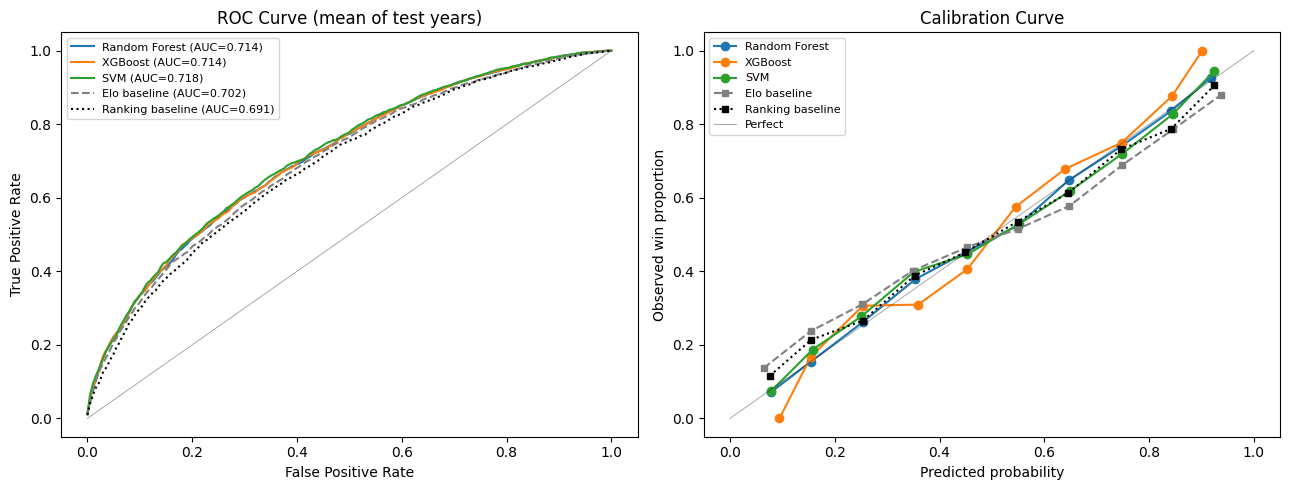

In [14]:
# ===== PENGGANTI BLOK GAMBAR ROC + KALIBRASI (versi R2-10: baseline Elo dan peringkat ikut digambar). Jalankan SETELAH Sel AA ====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fgrid = np.linspace(0, 1, 201); fyr = test.date.dt.year.values; fys = sorted(np.unique(fyr))
def _roc_year(s, lab, **kw):
    tprs, ws, aucs = [], [], []
    for y in fys:
        m = fyr == y; fpr, tpr, _ = roc_curve(y_test[m], s[m])
        tprs.append(np.interp(fgrid, fpr, tpr)); ws.append(int(m.sum())); aucs.append(roc_auc_score(y_test[m], s[m]))
    axes[0].plot(fgrid, np.average(tprs, axis=0, weights=ws), label=f"{lab} (AUC={np.average(aucs, weights=ws):.3f})", **kw)
for n, p in probas.items():
    _roc_year(p, n)
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10)
    axes[1].plot(mean_pred, frac_pos, marker="o", label=n)
_roc_year(test.elo_diff.values, "Elo baseline", ls="--", color="gray"); _roc_year(test.rank_diff_log.values, "Ranking baseline", ls=":", color="black")
for n, c in (("Elo (expected score)", "gray"), ("Ranking (recalibrated)", "black")):
    frac_pos, mean_pred = calibration_curve(y_test, base_probs[n], n_bins=10)
    axes[1].plot(mean_pred, frac_pos, marker="s", ms=4, ls="--" if "Elo" in n else ":", color=c, label=n.replace("Elo (expected score)", "Elo baseline").replace("Ranking (recalibrated)", "Ranking baseline"))
sub = " (mean of test years)" if FIG_LANG == "en" else " (rata-rata tahun uji)"
axes[0].plot([0, 1], [0, 1], "k-", lw=.6, alpha=.4); axes[0].set(title=L["roc"] + sub, xlabel="False Positive Rate", ylabel="True Positive Rate")
axes[1].plot([0, 1], [0, 1], "k-", lw=.6, alpha=.4, label=L["perfect"]); axes[1].set(title=L["calib"], xlabel=L["xlab"], ylabel=L["ylab"])
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig2_roc_kalibrasi_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

R2-11

,Predictor,Bin,n,Mean predicted,Observed frequency,95% CI (Wilson),Gap (observed - predicted),CI covers predicted
0,Random Forest,0.0-0.1,99,0.0779,0.0707,0.035 to 0.139,-0.0072,True
1,Random Forest,0.1-0.2,427,0.1547,0.1546,0.123 to 0.192,-0.0001,True
2,Random Forest,0.2-0.3,958,0.2538,0.2620,0.235 to 0.291,0.0082,True
3,Random Forest,0.3-0.4,1271,0.3539,0.3784,0.352 to 0.405,0.0245,True
4,Random Forest,0.4-0.5,1550,0.4520,0.4535,0.429 to 0.478,0.0016,True
5,Random Forest,0.5-0.6,1587,0.5492,0.5243,0.500 to 0.549,-0.0249,False
6,Random Forest,0.6-0.7,1189,0.6467,0.6476,0.620 to 0.674,0.0009,True
7,Random Forest,0.7-0.8,774,0.7471,0.7403,0.708 to 0.770,-0.0067,True
8,Random Forest,0.8-0.9,510,0.8414,0.8353,0.801 to 0.865,-0.0061,True
9,Random Forest,0.9-1.0,82,0.9184,0.9268,0.849 to 0.966,0.0084,True


,Bins used,Min n,Max n,Bins with n < 100,Share of matches in bins 0.2-0.8 (%),Bins whose CI misses the diagonal
Model,,,,,,
Random Forest,10,82,1587,2,86.8,1
XGBoost,10,2,2385,2,91.9,5
SVM,10,94,1356,1,82.7,5


Predictor,Random Forest,XGBoost,SVM
ROC-AUC (yearly mean),0.7137,0.7139,0.7178
"ECE, 10 equal-width bins",0.0109,0.0378,0.0261
ECE 95% CI,0.0102 to 0.0243,0.0215 to 0.0585,0.0191 to 0.0375
"ECE, 10 equal-count bins",0.0142,0.0406,0.0257
Calibration slope,0.972,1.134,0.878
Slope 95% CI,0.912 to 1.035,1.021 to 1.306,0.824 to 0.932
Calibration intercept,-0.003,-0.005,-0.005
Intercept 95% CI,-0.046 to 0.049,-0.047 to 0.046,-0.049 to 0.046
Calibration-in-the-large,-0.003,-0.006,-0.003
CITL 95% CI,-0.046 to 0.049,-0.047 to 0.043,-0.049 to 0.050


Kemiringan < 1: terlalu yakin (overconfident); > 1: kurang yakin. Intersep dan CITL > 0: peluang pemain 1 menang diremehkan.


Slope                          ECE                        
Test year       2023   2024   2025   2026    2023    2024    2025    2026
Predictor                                                                
Random Forest  0.888  1.035  0.947  1.084  0.0281  0.0190  0.0348  0.0335
SVM            0.791  0.929  0.876  0.978  0.0397  0.0359  0.0294  0.0355
XGBoost        0.884  1.026  3.101  3.397  0.0290  0.0232  0.0925  0.1045

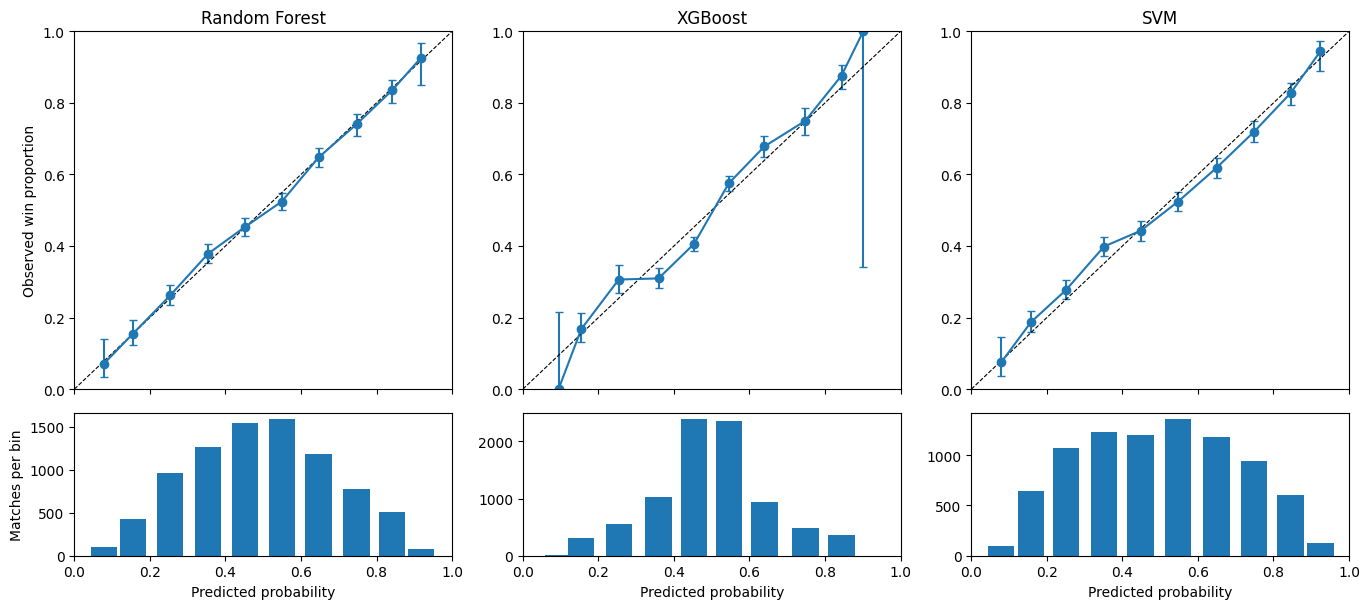

In [ ]:
# ===== SEL AB: ANALISIS KALIBRASI LENGKAP (R2-11). Butuh test, y_test, probas; base_probs dari Sel AA bila ada. Jalankan setelah Sel AA =====
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]
ABB = 1000                                                                # resampel bootstrap (blok bulan kalender)
NBIN = 10                                                                 # jumlah kelas probabilitas
_ya = np.asarray(y_test); _ty = test.date.dt.year.values; _na = len(_ya)
_PR = {n: np.asarray(p) for n, p in probas.items()}
if "base_probs" in globals():
    _PR.update({k: np.asarray(v) for k, v in base_probs.items()})
_MODELS = list(probas)

def _logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def _calfit(p, y):                                                         # kalibrasi linear: logit(P(y=1)) = a + b * logit(p)
    lr = LogisticRegression(C=1e9, max_iter=1000).fit(_logit(p)[:, None], y)
    return float(lr.intercept_[0]), float(lr.coef_[0, 0])
def _citl(p, y):                                                           # 'calibration-in-the-large': intercept dengan kemiringan dikunci = 1 (Newton)
    z = _logit(p); a = 0.0
    for _ in range(25):
        q = 1 / (1 + np.exp(-(a + z))); a += (y - q).sum() / max((q * (1 - q)).sum(), 1e-12)
    return float(a)
def _wilson(k, n, z=1.96):
    ph = k / n; d = 1 + z * z / n; c = (ph + z * z / (2 * n)) / d; h = z * np.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / d
    return c - h, c + h
def _ece_u(p, y, bins=NBIN):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e
def _ece_q(p, y, bins=NBIN):                                               # kelas berisi jumlah laga sama (kuantil)
    o = np.argsort(p, kind="stable"); e = 0.0
    for ix in np.array_split(o, bins): e += len(ix) / len(p) * abs(p[ix].mean() - y[ix].mean())
    return e
def _murphy(p, y, bins=NBIN):
    b = np.minimum((p * bins).astype(int), bins - 1); rel = res = 0.0; ob = y.mean()
    for k in range(bins):
        m = b == k
        if m.any(): rel += m.mean() * (p[m].mean() - y[m].mean()) ** 2; res += m.mean() * (y[m].mean() - ob) ** 2
    return rel, res, ob * (1 - ob)
def _wauc_b(p):
    a, w = [], []
    for yy in OUTER_YEARS:
        k = _ty == yy
        if k.sum() and len(np.unique(_ya[k])) == 2: a.append(roc_auc_score(_ya[k], p[k])); w.append(int(k.sum()))
    return float(np.average(a, weights=w))

# ---------- 1. tabel kelas (prosedur: 10 kelas berlebar sama pada [0,1]; kelas k memuat p dalam [k/10, (k+1)/10), kelas terakhir tertutup) ----------
_abr = []
for n_, p_ in _PR.items():
    b = np.minimum((p_ * NBIN).astype(int), NBIN - 1)
    for k in range(NBIN):
        m = b == k
        if not m.any(): continue
        kk, nn = int(_ya[m].sum()), int(m.sum()); lo, hi = _wilson(kk, nn)
        _abr.append({"Predictor": n_, "Bin": f"{k / NBIN:.1f}-{(k + 1) / NBIN:.1f}", "n": nn, "Mean predicted": round(float(p_[m].mean()), 4),
                     "Observed frequency": round(kk / nn, 4), "95% CI (Wilson)": f"{lo:.3f} to {hi:.3f}",
                     "Gap (observed - predicted)": round(kk / nn - float(p_[m].mean()), 4), "CI covers predicted": bool(lo <= p_[m].mean() <= hi)})
t_cbin = pd.DataFrame(_abr)
display(t_cbin[t_cbin.Predictor.isin(_MODELS)])
sumr = []
for n_ in _MODELS:
    d = t_cbin[t_cbin.Predictor == n_]
    sumr.append({"Model": n_, "Bins used": len(d), "Min n": int(d.n.min()), "Max n": int(d.n.max()), "Bins with n < 100": int((d.n < 100).sum()),
                 "Share of matches in bins 0.2-0.8 (%)": round(100 * float(d[d.Bin.isin(["0.2-0.3", "0.3-0.4", "0.4-0.5", "0.5-0.6", "0.6-0.7", "0.7-0.8"])].n.sum() / _na), 1),
                 "Bins whose CI misses the diagonal": int((~d["CI covers predicted"]).sum())})
t_csum = pd.DataFrame(sumr).set_index("Model"); display(t_csum)

# ---------- 2. statistik kalibrasi, dengan selang bootstrap blok bulan ----------
_mo = pd.factorize(test.date.dt.to_period("M"))[0]; _o = np.argsort(_mo, kind="stable"); _bd = np.cumsum(np.r_[0, np.bincount(_mo)])
_bl = [_o[_bd[i]:_bd[i + 1]] for i in range(len(_bd) - 1)]; _rg = np.random.default_rng(SEED)
_ixs = [np.concatenate([_bl[g] for g in _rg.integers(0, len(_bl), len(_bl))]) for _ in range(ABB)]
_abr = []
for n_, p_ in _PR.items():
    a, s = _calfit(p_, _ya); c0 = _citl(p_, _ya); rel, res, unc = _murphy(p_, _ya)
    bs = np.array([[_ece_u(p_[i], _ya[i]), *_calfit(p_[i], _ya[i]), _citl(p_[i], _ya[i])] for i in _ixs])
    ll = float(log_loss(_ya, p_)); zz = _logit(p_)[:, None]
    lr = LogisticRegression(C=1e9, max_iter=1000).fit(zz, _ya); ll_re = float(log_loss(_ya, lr.predict_proba(zz)[:, 1]))
    _fmt = lambda j, d=3: f"{np.percentile(bs[:, j], 2.5):.{d}f} to {np.percentile(bs[:, j], 97.5):.{d}f}"
    _abr.append({"Predictor": n_, "ROC-AUC (yearly mean)": round(_wauc_b(p_), 4), "ECE, 10 equal-width bins": round(_ece_u(p_, _ya), 4), "ECE 95% CI": _fmt(0, 4),
                 "ECE, 10 equal-count bins": round(_ece_q(p_, _ya), 4), "Calibration slope": round(s, 3), "Slope 95% CI": _fmt(2),
                 "Calibration intercept": round(a, 3), "Intercept 95% CI": _fmt(1), "Calibration-in-the-large": round(c0, 3), "CITL 95% CI": _fmt(3),
                 "Reliability (Murphy)": round(rel, 5), "Resolution (Murphy)": round(res, 5), "Log loss": round(ll, 4),
                 "Log loss after in-sample linear recalibration": round(ll_re, 4), "Calibration loss (log loss)": round(ll - ll_re, 4)})
t_cal = pd.DataFrame(_abr).set_index("Predictor"); display(t_cal.T)
print("Kemiringan < 1: terlalu yakin (overconfident); > 1: kurang yakin. Intersep dan CITL > 0: peluang pemain 1 menang diremehkan.")

# ---------- 3. per tahun uji: kemiringan, intersep dan ECE ----------
_abr = []
for n_, p_ in _PR.items():
    for yy in OUTER_YEARS:
        k = _ty == yy; a, s = _calfit(p_[k], _ya[k])
        _abr.append({"Predictor": n_, "Test year": yy, "n": int(k.sum()), "Slope": round(s, 3), "Intercept": round(a, 3), "ECE": round(_ece_u(p_[k], _ya[k]), 4)})
t_cyr = pd.DataFrame(_abr); display(t_cyr[t_cyr.Predictor.isin(_MODELS)].pivot(index="Predictor", columns="Test year", values=["Slope", "ECE"]))

t_cbin.to_csv(f"{OUT_DIR}/tabel_kalibrasi_kelas_wilson.csv", index=False); t_csum.to_csv(f"{OUT_DIR}/tabel_kalibrasi_ringkasan_kelas.csv")
t_cal.to_csv(f"{OUT_DIR}/tabel_kalibrasi_statistik.csv"); t_cyr.to_csv(f"{OUT_DIR}/tabel_kalibrasi_per_tahun.csv", index=False)

# ---------- 4. gambar tambahan (untuk repositori): kurva keandalan dengan selang Wilson dan histogram jumlah laga per kelas ----------
fig, axs = plt.subplots(2, len(_MODELS), figsize=(4.6 * len(_MODELS), 6.2), gridspec_kw={"height_ratios": [3, 1.2]}, sharex=True)
for j, n_ in enumerate(_MODELS):
    d = t_cbin[t_cbin.Predictor == n_]; lo = [float(s.split(" to ")[0]) for s in d["95% CI (Wilson)"]]; hi = [float(s.split(" to ")[1]) for s in d["95% CI (Wilson)"]]
    axs[0, j].errorbar(d["Mean predicted"], d["Observed frequency"], yerr=[d["Observed frequency"] - lo, np.array(hi) - d["Observed frequency"]], fmt="o-", capsize=3)
    axs[0, j].plot([0, 1], [0, 1], "k--", lw=.8); axs[0, j].set(title=n_, ylabel="Observed win proportion" if j == 0 else "", xlim=(0, 1), ylim=(0, 1))
    axs[1, j].bar(d["Mean predicted"], d["n"], width=.07); axs[1, j].set(xlabel="Predicted probability", ylabel="Matches per bin" if j == 0 else "")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_kalibrasi_detail_en.png", dpi=300, bbox_inches="tight"); plt.show()

R2-12

In [ ]:
# ===== SEL AC: KINERJA PER MUSIM, PERMUKAAN DAN KARAKTERISTIK TURNAMEN (R2-12). Butuh df, test, y_test, preds (setelah sel evaluasi) =====
from collections import defaultdict
from scipy import stats
from sklearn.metrics import roc_auc_score, log_loss
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]
ACB = 2000                                                                  # resampel bootstrap (klaster = turnamen)
_ya = np.asarray(y_test); _na = len(_ya); _MN = list(preds)                  # urutan model: Random Forest, XGBoost, SVM
RF_, XG_, SV_ = _MN[0], _MN[1], _MN[2]

# ---------- 1. metadata laga uji, sejajar dengan `test` (dari df) ----------
_dd = df.reset_index(drop=True)
_c = defaultdict(int); _k1 = np.empty(len(_dd), int); _k2 = np.empty(len(_dd), int)
for _i, (_a, _b) in enumerate(zip(_dd.winner_id.values, _dd.loser_id.values)):
    _k1[_i], _k2[_i] = _c[_a], _c[_b]; _c[_a] += 1; _c[_b] += 1
_mk = (_k1 >= MIN_PRIOR_MATCHES) & (_k2 >= MIN_PRIOR_MATCHES) & (_dd.tourney_date >= pd.Timestamp(TEST_START_DATE)).values
_zt = _dd[_mk].reset_index(drop=True)
assert len(_zt) == len(test) and (_zt.tourney_date.values == test.date.values).all(), "Laga uji tidak sejajar dengan `test`"
_tid = pd.factorize(_zt.tourney_id)[0]; _G = int(_tid.max() + 1); _yr = test.date.dt.year.values
_lvl = _zt.tourney_level.map({"G": "Grand Slam", "M": "Masters 1000", "A": "ATP 500/250"}).fillna("Other (Davis Cup, Finals, Olympics)")
_rnd = _zt["round"].map({"R128": "R128-R32", "R64": "R128-R32", "R32": "R128-R32", "R16": "R16", "QF": "QF", "SF": "SF-F", "F": "SF-F", "BR": "SF-F", "RR": "Round robin"}).fillna("Other")
_xp = np.minimum(test.n1.values, test.n2.values)
_gap = np.abs(test.elo_diff.values); _q = np.quantile(_gap, [1 / 3, 2 / 3])
DIMS = {"Season (test year)": pd.Series(_yr).astype(str).values, "Surface": _zt.surface.values, "Tournament level": _lvl.values,
        "Match format": np.where(_zt.best_of.values == 5, "Best of 5", "Best of 3"), "Round": _rnd.values,
        "Experience (fewer prior matches of the two players)": np.where(_xp < 50, "10-49", np.where(_xp < 200, "50-199", "200+")),
        "Elo gap between the players (tertiles)": np.where(_gap <= _q[0], "Close (lowest third)", np.where(_gap <= _q[1], "Middle third", "Large (highest third)"))}

# ---------- 2. ketepatan prediksi per model dan baseline Elo ----------
_cor = {m: (np.asarray(preds[m]) == _ya).astype(float) for m in _MN}; _cor["Elo baseline"] = ((test.elo_diff.values > 0).astype(int) == _ya).astype(float)
_pb = {m: np.asarray(probas[m]) for m in _MN}
_CON = {"SVM - Random Forest": (SV_, RF_), "SVM - XGBoost": (SV_, XG_), "SVM - Elo baseline": (SV_, "Elo baseline")}

# ---------- 3. bootstrap klaster turnamen lewat bobot (satu undian untuk semua subkelompok) ----------
_rg = np.random.default_rng(SEED); Cm = _rg.multinomial(_G, np.ones(_G) / _G, size=ACB).astype(float)          # ACB x G
def _cl(v, mask): return np.bincount(_tid, weights=v * mask, minlength=_G)
def _ci(est): return f"{np.percentile(est, 2.5) * 100:.1f} to {np.percentile(est, 97.5) * 100:.1f}"
def _wauc_g(p, mask):
    a, w = [], []
    for yy in OUTER_YEARS:
        k = mask & (_yr == yy)
        if k.sum() >= 30 and len(np.unique(_ya[k])) == 2: a.append(roc_auc_score(_ya[k], p[k])); w.append(int(k.sum()))
    return round(float(np.average(a, weights=w)), 4) if a else np.nan

_acr = []
for dim, lab in DIMS.items():
    for lev in pd.unique(lab) if dim != "Season (test year)" else sorted(pd.unique(lab)):
        mask = (lab == lev).astype(float); mb = mask > 0; n_g = int(mb.sum()); den = Cm @ _cl(np.ones(_na), mask)
        r = {"Dimension": dim, "Level": lev, "n": n_g, "Share (%)": round(100 * n_g / _na, 1), "Tournaments": int(len(np.unique(_tid[mb])))}
        for m in _cor:
            est = (Cm @ _cl(_cor[m], mask)) / den; r[f"Acc {m}"] = round(100 * float(_cor[m][mb].mean()), 2); r[f"CI {m}"] = _ci(est)
        for cname, (a_, b_) in _CON.items():
            d_ = _cor[a_] - _cor[b_]; est = (Cm @ _cl(d_, mask)) / den
            r[cname + " (pts)"] = round(100 * float(d_[mb].mean()), 2); r[cname + " CI"] = _ci(est)
            r[cname + ": without this subgroup (pts)"] = round(100 * float((d_.sum() - d_[mb].sum()) / max(_na - n_g, 1)), 2)
        for m in _MN: r[f"AUC {m}"] = _wauc_g(_pb[m], mb)
        r["AUC Elo baseline"] = _wauc_g(test.elo_diff.values, mb)
        r["Small subgroup (n<100)"] = n_g < 100
        _acr.append(r)
t_sg = pd.DataFrame(_acr)

# ---------- 4. tampilan ringkas ----------
_acshow = t_sg[["Dimension", "Level", "n", f"Acc {RF_}", f"Acc {XG_}", f"Acc {SV_}", "Acc Elo baseline", "SVM - Random Forest (pts)", "SVM - Random Forest CI",
             "SVM - XGBoost (pts)", "SVM - XGBoost CI", "SVM - Elo baseline (pts)", "SVM - Elo baseline CI"]]
for dim in DIMS: display(_acshow[_acshow.Dimension == dim].drop(columns="Dimension").set_index("Level"))

# ---------- 5. uji heterogenitas: apakah keunggulan SVM berbeda antar tingkat? (Wald, kovarians robust klaster turnamen) ----------
def _wald(d, lab):
    lv = list(pd.unique(lab)); lv.sort(); X = np.column_stack([np.ones(_na)] + [(lab == l).astype(float) for l in lv[1:]]); df_ = X.shape[1] - 1
    XtXi = np.linalg.pinv(X.T @ X); beta = XtXi @ (X.T @ d); u = d - X @ beta
    S = np.zeros((X.shape[1], X.shape[1]))
    sc = np.column_stack([np.bincount(_tid, weights=X[:, j] * u, minlength=_G) for j in range(X.shape[1])])
    S = sc.T @ sc * _G / (_G - 1); V = XtXi @ S @ XtXi
    b, Vs = beta[1:], V[1:, 1:]; w = float(b @ np.linalg.pinv(Vs) @ b)
    return w, df_, float(stats.chi2.sf(w, df_))
hr = []
for dim, lab in DIMS.items():
    for cname, (a_, b_) in _CON.items():
        w, dfree, p = _wald(_cor[a_] - _cor[b_], lab); hr.append({"Dimension": dim, "Contrast": cname, "Wald chi2": round(w, 2), "df": dfree, "p": round(p, 4)})
t_het = pd.DataFrame(hr)
o = np.argsort(t_het.p.values); m_ = len(o); adj = np.empty(m_); run = 0.0
for r_, i in enumerate(o): run = max(run, (m_ - r_) * t_het.p.values[i]); adj[i] = min(1.0, run)
t_het["Holm (all 21 tests)"] = np.round(adj, 4); display(t_het)
print("Keunggulan SVM per tingkat: tidak ada bukti heterogenitas bila p (dan Holm) besar; ini analisis eksploratori (21 uji).")

t_sg.to_csv(f"{OUT_DIR}/tabel_subkelompok_kinerja.csv", index=False); t_het.to_csv(f"{OUT_DIR}/tabel_subkelompok_heterogenitas.csv", index=False)

,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
2023,2388,63.99,63.82,64.66,63.65,0.67,-0.3 to 1.7,0.84,-0.2 to 1.9,1.01,-0.2 to 2.2
2024,2575,64.89,64.85,65.01,64.27,0.12,-0.9 to 1.0,0.16,-0.7 to 1.0,0.74,-0.5 to 1.8
2025,2300,64.83,64.83,65.83,63.57,1.00,-0.0 to 2.0,1.00,0.1 to 1.9,2.26,0.9 to 3.6
2026,1184,66.22,65.96,67.40,65.46,1.18,-0.5 to 2.5,1.44,0.0 to 2.7,1.94,-0.7 to 3.9


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
Hard,4905,64.85,64.85,65.48,64.65,0.63,0.0 to 1.2,0.63,-0.0 to 1.3,0.84,-0.0 to 1.6
Clay,2730,64.73,64.43,65.35,62.34,0.62,-0.5 to 1.7,0.92,0.0 to 1.9,3.00,1.8 to 4.2
Grass,812,64.78,64.78,65.76,66.38,0.99,-0.8 to 3.1,0.99,-0.6 to 3.1,-0.62,-2.7 to 1.5


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
ATP 500/250,4229,62.40,62.24,63.40,62.43,0.99,0.3 to 1.8,1.16,0.4 to 1.9,0.97,0.0 to 2.0
Grand Slam,1487,71.62,72.09,72.16,70.81,0.54,-0.6 to 1.6,0.07,-0.8 to 0.8,1.34,0.0 to 2.6
"Other (Davis Cup, Finals, Olympics)",389,64.27,63.75,63.75,63.75,-0.51,-3.4 to 2.4,0.00,-2.4 to 2.4,0.00,-3.5 to 3.0
Masters 1000,2342,64.90,64.65,65.24,62.81,0.34,-0.8 to 1.3,0.60,-0.3 to 1.5,2.43,0.9 to 3.8


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
Best of 3,6928,63.32,63.12,64.09,62.66,0.77,0.2 to 1.4,0.97,0.4 to 1.5,1.43,0.6 to 2.2
Best of 5,1519,71.56,71.96,71.76,70.51,0.20,-1.1 to 1.3,-0.20,-1.2 to 0.6,1.25,-0.1 to 2.5


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
R128-R32,5091,64.68,64.56,65.45,63.78,0.77,0.1 to 1.5,0.88,0.3 to 1.6,1.67,0.7 to 2.5
Round robin,430,61.86,61.16,61.40,62.79,-0.47,-2.8 to 2.2,0.23,-1.9 to 2.7,-1.40,-4.3 to 1.8
R16,1522,65.44,65.51,66.43,64.39,0.99,-0.1 to 2.0,0.92,-0.2 to 2.0,2.04,0.4 to 3.8
QF,767,67.14,67.80,66.75,66.10,-0.39,-2.3 to 1.4,-1.04,-2.8 to 0.8,0.65,-1.4 to 2.9
SF-F,637,63.42,62.64,64.52,64.05,1.10,-0.8 to 3.0,1.88,0.0 to 3.8,0.47,-2.4 to 3.1


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
50-199,4027,64.42,64.32,65.43,63.79,1.02,0.2 to 1.8,1.12,0.4 to 1.9,1.64,0.6 to 2.7
200+,1724,68.85,68.74,69.32,68.04,0.46,-0.6 to 1.7,0.58,-0.4 to 1.7,1.28,-0.2 to 2.8
10-49,2696,62.80,62.72,63.06,61.94,0.26,-0.7 to 1.3,0.33,-0.7 to 1.3,1.11,-0.2 to 2.4


,n,Acc Random Forest,Acc XGBoost,Acc SVM,Acc Elo baseline,SVM - Random Forest (pts),SVM - Random Forest CI,SVM - XGBoost (pts),SVM - XGBoost CI,SVM - Elo baseline (pts),SVM - Elo baseline CI
Level,,,,,,,,,,,
Large (highest third),2816,76.92,77.02,77.06,77.02,0.14,-0.1 to 0.4,0.04,-0.1 to 0.2,0.04,-0.2 to 0.3
Close (lowest third),2816,54.55,54.30,55.72,52.63,1.17,-0.3 to 2.6,1.42,0.1 to 2.8,3.09,1.1 to 5.0
Middle third,2815,62.95,62.81,63.62,62.56,0.67,-0.1 to 1.4,0.82,0.1 to 1.5,1.07,0.2 to 1.9


,Dimension,Contrast,Wald chi2,df,p,Holm (all 21 tests)
0,Season (test year),SVM - Random Forest,2.25,3,0.5218,1.0000
1,Season (test year),SVM - XGBoost,3.43,3,0.3306,1.0000
2,Season (test year),SVM - Elo baseline,3.53,3,0.3172,1.0000
3,Surface,SVM - Random Forest,0.12,2,0.9409,1.0000
4,Surface,SVM - XGBoost,0.33,2,0.8463,1.0000
5,Surface,SVM - Elo baseline,11.62,2,0.0030,0.0600
6,Tournament level,SVM - Random Forest,1.86,3,0.6029,1.0000
7,Tournament level,SVM - XGBoost,4.10,3,0.2505,1.0000
8,Tournament level,SVM - Elo baseline,3.46,3,0.3260,1.0000
9,Match format,SVM - Random Forest,0.78,1,0.3774,1.0000


Keunggulan SVM per tingkat: tidak ada bukti heterogenitas bila p (dan Holm) besar; ini analisis eksploratori (21 uji).


R2-13

In [ ]:
# ===== SEL AD: ABLASI FITUR (R2-13). Butuh data, FEATURES, FROZEN, fold_params, probas, preds, TRAIN_START_YEAR, TEST_START_DATE, SEED, OUT_DIR =====
# Prosedur sama dengan evaluasi utama: latih 2010..Y-1, uji tahun Y (Y = 2023..2026), digabung. Hanya kolom fitur yang berubah.
# Hiperparameter: tiap lipatan memakai parameter model penuh dari Sel B (agar yang berubah hanya fitur). Pemeriksaan dengan tuning ulang ada di Sel AD2.
import time, ast, os, re, joblib
from scipy import sparse
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from IPython.display import display

OUTER_YEARS = [2023, 2024, 2025, 2026]
ADB = globals().get("ADB", 1000)                                           # resampel bootstrap (blok bulan kalender)
AD_SVM_SETS = globals().get("AD_SVM_SETS", ["A1", "A2", "A3", "A7", "A8"])  # himpunan fitur yang dijalankan untuk SVM (paling lama)

# ---------- 1. kelompok fitur dan himpunan fitur ----------
GROUPS = {"Elo (general and surface)": ["elo_diff", "elo_surface_diff"],
          "Surface and match context": ["best_of_5", "is_slam", "surf_hard", "surf_clay", "surf_grass"],
          "Ranking and points": ["rank_diff_log", "points_diff_log"],
          "Recent form and surface win rate": ["form_diff", "surface_wr_diff"],
          "Head-to-head": ["h2h_diff"],
          "Fatigue (14-day load)": ["fatigue_diff"],
          "Experience (match count)": ["experience_diff"],
          "Age, height, handedness": ["age_diff", "height_diff", "lefty_diff"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES), "Pengelompokan fitur tidak sama dengan FEATURES"
_gk = list(GROUPS); G_ELO, G_CTX, G_RNK, G_FRM, G_H2H, G_FAT, G_EXP, G_PHY = _gk
def _fs(*gs): return [f for f in FEATURES if any(f in GROUPS[g] for g in gs)]            # urutan kolom mengikuti FEATURES

_SET, _ORDER, _CODE = {}, [], {}                                           # kunci = tuple fitur; himpunan identik dihitung sekali
def _reg(code, label, feats):
    key = tuple(feats)
    if key not in _SET: _SET[key] = {"codes": [], "labels": []}; _ORDER.append(key)
    _SET[key]["codes"].append(code); _SET[key]["labels"].append(label); _CODE[code] = key
_reg("A1", "Elo difference only", ["elo_diff"])
_reg("A2", "A1 + surface-specific Elo", _fs(G_ELO))
_reg("A3", "A2 + surface and match context", _fs(G_ELO, G_CTX))
_reg("A4", "A3 + ranking and points", _fs(G_ELO, G_CTX, G_RNK))
_reg("A5", "A4 + recent form and surface win rate", _fs(G_ELO, G_CTX, G_RNK, G_FRM))
_reg("A6", "A5 + head-to-head", _fs(G_ELO, G_CTX, G_RNK, G_FRM, G_H2H))
_reg("A7", "A6 + fatigue and experience", _fs(G_ELO, G_CTX, G_RNK, G_FRM, G_H2H, G_FAT, G_EXP))
_reg("A8", "A7 + age, height, handedness (full set)", list(FEATURES))
for g in _gk: _reg(f"w/o {g}", f"Full set without {g}", [f for f in FEATURES if f not in GROUPS[g]])
for g in (G_RNK, G_FRM, G_H2H, G_FAT, G_EXP, G_PHY): _reg(f"A3 + {g}", f"A3 + {g}", _fs(G_ELO, G_CTX, g))

# ---------- 2. kerangka evaluasi (sama dengan Sel Y1) ----------
_te = (data.date >= TEST_START_DATE).values; _ya = data.date.dt.year.values; _yt = data.target.values
_yv = _yt[_te]; _yr = _ya[_te]; _fy = [y for y in OUTER_YEARS if (_yr == y).any()]; _nte = int(_te.sum())
_MODELS = list(FROZEN)
_adfp = pd.DataFrame(fold_params)
def _adpar(name, Y):
    s = _adfp[(_adfp.Model == name) & (_adfp["Tahun uji"] == Y)]["Parameter"].iloc[0]
    try: return ast.literal_eval(s)
    except Exception: return eval(s, {"np": np, "nan": np.nan, "inf": np.inf})
def _adfit(cols, name, Y, params):
    trm = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")).values; tem = (_ya == Y) & _te
    m = clone(FROZEN[name][0]).set_params(**params)
    if name != "SVM": m.set_params(clf__n_jobs=-1)
    m.fit(data.loc[trm, list(cols)], _yt[trm]); X = data.loc[tem, list(cols)]
    return m.decision_function(X) if name == "SVM" else m.predict_proba(X)[:, 1]

# ---------- 3. latih (dengan penyimpanan agar bisa dilanjutkan bila sesi terputus) ----------
_adf = f"{OUT_DIR}/ad_scores.joblib"; _sig = (len(data), _nte, tuple(FEATURES))
_adS = {}
if os.path.exists(_adf):
    try:
        _ld = joblib.load(_adf)
        if _ld.get("sig") == _sig: _adS.update(_ld["S"]); print(f"Dimuat {len(_adS)} hasil sebelumnya dari {_adf}")
    except Exception as e: print("Berkas lanjutan tidak terbaca, mulai dari awal:", e)
def _need_svm(key): return any(c in AD_SVM_SETS for c in _SET[key]["codes"])
_todo = [(k, n) for k in _ORDER for n in _MODELS if (n != "SVM" or _need_svm(k)) and (k, n) not in _adS]
print(f"{len(_ORDER)} himpunan fitur unik; {len(_todo)} kombinasi (himpunan x model) akan dilatih, masing-masing {len(_fy)} lipatan.")
_t00 = time.perf_counter()
for _i, (k, n) in enumerate(_todo, 1):
    _t0 = time.perf_counter(); out = np.full(_nte, np.nan)
    for Y in _fy: out[_yr == Y] = _adfit(k, n, Y, _adpar(n, Y))
    _adS[(k, n)] = out
    print(f"[{_i}/{len(_todo)}] {n:13s} | {'/'.join(_SET[k]['codes'])[:48]:48s} | {len(k):2d} fitur | {time.perf_counter() - _t0:5.0f} s | total {(time.perf_counter() - _t00) / 60:.1f} menit")
    joblib.dump({"sig": _sig, "S": _adS}, _adf)

# ---------- 4. sanity: himpunan penuh harus sama dengan Sel B ----------
_full = tuple(FEATURES)
for n in _MODELS:
    if (_full, n) not in _adS: continue
    if n != "SVM": print(f"A8 vs Sel B, {n}: maks |selisih probabilitas| = {np.abs(_adS[(_full, n)] - probas[n]).max():.2e}")
    else: print(f"A8 vs Sel B, SVM: akurasi tanda keputusan {np.mean((_adS[(_full, n)] >= 0).astype(int) == _yv):.4f} | akurasi probabilitas Platt {np.mean(preds[n] == _yv):.4f}")

# ---------- 5. metrik dan bootstrap blok bulan kalender (resampel dipakai bersama sehingga selisih berpasangan) ----------
_mo = pd.PeriodIndex(data.date[_te].values, freq="M"); _codes = pd.factorize(_mo)[0]; _K = int(_codes.max() + 1)
_rb = np.random.default_rng(SEED)
_W = np.stack([np.bincount(_rb.integers(0, _K, _K), minlength=_K) for _ in range(ADB)])[:, _codes].astype(float)      # ADB x n
_Ws = _W.sum(1)
_one = np.ones((1, _nte))
def _aucprep(score):
    P = []
    for yy in _fy:
        k = np.where(_yr == yy)[0]; u, g = np.unique(score[k], return_inverse=True)
        P.append((k, _yv[k].astype(float), sparse.csr_matrix((np.ones(len(k)), (np.arange(len(k)), g)), shape=(len(k), len(u)))))
    return P
def _aucw(P, Wm):
    """ROC-AUC rata-rata tertimbang per tahun uji (bobot = jumlah laga tahun itu), tangani skor kembar; Wm = bobot resampel (B x n)."""
    r, t = [], []
    for k, y, ind in P:
        Wk = Wm[:, k]; pos = (ind.T @ (Wk * y).T).T; neg = (ind.T @ (Wk * (1 - y)).T).T
        num = (pos * (np.cumsum(neg, 1) - neg + 0.5 * neg)).sum(1); den = pos.sum(1) * neg.sum(1); ok = den > 0
        r.append(np.where(ok, num / np.where(ok, den, 1), 0.0)); t.append(np.where(ok, Wk.sum(1), 0.0))     # tahun yang tidak terambil sama sekali diberi bobot 0
    r, t = np.array(r), np.array(t); return (r * t).sum(0) / t.sum(0)
def _stat(score, svm):
    cor = ((score >= (0 if svm else 0.5)).astype(int) == _yv).astype(float); P = _aucprep(score)
    s = {"acc": (cor.mean(), (_W @ cor) / _Ws), "auc": (float(_aucw(P, _one)[0]), _aucw(P, _W))}
    if not svm:
        p = np.clip(score, 1e-15, 1 - 1e-15); ll = -(_yv * np.log(p) + (1 - _yv) * np.log(1 - p)); br = (score - _yv) ** 2
        s["ll"] = (ll.mean(), (_W @ ll) / _Ws); s["br"] = (br.mean(), (_W @ br) / _Ws)
    return s
_ST = {}
def _get(key, n):
    if (key, n) not in _ST: _ST[(key, n)] = _stat(_adS[(key, n)], n == "SVM")
    return _ST[(key, n)]
_ci = lambda b, sc=1, d=2: f"{np.percentile(b, 2.5) * sc:.{d}f} to {np.percentile(b, 97.5) * sc:.{d}f}"

# acuan: aturan Elo tanpa model (elo_diff > 0) dan skor elo_diff
_elo = data.elo_diff.values[_te]; _eloP = _aucprep(_elo); _ecor = ((_elo > 0).astype(int) == _yv).astype(float)
def _wauc_sk(sc):
    a = [roc_auc_score(_yv[_yr == y], sc[_yr == y]) for y in _fy]; w = [int((_yr == y).sum()) for y in _fy]; return float(np.average(a, weights=w))
_ELO = {"acc": _ecor.mean(), "auc": float(_aucw(_eloP, _one)[0]), "acc_b": (_W @ _ecor) / _Ws}

assert abs(_ELO["auc"] - _wauc_sk(_elo)) < 1e-9, "AUC tertimbang tidak sama dengan sklearn"
_kk = next(iter(_adS)); assert abs(_get(*_kk)["auc"][0] - _wauc_sk(_adS[_kk])) < 1e-9, "AUC model tidak sama dengan sklearn"
print("Pemeriksaan: AUC rata-rata tahunan identik dengan roc_auc_score (sklearn).")
for _k in _ORDER:
    if len(_SET[_k]["codes"]) > 1: print(f"Himpunan identik (dihitung sekali): {' = '.join(_SET[_k]['codes'])}")
# ---------- 6. tabel utama: kinerja tiap himpunan fitur ----------
_rows = []
for key in _ORDER:
    for n in _MODELS:
        if (key, n) not in _adS: continue
        s = _get(key, n)
        _rows.append({"Kind": "ladder" if re.match(r"^A\d$", _SET[key]["codes"][0]) else "other", "Code": _SET[key]["codes"][0], "Feature set": _SET[key]["labels"][0], "Features": len(key), "Model": n,
                      "Accuracy": round(s["acc"][0], 4), "Acc 95% CI": _ci(s["acc"][1], 100, 1),
                      "ROC-AUC (yearly mean)": round(s["auc"][0], 4), "AUC 95% CI": _ci(s["auc"][1], 1, 4),
                      "Log loss": round(s["ll"][0], 4) if "ll" in s else np.nan, "Brier": round(s["br"][0], 4) if "br" in s else np.nan})
t_ad = pd.DataFrame(_rows)
print(f"\nAcuan tanpa model: aturan Elo (elo_diff > 0): akurasi {_ELO['acc']:.4f}, AUC rata-rata tahunan {_ELO['auc']:.4f}")
print("\n=== A. Tangga penambahan fitur (A1 sampai A8) ===")
_lad = t_ad[t_ad.Kind == "ladder"]
display(_lad.pivot(index=["Code", "Feature set", "Features"], columns="Model", values=["Accuracy", "ROC-AUC (yearly mean)"]))
display(_lad.pivot(index=["Code", "Features"], columns="Model", values=["Log loss", "Brier"]).dropna(how="all", axis=1))
print("\n=== B. Satu kelompok dikeluarkan dari himpunan penuh, dan satu kelompok ditambahkan ke A3 ===")
_oth = t_ad[t_ad.Kind == "other"]
display(_oth.pivot(index=["Code", "Features"], columns="Model", values=["Accuracy", "ROC-AUC (yearly mean)"]))

# ---------- 7. selisih berpasangan dengan selang kepercayaan ----------
def _con(label, hi, lo, name=None):
    out = []
    for n in _MODELS:
        kh, kl = _CODE[hi], _CODE[lo]
        if (kh, n) not in _adS or (kl, n) not in _adS: continue
        a, b = _get(kh, n), _get(kl, n)
        da, du = (a["acc"][1] - b["acc"][1]) * 100, a["auc"][1] - b["auc"][1]
        r = {"Analysis": label, "Contrast": name or f"{hi} minus {lo}", "Model": n,
             "dAccuracy (pts)": round((a["acc"][0] - b["acc"][0]) * 100, 2), "dAcc 95% CI": _ci(da),
             "dAUC": round(a["auc"][0] - b["auc"][0], 4), "dAUC 95% CI": _ci(du, 1, 4)}
        if "ll" in a:
            dl = a["ll"][1] - b["ll"][1]; r.update({"dLog loss": round(a["ll"][0] - b["ll"][0], 4), "dLL 95% CI": _ci(dl, 1, 4)})
        r["Acc CI excludes 0"] = bool(np.percentile(da, 2.5) > 0 or np.percentile(da, 97.5) < 0)
        r["AUC CI excludes 0"] = bool(np.percentile(du, 2.5) > 0 or np.percentile(du, 97.5) < 0)
        out.append(r)
    return out
_cr = []
for lo, hi in zip(["A1", "A2", "A3", "A4", "A5", "A6", "A7"], ["A2", "A3", "A4", "A5", "A6", "A7", "A8"]): _cr += _con("Step added in the ladder", hi, lo)
for lo in ("A1", "A2", "A3"): _cr += _con("Full set against a smaller set", "A8", lo)
_cr += _con("Context added to Elo", "A3", "A2")
for g in _gk: _cr += _con("Group removed from the full set (A8 minus the group)", "A8", f"w/o {g}", f"Removing: {g}")
for g in (G_RNK, G_FRM, G_H2H, G_FAT, G_EXP, G_PHY): _cr += _con("Group added to Elo + context (A3)", f"A3 + {g}", "A3", f"Adding: {g}")
t_adc = pd.DataFrame(_cr)
print("\n=== C. Selisih berpasangan (poin persen untuk akurasi; selang dari bootstrap blok bulan kalender) ===")
for an, d in t_adc.groupby("Analysis", sort=False):
    print(f"\n-- {an}"); display(d.drop(columns="Analysis").reset_index(drop=True))
print("\nSelang yang tidak memuat nol (akurasi / AUC), per model:")
display(t_adc.groupby(["Model"])[["Acc CI excludes 0", "AUC CI excludes 0"]].sum().astype(int).assign(Contrasts=t_adc.groupby("Model").size()))

# ---------- 8. redundansi: korelasi tiap fitur dengan selisih Elo (tahun latih sebelum 2023) ----------
_trn = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < TEST_START_DATE)).values
_cm = data.loc[_trn, FEATURES].corr(method="spearman")
t_adcor = pd.DataFrame({"Group": [next(g for g in _gk if f in GROUPS[g]) for f in FEATURES], "Feature": FEATURES,
                        "Spearman with elo_diff": [round(float(_cm.loc[f, "elo_diff"]), 3) for f in FEATURES],
                        "Spearman with elo_surface_diff": [round(float(_cm.loc[f, "elo_surface_diff"]), 3) for f in FEATURES]})
print("\n=== D. Korelasi dengan fitur Elo (tahun latih 2010-2022) ===")
display(t_adcor)

t_ad.to_csv(f"{OUT_DIR}/tabel_ablasi_kinerja.csv", index=False)
t_adc.to_csv(f"{OUT_DIR}/tabel_ablasi_selisih.csv", index=False)
t_adcor.to_csv(f"{OUT_DIR}/tabel_ablasi_korelasi.csv", index=False)
print("\nTersimpan: tabel_ablasi_kinerja.csv, tabel_ablasi_selisih.csv, tabel_ablasi_korelasi.csv")
print("Catatan: untuk SVM, akurasi memakai tanda fungsi keputusan dan AUC memakai fungsi keputusan (tanpa kalibrasi Platt); bandingkan hanya antar himpunan fitur.")

20 himpunan fitur unik; 45 kombinasi (himpunan x model) akan dilatih, masing-masing 4 lipatan.
[1/45] Random Forest | A1                                               |  1 fitur |    59 s | total 1.0 menit
[2/45] XGBoost       | A1                                               |  1 fitur |     4 s | total 1.0 menit
[3/45] SVM           | A1                                               |  1 fitur |   196 s | total 4.3 menit
[4/45] Random Forest | A2                                               |  2 fitur |    33 s | total 4.9 menit
[5/45] XGBoost       | A2                                               |  2 fitur |     8 s | total 5.0 menit
[6/45] SVM           | A2                                               |  2 fitur |   185 s | total 8.1 menit
[7/45] Random Forest | A3                                               |  7 fitur |    25 s | total 8.5 menit
[8/45] XGBoost       | A3                                               |  7 fitur |     5 s | total 8.6 menit
[9/45] SVM       

Accuracy          \
Model                                                 Random Forest     SVM   
Code Feature set                             Features                         
A1   Elo difference only                     1               0.6392  0.6406   
A2   A1 + surface-specific Elo               2               0.6401  0.6407   
A3   A2 + surface and match context          7               0.6413  0.6402   
A4   A3 + ranking and points                 9               0.6483     NaN   
A5   A4 + recent form and surface win rate   11              0.6457     NaN   
A6   A5 + head-to-head                       12              0.6458     NaN   
A7   A6 + fatigue and experience             14              0.6458  0.6466   
A8   A7 + age, height, handedness (full set) 17              0.6480  0.6555   

                                                               \
Model                                                 XGBoost   
Code Feature set                             Features           
A1   Elo difference only                     1         0.6416   
A2   A1 + surface-specific Elo               2         0.6401   
A3   A2 + surface and match context          7         0.6394   
A4   A3 + ranking and points                 9         0.6496   
A5   A4 + recent form and surface win rate   11        0.6460   
A6   A5 + head-to-head                       12        0.6492   
A7   A6 + fatigue and experience             14        0.6480   
A8   A7 + age, height, handedness (full set) 17        0.6471   

                                                      ROC-AUC (yearly mean)  \
Model                                                         Random Forest   
Code Feature set                             Features                         
A1   Elo difference only                     1                       0.6996   
A2   A1 + surface-specific Elo               2                       0.7036   
A3   A2 + surface and match context          7                       0.7052   
A4   A3 + ranking and points                 9                       0.7108   
A5   A4 + recent form and surface win rate   11                      0.7114   
A6   A5 + head-to-head                       12                      0.7113   
A7   A6 + fatigue and experience             14                      0.7118   
A8   A7 + age, height, handedness (full set) 17                      0.7137   

                                                                       
Model                                                     SVM XGBoost  
Code Feature set                             Features                  
A1   Elo difference only                     1         0.7024  0.7018  
A2   A1 + surface-specific Elo               2         0.7046  0.7041  
A3   A2 + surface and match context          7         0.7047  0.7045  
A4   A3 + ranking and points                 9            NaN  0.7109  
A5   A4 + recent form and surface win rate   11           NaN  0.7114  
A6   A5 + head-to-head                       12           NaN  0.7121  
A7   A6 + fatigue and experience             14        0.7122  0.7116  
A8   A7 + age, height, handedness (full set) 17        0.7178  0.7139

Log loss                 Brier        
Model         Random Forest XGBoost Random Forest XGBoost
Code Features                                            
A1   1               0.6290  0.6370        0.2195  0.2232
A2   2               0.6252  0.6358        0.2182  0.2227
A3   7               0.6231  0.6417        0.2174  0.2257
A4   9               0.6187  0.6366        0.2156  0.2234
A5   11              0.6182  0.6329        0.2154  0.2216
A6   12              0.6181  0.6333        0.2154  0.2218
A7   14              0.6178  0.6328        0.2152  0.2216
A8   17              0.6166  0.6318        0.2146  0.2211


=== B. Satu kelompok dikeluarkan dari himpunan penuh, dan satu kelompok ditambahkan ke A3 ===


Accuracy          \
Model                                          Random Forest XGBoost   
Code                                  Features                         
A3 + Age, height, handedness          10              0.6469  0.6459   
A3 + Experience (match count)         8               0.6395  0.6392   
A3 + Fatigue (14-day load)            8               0.6413  0.6405   
A3 + Head-to-head                     8               0.6426  0.6412   
A3 + Recent form and surface win rate 9               0.6403  0.6387   
w/o Elo (general and surface)         15              0.6490  0.6517   
w/o Experience (match count)          16              0.6476  0.6486   
w/o Fatigue (14-day load)             16              0.6476  0.6483   
w/o Head-to-head                      16              0.6479  0.6482   
w/o Ranking and points                15              0.6452  0.6454   
w/o Recent form and surface win rate  15              0.6489  0.6476   
w/o Surface and match context         12              0.6463  0.6474   

                                               ROC-AUC (yearly mean)          
Model                                                  Random Forest XGBoost  
Code                                  Features                                
A3 + Age, height, handedness          10                      0.7098  0.7090  
A3 + Experience (match count)         8                       0.7043  0.6995  
A3 + Fatigue (14-day load)            8                       0.7053  0.7047  
A3 + Head-to-head                     8                       0.7056  0.7046  
A3 + Recent form and surface win rate 9                       0.7049  0.7041  
w/o Elo (general and surface)         15                      0.7108  0.7109  
w/o Experience (match count)          16                      0.7139  0.7142  
w/o Fatigue (14-day load)             16                      0.7139  0.7137  
w/o Head-to-head                      16                      0.7136  0.7135  
w/o Ranking and points                15                      0.7090  0.7087  
w/o Recent form and surface win rate  15                      0.7136  0.7132  
w/o Surface and match context         12                      0.7135  0.7135


=== C. Selisih berpasangan (poin persen untuk akurasi; selang dari bootstrap blok bulan kalender) ===

-- Step added in the ladder


... (10 outputs left out)

,Acc CI excludes 0,AUC CI excludes 0,Contrasts
Model,,,
Random Forest,6,13,25
SVM,5,5,8
XGBoost,7,12,25



=== D. Korelasi dengan fitur Elo (tahun latih 2010-2022) ===


,Group,Feature,Spearman with elo_diff,Spearman with elo_surface_diff
0,Elo (general and surface),elo_diff,1.000,0.871
1,Elo (general and surface),elo_surface_diff,0.871,1.000
2,Ranking and points,rank_diff_log,0.836,0.728
3,Ranking and points,points_diff_log,0.827,0.720
4,"Age, height, handedness",age_diff,0.049,0.103
5,"Age, height, handedness",height_diff,0.144,0.119
6,Recent form and surface win rate,form_diff,0.700,0.605
7,Recent form and surface win rate,surface_wr_diff,0.745,0.883
8,Head-to-head,h2h_diff,0.394,0.375
9,Fatigue (14-day load),fatigue_diff,0.096,0.121



Tersimpan: tabel_ablasi_kinerja.csv, tabel_ablasi_selisih.csv, tabel_ablasi_korelasi.csv
Catatan: untuk SVM, akurasi memakai tanda fungsi keputusan dan AUC memakai fungsi keputusan (tanpa kalibrasi Platt); bandingkan hanya antar himpunan fitur.


In [ ]:
# ===== SEL AD2: PEMERIKSAAN ABLASI DENGAN TUNING ULANG TIAP LIPATAN (R2-13). Jalankan SETELAH Sel AD (memakai fungsi dan bootstrap-nya) =====
# Untuk himpunan fitur utama (A1, A2, A3, A8), hiperparameter dicari ulang pada data latih tiap lipatan dengan ruang FROZEN yang sama
# dan anggaran pencarian yang sama untuk semua himpunan (AD2_ITER kombinasi), supaya himpunan kecil tidak dirugikan parameter model penuh.
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, ParameterGrid

AD2_SETS = globals().get("AD2_SETS", ["A1", "A2", "A3", "A8"])
AD2_MODELS = globals().get("AD2_MODELS", ["Random Forest", "XGBoost"])     # tambahkan "SVM" hanya bila waktu mencukupi
AD2_ITER = globals().get("AD2_ITER", 20)                                    # kombinasi yang dicoba per pencarian (Sel B memakai 60)
_nt = globals().get("N_TUNE", 12000)

def _adtune(name, cols, Y):
    pipe, grid = FROZEN[name]
    trm = ((data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < f"{Y}-01-01")).values
    Xt, yt = data.loc[trm, list(cols)].tail(_nt), _yt[trm][-_nt:]
    s = RandomizedSearchCV(pipe, grid, n_iter=min(AD2_ITER, len(ParameterGrid(grid))), cv=TimeSeriesSplit(n_splits=3),
                           scoring="roc_auc", n_jobs=-1, random_state=SEED, refit=False)
    s.fit(Xt, yt); return s.best_params_

_adf2 = f"{OUT_DIR}/ad2_scores.joblib"; _R2, _P2 = {}, []
if os.path.exists(_adf2):
    try:
        _ld = joblib.load(_adf2)
        if _ld.get("sig") == (_sig, AD2_ITER): _R2.update(_ld["S"]); _P2 = _ld["P"]; print(f"Dimuat {len(_R2)} hasil sebelumnya dari {_adf2}")
    except Exception as e: print("Berkas lanjutan tidak terbaca, mulai dari awal:", e)
_t00 = time.perf_counter(); _todo2 = [(c, n) for c in AD2_SETS for n in AD2_MODELS if (c, n) not in _R2]
print(f"{len(_todo2)} kombinasi (himpunan x model) akan dilatih dan dituning ulang pada {len(_fy)} lipatan; {AD2_ITER} kombinasi parameter per pencarian.")
for _i, (c, n) in enumerate(_todo2, 1):
    key = _CODE[c]; out = np.full(_nte, np.nan); _t0 = time.perf_counter()
    for Y in _fy:
        bp = _adtune(n, key, Y); out[_yr == Y] = _adfit(key, n, Y, bp); _P2.append({"Set": c, "Model": n, "Test year": Y, "Parameter": str(bp)})
    _R2[(c, n)] = out
    print(f"[{_i}/{len(_todo2)}] {n:13s} | {c} | {len(key):2d} fitur | {time.perf_counter() - _t0:5.0f} s | total {(time.perf_counter() - _t00) / 60:.1f} menit")
    joblib.dump({"sig": (_sig, AD2_ITER), "S": _R2, "P": _P2}, _adf2)

_S2 = {k: _stat(v, k[1] == "SVM") for k, v in _R2.items()}
_rows2 = []
for c in AD2_SETS:
    for n in AD2_MODELS:
        s2 = _S2[(c, n)]; s1 = _get(_CODE[c], n) if (_CODE[c], n) in _adS else None
        _rows2.append({"Set": c, "Features": len(_CODE[c]), "Model": n,
                       "Accuracy (retuned)": round(s2["acc"][0], 4), "Acc 95% CI": _ci(s2["acc"][1], 100, 1),
                       "AUC (retuned)": round(s2["auc"][0], 4), "AUC 95% CI": _ci(s2["auc"][1], 1, 4),
                       "Log loss (retuned)": round(s2["ll"][0], 4) if "ll" in s2 else np.nan,
                       "Accuracy (full-set parameters, Sel AD)": round(s1["acc"][0], 4) if s1 else np.nan,
                       "AUC (full-set parameters, Sel AD)": round(s1["auc"][0], 4) if s1 else np.nan})
t_ad2 = pd.DataFrame(_rows2)
print("\n=== A. Kinerja dengan tuning ulang tiap lipatan dan tiap himpunan fitur ===")
display(t_ad2)

def _con2(label, hi, lo):
    out = []
    for n in AD2_MODELS:
        if (hi, n) not in _S2 or (lo, n) not in _S2: continue
        a, b = _S2[(hi, n)], _S2[(lo, n)]; da, du = (a["acc"][1] - b["acc"][1]) * 100, a["auc"][1] - b["auc"][1]
        r = {"Contrast": f"{hi} minus {lo}", "Model": n, "dAccuracy (pts)": round((a["acc"][0] - b["acc"][0]) * 100, 2), "dAcc 95% CI": _ci(da),
             "dAUC": round(a["auc"][0] - b["auc"][0], 4), "dAUC 95% CI": _ci(du, 1, 4)}
        if "ll" in a:
            dl = a["ll"][1] - b["ll"][1]; r.update({"dLog loss": round(a["ll"][0] - b["ll"][0], 4), "dLL 95% CI": _ci(dl, 1, 4)})
        out.append(r)
    return out
_c2 = []
for hi, lo in (("A2", "A1"), ("A3", "A2"), ("A8", "A3"), ("A8", "A2"), ("A8", "A1")):
    if hi in AD2_SETS and lo in AD2_SETS: _c2 += _con2("", hi, lo)
t_adc2 = pd.DataFrame(_c2)
print("\n=== B. Selisih berpasangan dengan tuning ulang ===")
display(t_adc2)
t_ad2.to_csv(f"{OUT_DIR}/tabel_ablasi_tuning_ulang.csv", index=False)
t_adc2.to_csv(f"{OUT_DIR}/tabel_ablasi_tuning_ulang_selisih.csv", index=False)
pd.DataFrame(_P2).to_csv(f"{OUT_DIR}/tabel_ablasi_tuning_ulang_parameter.csv", index=False)
print("\nTersimpan: tabel_ablasi_tuning_ulang.csv, tabel_ablasi_tuning_ulang_selisih.csv, tabel_ablasi_tuning_ulang_parameter.csv")

8 kombinasi (himpunan x model) akan dilatih dan dituning ulang pada 4 lipatan; 20 kombinasi parameter per pencarian.
[1/8] Random Forest | A1 |  1 fitur |   429 s | total 7.1 menit
[2/8] XGBoost       | A1 |  1 fitur |   100 s | total 8.8 menit
[3/8] Random Forest | A2 |  2 fitur |   419 s | total 15.8 menit
[4/8] XGBoost       | A2 |  2 fitur |   103 s | total 17.5 menit
[5/8] Random Forest | A3 |  7 fitur |   353 s | total 23.4 menit
[6/8] XGBoost       | A3 |  7 fitur |   112 s | total 25.2 menit
[7/8] Random Forest | A8 | 17 fitur |   798 s | total 38.5 menit
[8/8] XGBoost       | A8 | 17 fitur |   175 s | total 41.5 menit

=== A. Kinerja dengan tuning ulang tiap lipatan dan tiap himpunan fitur ===


,Set,Features,Model,Accuracy (retuned),Acc 95% CI,AUC (retuned),AUC 95% CI,Log loss (retuned),"Accuracy (full-set parameters, Sel AD)","AUC (full-set parameters, Sel AD)"
0,A1,1,Random Forest,0.6403,63.1 to 65.0,0.7024,0.6901 to 0.7142,0.6278,0.6392,0.6996
1,A1,1,XGBoost,0.6403,63.1 to 65.0,0.7020,0.6896 to 0.7139,0.6366,0.6416,0.7018
2,A2,2,Random Forest,0.6401,62.9 to 64.9,0.7036,0.6906 to 0.7155,0.6250,0.6401,0.7036
3,A2,2,XGBoost,0.6402,62.9 to 64.9,0.7040,0.6906 to 0.7160,0.6257,0.6401,0.7041
4,A3,7,Random Forest,0.6418,63.2 to 65.0,0.7049,0.6918 to 0.7165,0.6236,0.6413,0.7052
5,A3,7,XGBoost,0.6412,63.1 to 65.0,0.7044,0.6910 to 0.7163,0.6274,0.6394,0.7045
6,A8,17,Random Forest,0.6467,63.6 to 65.7,0.7133,0.7013 to 0.7245,0.6168,0.6480,0.7137
7,A8,17,XGBoost,0.6486,63.8 to 65.9,0.7148,0.7024 to 0.7263,0.6190,0.6471,0.7139



=== B. Selisih berpasangan dengan tuning ulang ===


,Contrast,Model,dAccuracy (pts),dAcc 95% CI,dAUC,dAUC 95% CI,dLog loss,dLL 95% CI
0,A2 minus A1,Random Forest,-0.02,-0.84 to 0.70,0.0012,-0.0022 to 0.0045,-0.0028,-0.0057 to 0.0001
1,A2 minus A1,XGBoost,-0.01,-0.71 to 0.70,0.0020,-0.0013 to 0.0050,-0.0109,-0.0134 to -0.0081
2,A3 minus A2,Random Forest,0.17,-0.08 to 0.45,0.0013,0.0004 to 0.0021,-0.0013,-0.0024 to -0.0002
3,A3 minus A2,XGBoost,0.09,-0.08 to 0.27,0.0003,-0.0004 to 0.0011,0.0017,0.0001 to 0.0034
4,A8 minus A3,Random Forest,0.50,0.01 to 1.03,0.0084,0.0058 to 0.0114,-0.0068,-0.0091 to -0.0046
5,A8 minus A3,XGBoost,0.75,0.17 to 1.32,0.0104,0.0071 to 0.0140,-0.0083,-0.0110 to -0.0055
6,A8 minus A2,Random Forest,0.66,0.22 to 1.15,0.0097,0.0069 to 0.0127,-0.0082,-0.0106 to -0.0058
7,A8 minus A2,XGBoost,0.84,0.26 to 1.41,0.0108,0.0074 to 0.0145,-0.0066,-0.0090 to -0.0041
8,A8 minus A1,Random Forest,0.64,-0.08 to 1.37,0.0109,0.0067 to 0.0148,-0.0109,-0.0144 to -0.0072
9,A8 minus A1,XGBoost,0.83,0.13 to 1.42,0.0128,0.0080 to 0.0170,-0.0176,-0.0209 to -0.0140



Tersimpan: tabel_ablasi_tuning_ulang.csv, tabel_ablasi_tuning_ulang_selisih.csv, tabel_ablasi_tuning_ulang_parameter.csv


## 6. Interpretasi model (SHAP)

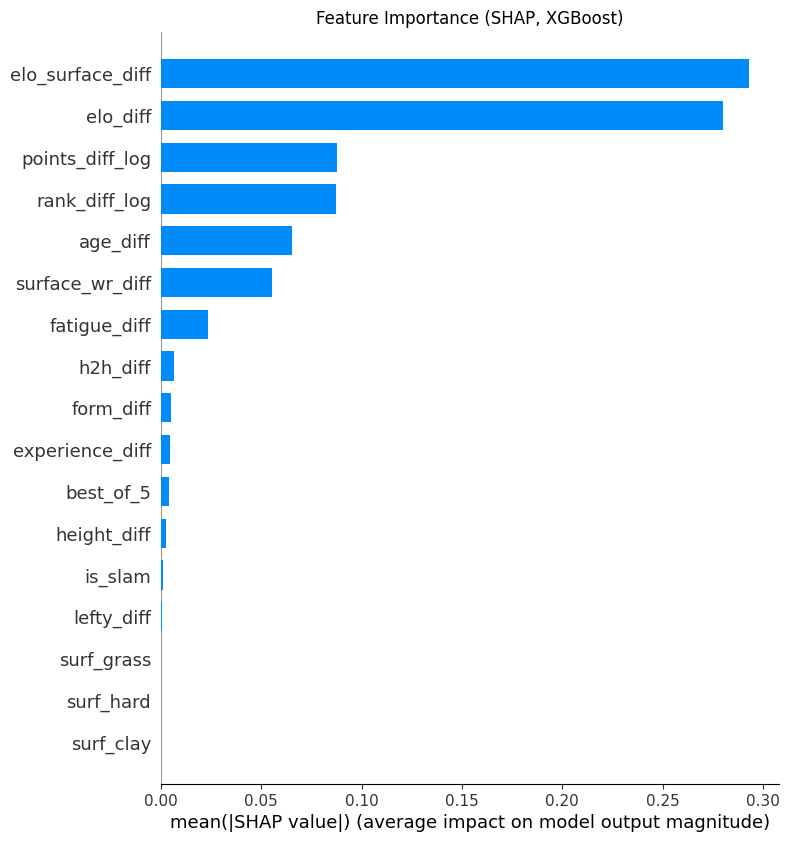

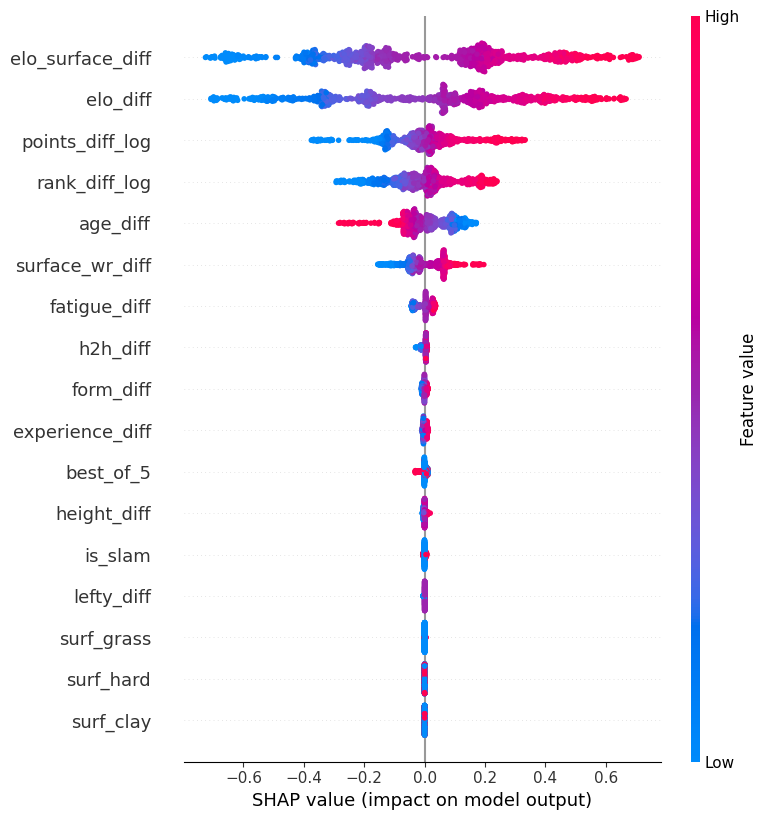

,mean_abs_SHAP
elo_surface_diff,0.2931
elo_diff,0.2799
points_diff_log,0.0875
rank_diff_log,0.0874
age_diff,0.0651
surface_wr_diff,0.0555
fatigue_diff,0.0233
h2h_diff,0.0064
form_diff,0.0048
experience_diff,0.0048


In [17]:
import shap
xgb_clf = final_models["XGBoost"].named_steps["clf"]
sample = X_test.sample(min(1000, len(X_test)), random_state=SEED)
shap_values = shap.TreeExplainer(xgb_clf).shap_values(sample)

shap.summary_plot(shap_values, sample, plot_type="bar", show=False); plt.title(L["shap"])
plt.savefig(f"{OUT_DIR}/fig3_shap_bar_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()
shap.summary_plot(shap_values, sample, show=False)
plt.savefig(f"{OUT_DIR}/fig4_shap_beeswarm_{FIG_LANG}.png", dpi=300, bbox_inches="tight"); plt.show()

# tabel kepentingan fitur (rata-rata |SHAP|) untuk naskah
shap_imp = pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns).sort_values(ascending=False).round(4).rename("mean_abs_SHAP")
shap_imp.to_frame()

## 7. Simpan model

In [7]:
joblib.dump({"models": final_models, "features": FEATURES, "tracker": tr, "results": results},
            f"{SAVE_DIR}/tenis_model.joblib")
results.to_csv(f"{SAVE_DIR}/hasil_evaluasi.csv")
print("Tersimpan di", SAVE_DIR)

Tersimpan di /content/model_tenis


R1 - No 12

In [ ]:
T = X_test.reset_index(drop=True); y = np.asarray(y_test)
grp = {
 "Surface": np.select([T.surf_hard==1, T.surf_clay==1, T.surf_grass==1], ["Hard","Clay","Grass"], "Other"),
 "Event": np.where(T.is_slam==1, "Grand Slam", "Other ATP"),
 "Format": np.where(T.best_of_5==1, "Best of 5", "Best of 3"),
 "Experience gap": pd.qcut(T.experience_diff.abs(), 3, labels=["Small","Medium","Large"]).astype(str).values,
}
elo_pred = (T.elo_diff > 0).astype(int).values
rows = []
for k, g in grp.items():
    for v in pd.unique(g):
        m = (g == v); n = int(m.sum())
        r = {"Context": k, "Group": v, "n": n, "Elo": (elo_pred[m] == y[m]).mean()}
        for name in preds:
            r[name] = (preds[name][m] == y[m]).mean()
        p = r.get("SVM", list(r.values())[-1])
        r["±95% approx"] = 1.96 * np.sqrt(p * (1 - p) / n)
        rows.append(r)
pd.DataFrame(rows).round(4)

,Context,Group,n,Elo,Random Forest,XGBoost,SVM,±95% approx
0,Surface,Hard,4905,0.6465,0.6485,0.6485,0.6548,0.0133
1,Surface,Clay,2730,0.6234,0.6473,0.6443,0.6535,0.0179
2,Surface,Grass,812,0.6638,0.6478,0.6478,0.6576,0.0326
3,Event,Other ATP,6960,0.6263,0.6335,0.6313,0.6404,0.0113
4,Event,Grand Slam,1487,0.7081,0.7162,0.7209,0.7216,0.0228
5,Format,Best of 3,6928,0.6266,0.6332,0.6312,0.6409,0.0113
6,Format,Best of 5,1519,0.7051,0.7156,0.7196,0.7176,0.0226
7,Experience gap,Medium,2815,0.6306,0.6366,0.6369,0.6419,0.0177
8,Experience gap,Large,2816,0.6481,0.6509,0.6523,0.6626,0.0175
9,Experience gap,Small,2816,0.6435,0.6566,0.6520,0.6594,0.0175


In [ ]:
for k,(_,g) in FROZEN.items(): print(k, {pk:[str(x) for x in pv] for pk,pv in g.items()})
pd.DataFrame(fold_params)[["Tahun uji","Model","CV AUC","Parameter"]]

## 7b. Paket hasil untuk naskah

In [ ]:
# Paket keluaran untuk naskah: tabel (CSV), catatan data (JSON), dan gambar -> satu berkas ZIP
import shutil, json, os
import pandas as pd

def _ser(o):                      # ubah apa pun menjadi bentuk yang aman untuk JSON
    if isinstance(o, dict):
        return {str(k): _ser(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [_ser(v) for v in o]
    if isinstance(o, (int, float, str, bool)) or o is None:
        return o
    return str(o)

results_full.to_csv(f"{OUT_DIR}/tabel_hasil_metrik_ci.csv")
ci_table.to_csv(f"{OUT_DIR}/tabel_ci_bootstrap.csv")
diff_table.to_csv(f"{OUT_DIR}/tabel_selisih_akurasi.csv", index=False)
mcnemar_df.to_csv(f"{OUT_DIR}/tabel_mcnemar.csv", index=False)
shap_imp.to_csv(f"{OUT_DIR}/tabel_shap_importance.csv")

# tabel tuning: pakai tuning_table bila ada, kalau tidak pakai fold_table dari checkpoint
_tt = globals().get("tuning_table", globals().get("fold_table"))
pd.DataFrame(_tt).to_csv(f"{OUT_DIR}/tabel_tuning.csv", index=False)

_nama = ["START_YEAR", "END_YEAR", "TRAIN_START_YEAR", "TEST_START_DATE",
         "MIN_PRIOR_MATCHES", "DROP_RETIRED", "N_TUNE", "N_ITER"]
_cfg = {n: globals()[n] for n in _nama if n in globals()}
_cfg["B_bootstrap_akurasi"] = 2000
_cfg["B_bootstrap_auc_per_tahun"] = globals().get("NB", 1000)

paket = {
    "info": _ser(info),
    "parameter_terbaik": _ser(globals().get("fold_params", globals().get("best_params"))),
    "ruang_pencarian": _ser(globals().get("FROZEN", globals().get("models"))),
    "pengaturan": _ser(_cfg),
}
with open(f"{OUT_DIR}/catatan_data_dan_konfigurasi.json", "w", encoding="utf-8") as f:
    json.dump(paket, f, ensure_ascii=False, indent=2)

_save = globals().get("SAVE_DIR", "/content")
zip_path = shutil.make_archive(f"{_save}/hasil_naskah", "zip", OUT_DIR)
print("Isi paket:", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("ZIP tersimpan di:", zip_path)

In [ ]:
import sys, os, platform
from sklearn.model_selection import ParameterGrid
print(sys.version)
print({k: len(ParameterGrid(v[1])) for k, v in FROZEN.items()})
print(sorted(os.listdir(OUT_DIR)))

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
{'Random Forest': 120, 'XGBoost': 4800, 'SVM': 35}
['ad2_scores.joblib', 'ad_scores.joblib', 'catatan_data_dan_konfigurasi.json', 'fig1_confusion_matrix_en.png', 'fig2_roc_kalibrasi_en.png', 'fig3_shap_bar_en.png', 'fig4_shap_beeswarm_en.png', 'fig_kalibrasi_detail_en.png', 'protokol_dibekukan.json', 'tabel_ablasi_kinerja.csv', 'tabel_ablasi_korelasi.csv', 'tabel_ablasi_selisih.csv', 'tabel_ablasi_tuning_ulang.csv', 'tabel_ablasi_tuning_ulang_parameter.csv', 'tabel_ablasi_tuning_ulang_selisih.csv', 'tabel_akurasi_per_tahun.csv', 'tabel_anggaran_pencarian.csv', 'tabel_aplikasi_pemeriksaan_laga_uji.csv', 'tabel_auc_logloss_per_lipatan.csv', 'tabel_auc_per_tahun_ci.csv', 'tabel_auc_per_tahun_selisih.csv', 'tabel_auc_vs_elo_per_tahun.csv', 'tabel_ci_bootstrap.csv', 'tabel_hasil_metrik_ci.csv', 'tabel_imputasi_sensitivitas.csv', 'tabel_imputasi_skenario.csv', 'tabel_imputasi_subset.csv', 'tabel_integritas_akurasi_tanpa_ambigu.csv', 'tabel_i

In [ ]:
import pandas as pd
display(pd.read_csv(f"{OUT_DIR}/tabel_konsistensi_urutan.csv"))

,Model,Rata-rata |p+q-1|,Median,Persentil 95,Maks.,Rata-rata p+q-1 (bias posisi),"Laga |p+q-1| <= 0,01 (%)",Pemenang pilihan berbeda (laga),dari,(%),Akurasi posisi asli,Akurasi posisi dibalik,Akurasi simetris,AUC asli,AUC simetris,Log loss asli,Log loss simetris,Brier asli,Brier simetris
0,Random Forest,0.0181,0.0151,0.0450,0.1103,-0.0069,34.6,302,8447,3.58,0.6480,0.6461,0.6477,0.7142,0.7145,0.6160,0.6159,0.2144,0.2144
1,XGBoost,0.0162,0.0137,0.0397,0.0888,-0.0074,37.3,251,8447,2.97,0.6485,0.6470,0.6479,0.7138,0.7144,0.6171,0.6166,0.2148,0.2146
2,SVM,0.0143,0.0125,0.0350,0.0827,-0.0060,40.5,170,8447,2.01,0.6550,0.6555,0.6549,0.7181,0.7180,0.6157,0.6158,0.2142,0.2142


In [ ]:
import json
for k, v in FROZEN.items(): print(k, v[1])
print(open(f"{OUT_DIR}/protokol_dibekukan.json").read())
for f in ["tabel_kalibrasi_ruang", "tabel_parameter_per_lipatan", "tabel_anggaran_pencarian", "tabel_akurasi_per_tahun"]:
    print("\n==", f); print(pd.read_csv(f"{OUT_DIR}/{f}.csv").to_string())

Random Forest {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 4, 5, 6, 8], 'clf__min_samples_leaf': [10, 20, 40, 80], 'clf__max_features': ['sqrt', 0.3, 0.5]}
XGBoost {'clf__n_estimators': [200, 400, 800, 1600, 100], 'clf__max_depth': [2, 3, 4], 'clf__learning_rate': [0.005, 0.01, 0.02, 0.05, 0.0025], 'clf__subsample': [0.5, 0.7, 0.9, 0.3], 'clf__colsample_bytree': [0.5, 0.7, 0.9, 0.3], 'clf__min_child_weight': [1, 5, 10, 20]}
SVM {'clf__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3.333333], 'clf__gamma': [0.001, 0.003, 0.01, 0.03, 'scale']}
{
  "kalibrasi_data_sampai": "2023-01-01",
  "N_TUNE": 12000,
  "N_ITER": 60,
  "MAX_ROUNDS": 2,
  "ruang": {
    "Random Forest": {
      "clf__n_estimators": [
        "200",
        "400"
      ],
      "clf__max_depth": [
        "3",
        "4",
        "5",
        "6",
        "8"
      ],
      "clf__min_samples_leaf": [
        "10",
        "20",
        "40",
        "80"
      ],
      "clf__max_features": [
        "sqrt",
        "0

In [ ]:
import numpy as np
yv = data.target.values[(data.date >= TEST_START_DATE).values]
print({n: round(float((np.asarray(preds[n]) == yv).mean()), 4) for n in preds})

{'Random Forest': 0.648, 'XGBoost': 0.6471, 'SVM': 0.6547}


In [ ]:
import importlib.metadata as md
print({p: md.version(p) for p in ["scikit-learn","xgboost","shap","pandas","numpy","statsmodels","scipy","gradio"]})

{'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'pandas': '2.2.3', 'numpy': '2.4.6', 'statsmodels': '0.15.0', 'scipy': '1.16.3', 'gradio': '6.31.0'}


In [ ]:
print("raw" in globals(), len(raw) if "raw" in globals() else None)

True 79299


## 8. Aplikasi Gradio

In [16]:
# ===== SEL APLIKASI GRADIO DENGAN PEMERIKSAAN INPUT (R2-14). Pengganti sel Gradio lama. =====
# Butuh: df, data, tr, final_models, FEATURES, build_features, MIN_PRIOR_MATCHES, TRAIN_START_YEAR, TEST_START_DATE (semuanya ada setelah restore checkpoint dan sel Tracker).
# Tiga hal baru: (1) tanggal acuan eksplisit, (2) pemeriksaan pemain dan input (riwayat, usia/ranking basi, kustom tanpa riwayat), (3) deteksi di luar sebaran data latih.
# Bila input tidak didukung, probabilitas TIDAK ditampilkan; bila meragukan, probabilitas ditampilkan dengan peringatan.
import gradio as gr
from sklearn.metrics import log_loss

MIN_MATCHES = MIN_PRIOR_MATCHES          # sama dengan aturan cold-start pada pelatihan
STALE_DAYS = 180                         # laga terakhir pemain lebih lama dari ini: ranking dan usia mungkin usang (peringatan)
MIN_SURF_MATCHES = 5                     # laga di permukaan ini kurang dari ini: Elo/win rate permukaan lemah (peringatan)
MIN_COMBO = 30                           # kombinasi format-level-permukaan yang muncul kurang dari ini pada latih (peringatan; 0 = ditolak)
DATE_CAUTION_DAYS, DATE_BLOCK_DAYS = 30, 180      # tanggal laga setelah batas data: peringatan, lalu ditolak
Q_TAIL = (0.005, 0.995)                  # ekor sebaran latih per fitur (peringatan)
LEVELS = {"Grand Slam": True, "Other tournaments": False}
SURFACES = ["Hard", "Clay", "Grass"]

REF_DATE = df.tourney_date.max()                         # tanggal acuan status pemain = tanggal turnamen terakhir pada data
_trn = data[(data.date >= f"{TRAIN_START_YEAR}-01-01") & (data.date < TEST_START_DATE)]      # data latih final_models (lipatan 1)
try: BEST_MODEL = results.loc[list(final_models)].LogLoss.idxmin()
except Exception: BEST_MODEL = min(final_models, key=lambda m: log_loss(y_test, probas[m]))

# ---------- referensi sebaran data latih untuk deteksi di luar sebaran ----------
_BIN = ["best_of_5", "is_slam", "surf_hard", "surf_clay", "surf_grass"]
_cont = [f for f in FEATURES if f not in _BIN]
_Xc = _trn[_cont].values.astype(float); _mu = _Xc.mean(0); _P = np.linalg.pinv(np.cov(_Xc, rowvar=False))
_lo, _hi = _Xc.min(0), _Xc.max(0); _ql, _qh = np.quantile(_Xc, Q_TAIL[0], axis=0), np.quantile(_Xc, Q_TAIL[1], axis=0)
_mdt = np.sqrt(np.einsum("ij,jk,ik->i", _Xc - _mu, _P, _Xc - _mu)); MD_CAUTION, MD_BLOCK = np.quantile(_mdt, [0.99, 0.999])
_combo = _trn.groupby(_BIN).size().to_dict()
_d_ = df[df.tourney_date >= f"{TRAIN_START_YEAR}-01-01"]
AGE_R = tuple(pd.concat([_d_.winner_age, _d_.loser_age]).dropna().quantile([0.001, 0.999]))
HT_R = tuple(pd.concat([_d_.winner_ht, _d_.loser_ht]).dropna().quantile([0.001, 0.999]))
RANK_MAX = float(pd.concat([_d_.winner_rank, _d_.loser_rank]).dropna().max())
_el = [tr.elo[p] for p in tr.n if tr.n[p] >= MIN_MATCHES]; ELO_R = (min(_el), max(_el))

# ---------- daftar pemain terdaftar: >= MIN_MATCHES laga dan bermain dalam 2 tahun terakhir data ----------
active = {pid: b["name"] for pid, b in tr.bio.items() if tr.n[pid] >= MIN_MATCHES and (REF_DATE - b["last_date"]).days <= 730}
name_to_id = {n: pid for pid, n in sorted(active.items(), key=lambda x: -tr.elo[x[0]])}
player_names = list(name_to_id)

def profile_registered(name, surface):
    """Status pemain pada tanggal acuan: Elo, form, win rate, kelelahan 14 hari dan jumlah laga dari Tracker;
    ranking, poin, tinggi, tangan dari laga terakhir; usia = usia pada laga terakhir ditambah selang waktu sampai tanggal acuan."""
    pid = name_to_id[name]; b = tr.bio[pid]; gap = (REF_DATE - b["last_date"]).days
    p = dict(rank=b["rank"], points=b["points"], age=(b["age"] + gap / 365.25) if pd.notna(b["age"]) else np.nan,
             ht=b["ht"], lefty=float(b["hand"] == "L"))
    p.update(tr.dynamic(pid, surface, REF_DATE))
    return pid, p, dict(n=tr.n[pid], last=b["last_date"], gap=gap, surf_n=tr.n_s[(pid, surface)])

def profile_custom(elo, rank, age, ht, hand, form_pct, surf_wr_pct, fatigue_h, n_matches):
    return dict(rank=rank if rank and rank > 0 else np.nan, points=np.nan, age=age, ht=ht, lefty=float(hand == "L"),
                elo=elo, elo_s=elo, form=(form_pct or 0) / 100, surf_wr=(surf_wr_pct or 0) / 100,
                fatigue=(fatigue_h or 0) * 60, exp=int(n_matches or 0))

def predict_pair(p1, p2, surface, best_of, is_slam, h2h_diff, model_name):
    """Rata-rata dua urutan (A,B) dan (B,A) agar hasil tidak bergantung pada urutan pemain."""
    m = final_models[model_name]
    Xa = pd.DataFrame([build_features(p1, p2, surface, best_of, is_slam, h2h_diff)])[FEATURES]
    Xb = pd.DataFrame([build_features(p2, p1, surface, best_of, is_slam, -h2h_diff)])[FEATURES]
    return float((m.predict_proba(Xa)[0, 1] + 1 - m.predict_proba(Xb)[0, 1]) / 2)

# ---------- pemeriksaan ----------
def check_registered(name, m, surface, p):
    B, C = [], []
    if m["n"] < MIN_MATCHES: B.append(f"{name}: only {m['n']} recorded matches (minimum {MIN_MATCHES}); the models were trained only on players with at least {MIN_MATCHES} earlier matches.")
    if m["gap"] > STALE_DAYS: C.append(f"{name}: last recorded match on {m['last'].date()}, {m['gap']} days before the reference date; ranking and height come from that match and may be outdated, and age was extrapolated.")
    if pd.isna(p["rank"]): C.append(f"{name}: no ranking on record; the ranking difference is set to 0, as in training.")
    if m["surf_n"] < MIN_SURF_MATCHES: C.append(f"{name}: only {m['surf_n']} recorded matches on {surface}; the surface Elo and win rate rest on little data.")
    return B, C

def check_custom(name, p):
    B, C = [], ["{}: profile entered by the user; it is not verified against match records.".format(name)]
    if not p["exp"] or p["exp"] < MIN_MATCHES or pd.isna(p["elo"]): B.append(f"{name}: no validated match history (fewer than {MIN_MATCHES} matches recorded, or Elo missing); the models were trained only on players with at least {MIN_MATCHES} earlier matches.")
    for lab, v, (a, b_) in (("Elo", p["elo"], ELO_R), ("Age", p["age"], AGE_R), ("Height", p["ht"], HT_R)):
        if pd.isna(v): B.append(f"{name}: {lab} is missing.")
        elif not (a <= v <= b_): B.append(f"{name}: {lab} {v:.0f} is outside the range of players in the data ({a:.0f} to {b_:.0f}).")
    if pd.notna(p["rank"]) and p["rank"] > RANK_MAX: B.append(f"{name}: ranking {p['rank']:.0f} is worse than any ranking in the data (maximum {RANK_MAX:.0f}).")
    return B, C

def check_features(f, surface, best_of, is_slam):
    B, C = [], []
    x = np.array([f[c] for c in _cont], float)
    out = [c for c, v, a, b_ in zip(_cont, x, _lo, _hi) if not (a <= v <= b_)]
    tail = [c for c, v, a, b_ in zip(_cont, x, _ql, _qh) if not (a <= v <= b_) and c not in out]
    if out: B.append("Outside the range seen in training: " + ", ".join(out) + ".")
    if tail: C.append("In the extreme tail of the training distribution (outside its 0.5% to 99.5% range): " + ", ".join(tail) + ".")
    d = float(np.sqrt((x - _mu) @ _P @ (x - _mu)))
    if d > MD_BLOCK: B.append(f"The combination of the 12 continuous features is more unusual than 99.9% of training matches (Mahalanobis distance {d:.1f}).")
    elif d > MD_CAUTION: C.append(f"The combination of the 12 continuous features is more unusual than 99% of training matches (Mahalanobis distance {d:.1f}).")
    k = _combo.get((int(best_of == 5), int(is_slam), int(surface == "Hard"), int(surface == "Clay"), int(surface == "Grass")), 0)
    if k == 0: B.append("This combination of match format, tournament level, and surface never occurred in training (Grand Slam men's matches are best-of-5).")
    elif k < MIN_COMBO: C.append(f"This combination of format, level, and surface occurred in only {k} training matches.")
    return B, C

def check_date(txt):
    if txt is None or str(txt).strip() == "": return [], []
    try: dt = pd.Timestamp(str(txt).strip())
    except Exception: return [f"Match date '{txt}' is not a valid date (use YYYY-MM-DD)."], []
    k = (dt - REF_DATE).days
    if k < 0: return [f"The state of the players is available only at the data cut-off ({REF_DATE.date()}); earlier dates cannot be reproduced here."], []
    if k > DATE_BLOCK_DAYS: return [f"The match date is {k} days after the data cut-off ({REF_DATE.date()}); Elo, form, and fatigue would be badly out of date."], []
    if k > DATE_CAUTION_DAYS: return [], [f"The match date is {k} days after the data cut-off ({REF_DATE.date()}); matches played since then are not in the Elo, form, and fatigue."]
    return [], []

def feature_table(f):
    rows = []
    for c in FEATURES:
        v = f[c]
        if c in _cont:
            i = _cont.index(c); st = "yes" if _ql[i] <= v <= _qh[i] else ("OUTSIDE" if not (_lo[i] <= v <= _hi[i]) else "tail")
            rows.append([c, round(float(v), 3), f"{_ql[i]:.2f} to {_qh[i]:.2f}", st])
        else: rows.append([c, int(v), "0 or 1", "yes"])
    return pd.DataFrame(rows, columns=["Feature (17)", "Value", "Training range (0.5% to 99.5%)", "Within range"])

def compare_table(n1, p1, n2, p2):
    def _r(v, k=0): return "-" if v is None or pd.isna(v) else (round(v, k) if k else int(round(v)))
    def fmt(p): return [_r(p["elo"]), _r(p["elo_s"]), _r(p.get("rank")), f"{p['form']:.0%}",
                        f"{p['surf_wr']:.0%}", round(p["fatigue"] / 60, 1), int(p["exp"])]
    return pd.DataFrame({"Factor": ["Elo (general)", "Elo (surface)", "Ranking", "Form (last 10)", "Surface win rate", "Hours played (14 days)", "Matches"],
                         n1: fmt(p1), n2: fmt(p2)})

def plot_prob(n1, n2, prob):
    fig, ax = plt.subplots(figsize=(7, 1.9))
    ax.barh(0, prob, color="#2a9d8f"); ax.barh(0, 1 - prob, left=prob, color="#e76f51")
    ax.text(prob / 2, 0, f"{n1}\n{prob:.1%}", ha="center", va="center", color="white", fontweight="bold")
    ax.text(prob + (1 - prob) / 2, 0, f"{n2}\n{1 - prob:.1%}", ha="center", va="center", color="white", fontweight="bold")
    ax.axvline(0.5, color="white", ls="--", lw=1); ax.set_xlim(0, 1); ax.axis("off")
    ax.set_title("Win probability", fontsize=11); plt.tight_layout(); return fig

def plot_elo(id1, n1, id2, n2):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for pid, n in ((id1, n1), (id2, n2)):
        h = tr.elo_hist[pid]
        if h: ax.plot([d for d, _ in h], [e for _, e in h], label=n)
    ax.set(title="Elo trend", ylabel="Elo"); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); return fig

def _report(n1, n2, prob, B, C, head, foot):
    if B: return ("### No probability shown: unsupported input\n" + "\n".join(f"- {m}" for m in B) +
                  ("\n\nAlso noted:\n" + "\n".join(f"- {m}" for m in C) if C else "") +
                  "\n\n*The models were trained on ATP tour matches of players with at least 10 earlier matches; outside that population an estimate would be an extrapolation.*")
    s = f"### {n1}: **{prob:.1%}**  vs  {n2}: **{1 - prob:.1%}**\n{head}\n\n"
    s += ("**Use with caution:**\n" + "\n".join(f"- {m}" for m in C) + "\n\n") if C else "**Status:** all checks passed.\n\n"
    return s + foot

_STATE = f"Player states are those after the last match in the data ({REF_DATE.date()}). Models trained on {len(_trn):,} matches from {_trn.date.min().date()} to {_trn.date.max().date()}."

def run_registered(n1, n2, surface, level, best_of, model_name, date_txt):
    if not n1 or not n2 or n1 == n2: return None, None, "Pick two different players.", None, None
    id1, p1, m1 = profile_registered(n1, surface); id2, p2, m2 = profile_registered(n2, surface)
    h2h = tr.h2h[(id1, id2)] - tr.h2h[(id2, id1)]
    f = build_features(p1, p2, surface, int(best_of), LEVELS[level], h2h)
    B, C = [], []
    for nm, m, p in ((n1, m1, p1), (n2, m2, p2)): b, c = check_registered(nm, m, surface, p); B += b; C += c
    for chk in (check_features(f, surface, int(best_of), LEVELS[level]), check_date(date_txt)): B += chk[0]; C += chk[1]
    prob = None if B else predict_pair(p1, p2, surface, int(best_of), LEVELS[level], h2h, model_name)
    head = f"Model: {model_name} | Surface: {surface} | Head-to-head (win difference): {h2h:+d}"
    foot = f"*{_STATE} For academic use, not for betting.*"
    return (None if B else plot_prob(n1, n2, prob)), plot_elo(id1, n1, id2, n2), _report(n1, n2, prob, B, C, head, foot), compare_table(n1, p1, n2, p2), feature_table(f)

def run_custom(n1, e1, r1, a1, h1, hd1, f1, s1, fat1, m1, n2, e2, r2, a2, h2, hd2, f2, s2, fat2, m2, surface, level, best_of, model_name, date_txt):
    n1, n2 = n1 or "Player A", n2 or "Player B"
    p1 = profile_custom(e1, r1, a1, h1, hd1, f1, s1, fat1, m1); p2 = profile_custom(e2, r2, a2, h2, hd2, f2, s2, fat2, m2)
    B, C = [], []
    for nm, p in ((n1, p1), (n2, p2)): b, c = check_custom(nm, p); B += b; C += c
    f = None
    if not any(pd.isna(p[k]) for p in (p1, p2) for k in ("elo", "age", "ht")):
        f = build_features(p1, p2, surface, int(best_of), LEVELS[level], 0)
        b, c = check_features(f, surface, int(best_of), LEVELS[level]); B += b; C += c
    b, c = check_date(date_txt); B += b; C += c
    prob = None if B else predict_pair(p1, p2, surface, int(best_of), LEVELS[level], 0, model_name)
    head = f"Model: {model_name} | Surface: {surface} | Head-to-head set to 0 and ranking points missing (as in training when unknown)."
    foot = "*Estimate for a user-entered profile; not validated for amateur players. " + _STATE + "*"
    return (None if B else plot_prob(n1, n2, prob)), _report(n1, n2, prob, B, C, head, foot), compare_table(n1, p1, n2, p2), (feature_table(f) if f else None)

def player_inputs(tag, default_name):
    with gr.Column():
        gr.Markdown(f"**{tag}**")
        return [gr.Textbox(label="Name", value=default_name),
                gr.Number(label="Internal Elo (new player = 1500)", value=1500),
                gr.Number(label="Ranking (leave empty if none)", value=None),
                gr.Number(label="Age", value=25), gr.Number(label="Height (cm)", value=175),
                gr.Radio(["R", "L"], label="Dominant hand", value="R"),
                gr.Slider(0, 100, value=50, label="Win % in last 10 matches"),
                gr.Slider(0, 100, value=50, label="Win % on this surface"),
                gr.Number(label="Hours played in last 14 days", value=0),
                gr.Number(label="Recorded matches (at least 10)", value=15)]

with gr.Blocks(title="Tennis Match Winner Prediction") as demo:
    gr.Markdown("# Tennis Match Winner Prediction\nRandom Forest, XGBoost, and SVM | ATP data (Jeff Sackmann)\n\n" + _STATE)
    with gr.Row():
        surface = gr.Radio(SURFACES, label="Surface", value="Hard")
        level = gr.Radio(list(LEVELS), label="Tournament level", value="Other tournaments")
        best_of = gr.Radio([3, 5], label="Best of", value=3)
        model_name = gr.Dropdown(list(final_models), label="Model", value=BEST_MODEL)
        date_in = gr.Textbox(label="Match date (YYYY-MM-DD)", value=str(REF_DATE.date()))
    with gr.Tab("Registered players"):
        with gr.Row():
            d1 = gr.Dropdown(player_names, label="Player A", value=player_names[0])
            d2 = gr.Dropdown(player_names, label="Player B", value=player_names[1])
        b1 = gr.Button("Predict", variant="primary")
        t1 = gr.Markdown(); pl1 = gr.Plot(); pl2 = gr.Plot(); tb1 = gr.Dataframe(label="Factor comparison"); tf1 = gr.Dataframe(label="The 17 features given to the model")
        b1.click(run_registered, [d1, d2, surface, level, best_of, model_name, date_in], [pl1, pl2, t1, tb1, tf1])
    with gr.Tab("Custom players"):
        with gr.Row():
            in1 = player_inputs("Player A", "Player A"); in2 = player_inputs("Player B", "Player B")
        b2 = gr.Button("Predict", variant="primary")
        t2 = gr.Markdown(); pl3 = gr.Plot(); tb2 = gr.Dataframe(label="Factor comparison"); tf2 = gr.Dataframe(label="The 17 features given to the model")
        b2.click(run_custom, in1 + in2 + [surface, level, best_of, model_name, date_in], [pl3, t2, tb2, tf2])

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://405c678f011938558e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ===== SEL AppCheck: BERAPA BANYAK LAGA UJI YANG AKAN DITOLAK ATAU DIBERI PERINGATAN OLEH PEMERIKSAAN APLIKASI (R2-14). Jalankan SETELAH sel aplikasi (butuh _cont, _lo, _hi, _ql, _qh, _mu, _P, MD_*, _combo, test, preds). =====
from IPython.display import display
_Xt = test[_cont].values.astype(float)
_out = ((_Xt < _lo) | (_Xt > _hi)).any(1)
_tail = ((_Xt < _ql) | (_Xt > _qh)).any(1) & ~_out
_mdv = np.sqrt(np.einsum("ij,jk,ik->i", _Xt - _mu, _P, _Xt - _mu))
_kc = np.array([_combo.get(tuple(int(v) for v in r), 0) for r in test[_BIN].values])
_blk = _out | (_mdv > MD_BLOCK) | (_kc == 0)
_cau = ~_blk & (_tail | (_mdv > MD_CAUTION) | (_kc < MIN_COMBO))
_st = np.where(_blk, "Refused", np.where(_cau, "Caution", "Supported"))
_yv = test.target.values; _yrs = test.date.dt.year.values
print(f"Batas pada data latih ({len(_trn):,} laga, {TRAIN_START_YEAR}-2022): jarak Mahalanobis 99% = {MD_CAUTION:.2f}, 99.9% = {MD_BLOCK:.2f}")
print(f"Rentang Elo pemain = {ELO_R[0]:.0f} sampai {ELO_R[1]:.0f}; usia {AGE_R[0]:.1f} sampai {AGE_R[1]:.1f}; tinggi {HT_R[0]:.0f} sampai {HT_R[1]:.0f}; ranking maks {RANK_MAX:.0f}")
_rows = []
for lab in ("Supported", "Caution", "Refused"):
    m = _st == lab
    _rows.append({"Status": lab, "Matches": int(m.sum()), "Share (%)": round(100 * m.mean(), 2),
                  **{f"Accuracy {n} (%)": (round(100 * float((preds[n][m] == _yv[m]).mean()), 2) if m.sum() else np.nan) for n in preds}})
t_appchk = pd.DataFrame(_rows); display(t_appchk)
_by = pd.crosstab(_yrs, _st); display(_by)
_why = pd.Series({"Feature outside the range seen in training": int(_out.sum()), "Mahalanobis distance above the 99.9% limit": int((_mdv > MD_BLOCK).sum()),
                  "Format-level-surface combination absent in training": int((_kc == 0).sum()), "Caution only: extreme tail or Mahalanobis above 99%": int(_cau.sum())})
display(_why.to_frame("Test matches"))
t_appchk.to_csv(f"{OUT_DIR}/tabel_aplikasi_pemeriksaan_laga_uji.csv", index=False)
print("Tersimpan: tabel_aplikasi_pemeriksaan_laga_uji.csv")

Batas pada data latih (30,192 laga, 2010-2022): jarak Mahalanobis 99% = 6.76, 99.9% = 10.77
Rentang Elo pemain = 1153 sampai 2405; usia 17.3 sampai 39.8; tinggi 168 sampai 211; ranking maks 2171


,Status,Matches,Share (%),Accuracy Random Forest (%),Accuracy XGBoost (%),Accuracy SVM (%)
0,Supported,7906,93.60,64.12,63.99,64.69
1,Caution,527,6.24,74.95,75.33,77.04
2,Refused,14,0.17,71.43,71.43,71.43


col_0,Caution,Refused,Supported
row_0,,,
2023,153,2,2233
2024,165,7,2403
2025,145,5,2150
2026,64,0,1120


,Test matches
Feature outside the range seen in training,3
Mahalanobis distance above the 99.9% limit,11
Format-level-surface combination absent in training,0
Caution only: extreme tail or Mahalanobis above 99%,527


Tersimpan: tabel_aplikasi_pemeriksaan_laga_uji.csv
